# Exploració de dades
Exploració de dades inicials. Inclou plots individuals (P0002) i grand average sobre tots els subjectes. Es repliquen plots similars que a l'article de Binocular Rivarly: Evaluating the Role of Theta Power as 
a Neural Index of Conflict (A. Drew, J. San-Segundo, S. Soto-Faraco, M. Torralba Cuello), entre altres.

## Objectius d'aquest notebook
1. Executar la inicialització compartida per carregar imports, rutes, constants i funcions reutilitzables.
2. Carregar un subjecte de treball per a exploració individual i validar disponibilitat de canals/condicions.
3. Construir la capa d'EDA conductual i de dominància amb les funcions comunes.
4. Generar visualitzacions individuals (ERP, time-courses theta/alpha, TFR diferencial) amb convencions comunes.
5. Executar el recorregut grand average sobre tots els subjectes amb els mateixos paràmetres globals.
6. Reportar resultats de qualitat de dades i consistència amb l'article de referència.

In [87]:
import gc
import importlib.util
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, Rectangle
import mne
import numpy as np
import pandas as pd
from scipy.signal import stft
from scipy.stats import ConstantInputWarning, binomtest, spearmanr


try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive", force_remount=False)
    required_packages = ["mne", "imbalanced-learn", "xgboost", "lightgbm"]
    for pkg in required_packages:
        if importlib.util.find_spec(pkg.replace("-", "_")) is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*does not conform to MNE naming conventions.*",
)
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*events passed to the Epochs constructor are not chronologically ordered.*",
)
mne.set_log_level("WARNING")

In [ ]:
if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
META_DIR = PROJECT_DIR / "02_Data" / "02_meta"

ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
EXPLORATION_DIR = ANALYSIS_ROOT / "01_exploracio"
RESULTS_DIR = EXPLORATION_DIR
FIGURES_DIR = EXPLORATION_DIR / "figures"
TABLES_DIR = EXPLORATION_DIR / "tables"
for folder in (DATA_DIR, META_DIR, ANALYSIS_ROOT, EXPLORATION_DIR, FIGURES_DIR, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

# Constants compartides
COND_EVENTS_CODES = {
    "Congruent": [1, 2],
    "Incongruent_Pur": [3, 4, 5, 6],
    "Incongruent_Mixt": [7, 8],
    "Incongruent": [3, 4, 5, 6, 7, 8],
    "Errors": [9, 10, 11, 12],
}

EVENT_TO_LABEL = {
    1: "CRP",
    2: "CGP",
    3: "IPR",
    4: "IPR",
    5: "IPG",
    6: "IPG",
    7: "IM",
    8: "IM",
    9: "CRG",
    10: "CGG",
    11: "CRM",
    12: "CGM",
}

LABELS = {
    "Congruent": "Congruent (C)",
    "Incongruent_Pur": "Incongruent Pur (IP)",
    "Incongruent_Mixt": "Incongruent Mixt (IM)",
    "Incongruent": "Incongruent (I)",
    "Errors": "Errors",
}
COLORS = {
    "Congruent": "steelblue",
    "Incongruent_Pur": "darkorange",
    "Incongruent_Mixt": "forestgreen",
    "Incongruent": "slategray",
    "Errors": "firebrick",
}

LABELS_ORDER = ["CRP", "CGP", "IPR", "IPG", "IM", "CRM", "CRG", "CGM", "CGG"]

TRIAL_START = -0.74
TRIAL_END = 1.5
FULL_TRIAL = (TRIAL_START, TRIAL_END)
BASELINE = (-0.74, -0.24)
ERP_WINDOW = (0.5, 1.0)

FREQS_THETA = np.arange(5, 8)
FREQS_ALPHA = np.arange(8, 13)
FREQS_WIDE = np.arange(2, 21)

ROI_FRONTAL = ["Fz", "FCz", "Cz"]
ROI_PO = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"]

EYE_LEFT_CODES = [3, 6]
EYE_RIGHT_CODES = [4, 5]
COLOR_RED_CODES = [1, 3, 4, 10]
COLOR_GREEN_CODES = [2, 5, 6, 9]
ERROR_CODES = [9, 10, 11, 12]

STFT_WINDOW_SEC = 0.5
STFT_STEP_SEC = 0.02

N_BINS = 10
BOOT_N = 3000
SMOOTH_WIN = 5

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Directori de dades: {DATA_DIR}")
print(f"Resultats d'exploració: {EXPLORATION_DIR}")
print(f"Fitxers .fif trobats: {len(DATA_FILES)}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Directori de dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Resultats d'exploració: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio
Fitxers .fif trobats: 47


In [88]:
def load_subject(fif_path):
    try:
        ep = mne.read_epochs(str(fif_path), preload=False, verbose=False)
    except OSError:
        ep = mne.read_epochs(Path(fif_path).resolve().as_posix(), preload=False, verbose=False)
    ep.load_data()

    for ch in ep.info["chs"]:
        if ch["unit"] == 0:
            ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
            ch["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

    # Conversió de microvolts a volts (µV -> V)
    ep._data *= 1e-6

    mapping = {ch_name: "eeg" for ch_name in ep.ch_names}
    ep.set_channel_types(mapping, on_unit_change="ignore")

    # Hi havia molts errors i inconsistències amb event_X entre diferents subjectes
    # Ara ho fem a partir dels codis numèrics reals dels esdeveniments presents a cada subjecte
    # Els tags són el ground truth i sí que són correctes. Ara event_id tindrà el codi "id"
    ep.event_id = {f"event_{code}": code for code in np.unique(ep.events[:, 2])}
    cond = {}
    for cond_name, codes_list in COND_EVENTS_CODES.items():
        valid_names = [f"event_{code}" for code in codes_list if f"event_{code}" in ep.event_id]
        if valid_names:
            cond[cond_name] = ep[valid_names]
    return ep, cond


def row_binom_ci(successes, total):
    if int(total) <= 0:
        return np.nan, np.nan
    bt = binomtest(int(successes), n=int(total), p=0.5, alternative="two-sided")
    ci = bt.proportion_ci(confidence_level=0.95, method="exact")
    return ci.low, ci.high


def build_behavior_dominance_summary(data_dir=DATA_DIR):
    """Calcula mètriques de dominància conductual i desa sèries per reutilitzar-les."""
    subject_rows = []
    comptes_classes = {cond: 0 for cond in COND_EVENTS_CODES}

    for fif_path in sorted(data_dir.glob("*.fif")):
        ep = mne.read_epochs(fif_path, preload=False, verbose=False)
        events = ep.events[:, 2]

        for cond_name, codes in COND_EVENTS_CODES.items():
            comptes_classes[cond_name] += int(np.isin(events, codes).sum())

        counts = {k: 0 for k in ["CRP", "CRM", "CRG", "CGP", "CGM", "CGG", "IPR", "IPG", "IM"]}
        for ev in events:
            if ev in EVENT_TO_LABEL:
                counts[EVENT_TO_LABEL[ev]] += 1

        left_eye = int(np.sum(np.isin(events, EYE_LEFT_CODES)))
        right_eye = int(np.sum(np.isin(events, EYE_RIGHT_CODES)))
        n_eye = left_eye + right_eye
        eye_index = (left_eye - right_eye) / n_eye if n_eye > 0 else np.nan
        p_eye = binomtest(left_eye, n=n_eye, p=0.5).pvalue if n_eye > 0 else np.nan
        ci_ull_low, ci_ull_high = row_binom_ci(left_eye, n_eye)

        red_count = int(np.sum(np.isin(events, COLOR_RED_CODES)))
        green_count = int(np.sum(np.isin(events, COLOR_GREEN_CODES)))
        n_color = red_count + green_count
        color_index = (red_count - green_count) / n_color if n_color > 0 else np.nan
        p_color = binomtest(red_count, n=n_color, p=0.5).pvalue if n_color > 0 else np.nan
        ci_color_low, ci_color_high = row_binom_ci(red_count, n_color)

        left_red = int(np.sum(events == 3))
        left_green = int(np.sum(events == 6))
        right_red = int(np.sum(events == 4))
        right_green = int(np.sum(events == 5))

        row = {
            "subjecte": fif_path.stem,
            **counts,
            "left_eye": left_eye,
            "right_eye": right_eye,
            "n_ull": n_eye,
            "index_dominancia_ull": eye_index,
            "p_ull": p_eye,
            "ci95_ull_low": ci_ull_low,
            "ci95_ull_high": ci_ull_high,
            "red_count": red_count,
            "green_count": green_count,
            "n_color": n_color,
            "index_dominancia_color": color_index,
            "p_color": p_color,
            "ci95_color_low": ci_color_low,
            "ci95_color_high": ci_color_high,
            "left_red": left_red,
            "left_green": left_green,
            "right_red": right_red,
            "right_green": right_green,
        }
        subject_rows.append(row)

    df = pd.DataFrame(subject_rows).sort_values("subjecte").reset_index(drop=True)
    label_counts = {k: int(df[k].sum()) for k in ["CRP", "CRM", "CRG", "CGP", "CGM", "CGG", "IPR", "IPG", "IM"]}
    globals_summary = {
        "left_global": int(df["left_eye"].sum()),
        "right_global": int(df["right_eye"].sum()),
        "red_global": int(df["red_count"].sum()),
        "green_global": int(df["green_count"].sum()),
    }
    return df, comptes_classes, label_counts, globals_summary


def stft_power_db(ep, picks, freqs=FREQS_WIDE, baseline=BASELINE):
    x = ep.copy().pick(picks).get_data().astype(np.float32, copy=False)
    sfreq = ep.info["sfreq"]

    nperseg = int(round(STFT_WINDOW_SEC * sfreq))
    hop = int(round(STFT_STEP_SEC * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    f, t, z = stft(
        x,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    power = np.abs(z).astype(np.float32) ** 2

    freq_targets = np.asarray(freqs)
    freq_idx = np.array([np.argmin(np.abs(f - fr)) for fr in freq_targets])
    f_sel = f[freq_idx]
    power = power[:, :, freq_idx, :]

    times = ep.tmin + t
    bmask = (times >= baseline[0]) & (times <= baseline[1])
    b = power[..., bmask].mean(axis=-1, keepdims=True)
    power_db = 10 * np.log10((power + 1e-20) / (b + 1e-20))
    return f_sel, times, power_db.astype(np.float32)


def stft_band_timecourse(ep, picks, band, baseline=BASELINE):
    f, times, power_db = stft_power_db(ep, picks=picks, freqs=FREQS_WIDE, baseline=baseline)
    fmask = (f >= band[0]) & (f <= band[1])
    band_db = power_db[:, :, fmask, :]
    mean_ts = band_db.mean(axis=(0, 1, 2))
    sem_ts = band_db.std(axis=(0, 1, 2)) / np.sqrt(band_db.shape[0])
    return times, mean_ts, sem_ts


def stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4):
    ch_names = ep.ch_names
    n_ch = len(ch_names)
    acc = None
    f_ref, t_ref = None, None

    for start in range(0, n_ch, ch_block):
        picks = ch_names[start : start + ch_block]
        f, t, p_db = stft_power_db(ep, picks=picks, freqs=freqs, baseline=baseline)
        block_mean = p_db.mean(axis=(0, 1))

        if acc is None:
            acc = np.zeros_like(block_mean)
            f_ref, t_ref = f, t

        acc += block_mean * len(picks)
        del p_db, block_mean
        gc.collect()

    return f_ref, t_ref, acc / n_ch


def undersample_binary(x_in, y_in, random_state=42):
    classes, counts = np.unique(y_in, return_counts=True)
    if len(classes) < 2:
        return x_in, y_in, np.arange(len(y_in))

    n_min = counts.min()
    rng = np.random.default_rng(random_state)
    selected_idx = []
    for cls in classes:
        cls_idx = np.where(y_in == cls)[0]
        sampled = rng.choice(cls_idx, size=n_min, replace=False)
        selected_idx.extend(sampled.tolist())

    selected_idx = np.array(selected_idx)
    rng.shuffle(selected_idx)
    return x_in[selected_idx], y_in[selected_idx], selected_idx

In [91]:
# Funcions específiques de l'anàlisi d'exploració
def compute_fatigue_metrics(data_dir=DATA_DIR):
    """Calcula mètriques de cansament per subjecte i desa sèries ERP per reutilitzar-les."""
    rows_fatigue = []
    subject_amp_series = {}
    skipped_subjects = []

    for fif_path in sorted(data_dir.glob("*.fif")):
        subj = fif_path.stem
        try:
            ep_all, _ = load_subject(fif_path)
        except Exception as err:
            skipped_subjects.append((subj, str(err)))
            print(f"[WARN] Subjecte omès ({subj}): {err}")
            continue
        events = ep_all.events[:, 2]
        n_trials = len(events)

        if n_trials < 3:
            del ep_all
            gc.collect()
            continue

        trial_idx = np.arange(1, n_trials + 1)
        progress = np.linspace(0.0, 1.0, n_trials)
        bins = np.array_split(np.arange(n_trials), N_BINS)

        is_error = np.isin(events, ERROR_CODES).astype(float)
        err_binned = [float(is_error[idx].mean()) for idx in bins]
        err_delta = err_binned[-1] - err_binned[0]
        err_slope = np.polyfit(progress, is_error, 1)[0] if n_trials > 1 else np.nan

        if n_trials > 1 and np.unique(is_error).size > 1:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConstantInputWarning)
                rho_err, p_err = spearmanr(trial_idx, is_error)
        else:
            rho_err, p_err = np.nan, np.nan

        roi_ok = [ch for ch in ROI_FRONTAL if ch in ep_all.ch_names]
        if len(roi_ok) == 0:
            del ep_all
            gc.collect()
            continue

        erp_data = ep_all.get_data(picks=roi_ok, tmin=ERP_WINDOW[0], tmax=ERP_WINDOW[1]) * 1e6
        erp_amp = np.mean(np.abs(erp_data), axis=(1, 2))
        subject_amp_series[subj] = erp_amp

        amp_binned = [float(erp_amp[idx].mean()) for idx in bins]
        amp_delta = amp_binned[-1] - amp_binned[0]
        amp_slope = np.polyfit(progress, erp_amp, 1)[0] if n_trials > 1 else np.nan

        if n_trials > 1 and np.unique(erp_amp).size > 1:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConstantInputWarning)
                rho_amp, p_amp = spearmanr(trial_idx, erp_amp)
        else:
            rho_amp, p_amp = np.nan, np.nan

        rows_fatigue.append(
            {
                "subjecte": subj,
                "n_trials": n_trials,
                "error_t1": err_binned[0],
                "error_t2": err_binned[1],
                "error_t3": err_binned[2],
                "error_delta_t3_t1": err_delta,
                "error_slope": err_slope,
                "error_rho": rho_err,
                "error_p": p_err,
                "erp_amp_t1_uV": amp_binned[0],
                "erp_amp_t2_uV": amp_binned[1],
                "erp_amp_t3_uV": amp_binned[2],
                "erp_amp_delta_t3_t1_uV": amp_delta,
                "erp_amp_slope": amp_slope,
                "erp_amp_rho": rho_amp,
                "erp_amp_p": p_amp,
            }
        )

        del ep_all, erp_data
        gc.collect()

    if skipped_subjects:
        print(f"[INFO] Subjectes omesos per error de lectura: {len(skipped_subjects)}")

    return pd.DataFrame(rows_fatigue), subject_amp_series

## Càrrega de dades
Aquesta cel·la carrega només el subjecte de treball per a l'exploració individual. Les anàlisis de grand average recorren la resta de subjectes un a un per evitar problemes de memòria.

In [6]:
SUBJ = "P002"
epochs_all, epochs_cond = load_subject(DATA_DIR / f"{SUBJ}.fif")

print(f"Subjecte carregat en memòria: {SUBJ}")
print(f"Temps   : {epochs_all.tmin:.3f} → {epochs_all.tmax:.3f} s")
print(f'Mostreig: {epochs_all.info["sfreq"]} Hz  |  Canals: {len(epochs_all.ch_names)}')
for cond, ep in epochs_cond.items():
    print(f"  {cond:20s}: {len(ep):3d} trials")

Subjecte carregat en memòria: P002
Temps   : -1.240 → 2.000 s
Mostreig: 500.0 Hz  |  Canals: 60
  Congruent           : 144 trials
  Incongruent_Pur     : 103 trials
  Incongruent_Mixt    : 137 trials
  Incongruent         : 240 trials


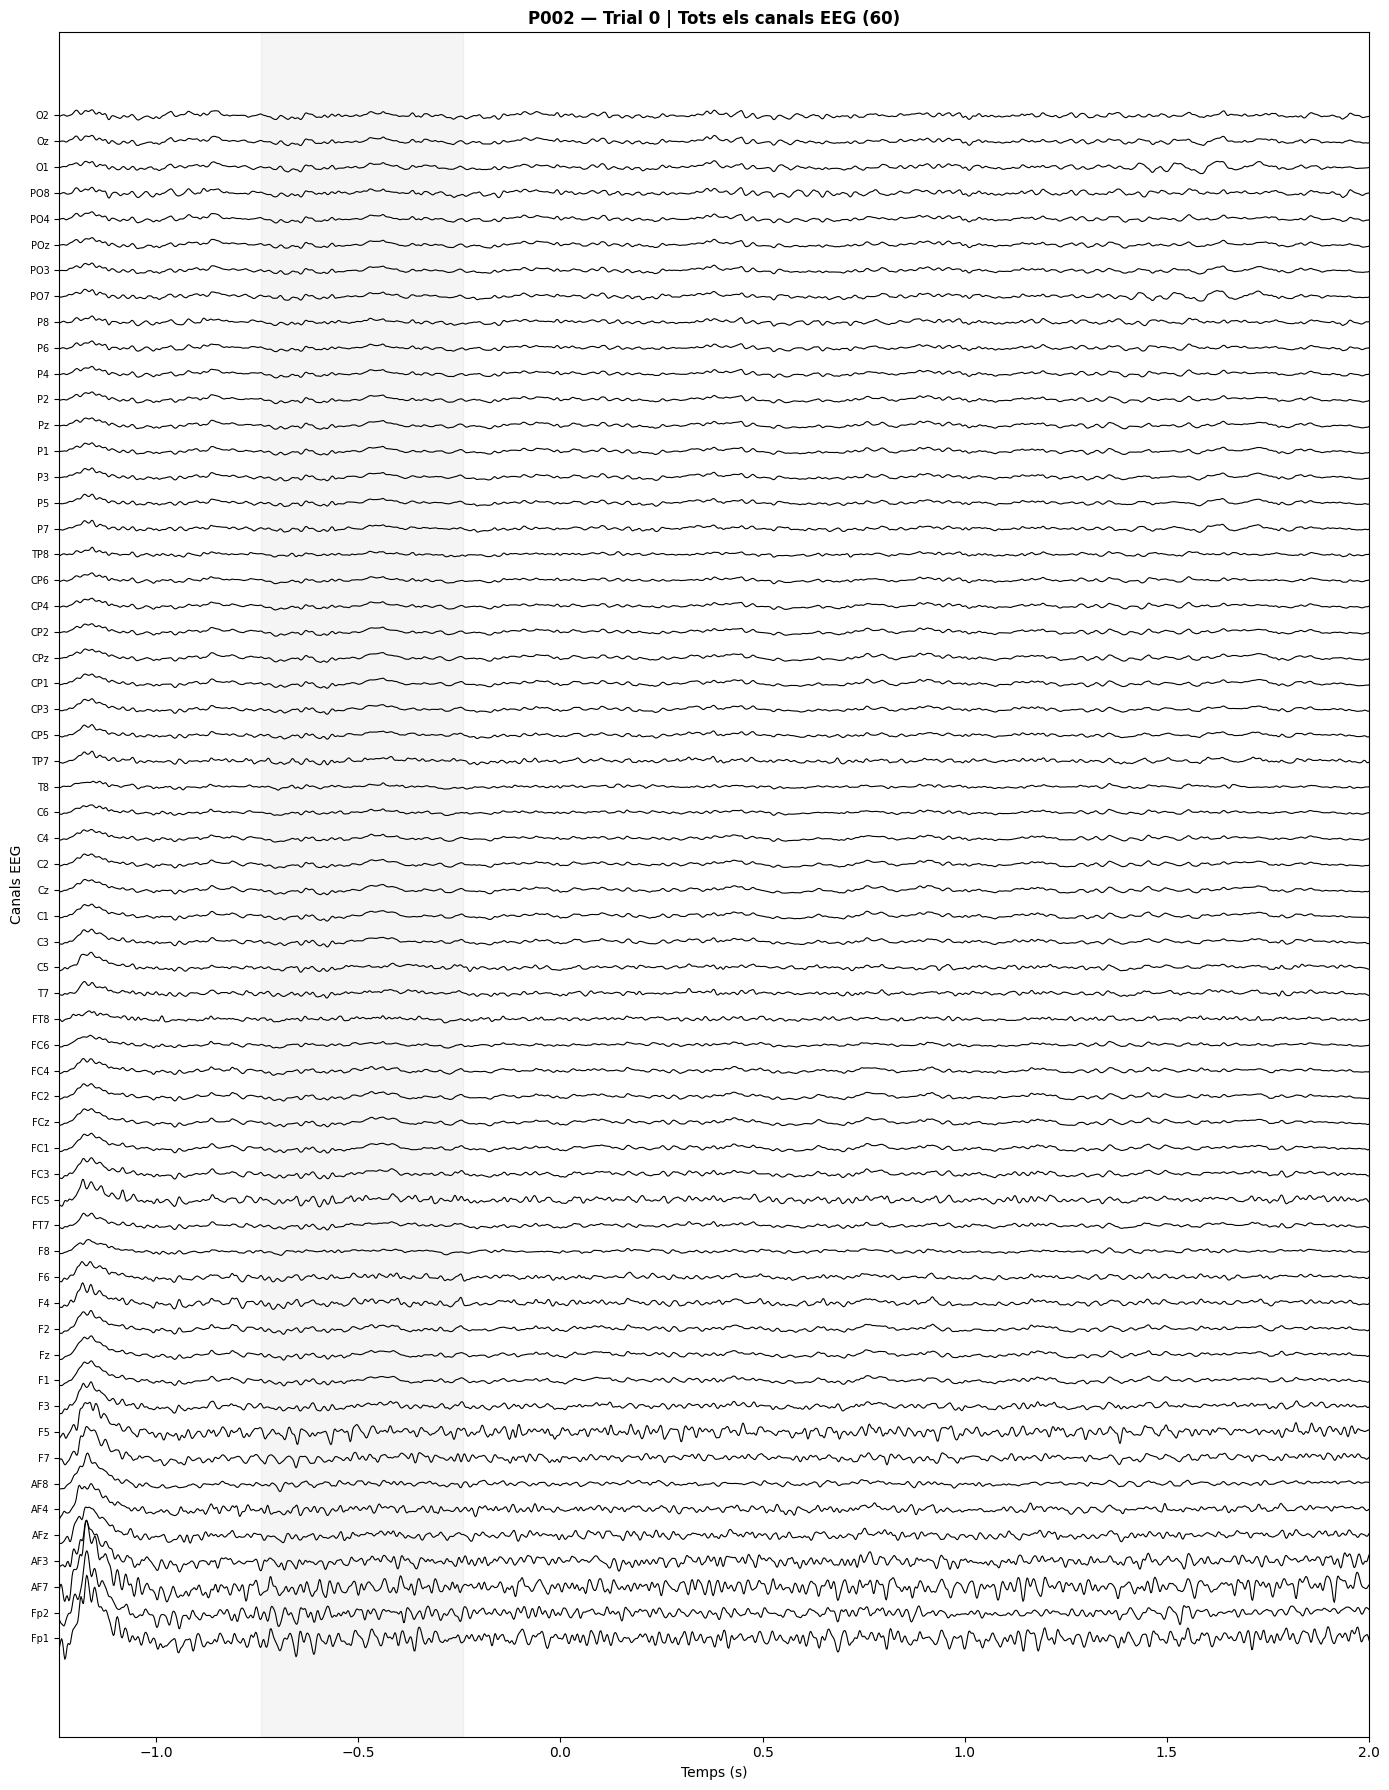

In [7]:
# Llistar i plotar tots els canals EEG de P002 per a un únic trial
ep_eeg = epochs_all.copy().pick("eeg")

trial_idx = 0
data_uv = ep_eeg.get_data()[trial_idx] * 1e6  # (n_ch, n_times) en microvolts
times = ep_eeg.times
ch_names = ep_eeg.ch_names
n_ch = len(ch_names)

# Escalat vertical automàtic perquè no se superposin massa
ptp_per_ch = np.ptp(data_uv, axis=1)
step = np.median(ptp_per_ch) * 1.8
step = step if step > 0 else 10.0
offsets = np.arange(n_ch) * step

fig, ax = plt.subplots(figsize=(14, 18))
for i, ch in enumerate(ch_names):
    ax.plot(times, data_uv[i] + offsets[i], linewidth=0.8, color="black")

ax.set_yticks(offsets)
ax.set_yticklabels(ch_names, fontsize=7)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)

ax.set_xlim([times[0], times[-1]])
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Canals EEG")
ax.set_title(f"{SUBJ} — Trial 0 | Tots els canals EEG ({n_ch})", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "trial_0_tots_canals_eeg.png", dpi=300, bbox_inches="tight")
plt.show()

---

## Part 1: Exploració individual (P002)
Començo amb un sol participant/subjecte per familiaritzar-me amb les dades i fer plots senzills. Després passaré a fer el grand average amb tots els subjectes.

### Desbalanç de classes
Visualització de la distribució de trials per classe al conjunt de dades complet. Això permet veure ràpidament si hi ha desbalanç entre Congruent, Incongruent Pur i Incongruent Mixt.

### EDA conductual (codis CRP/CGP/IPR/IPG/IM/...)

Aquesta secció resumeix els codis conductuals (event_1..event_12) i analitza la dominància ocular en trials incongruents purs.

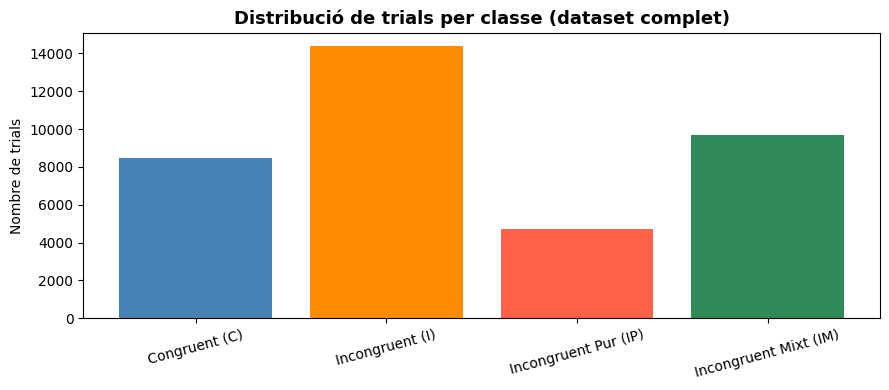

Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_subjectes.csv
Recompte total per classe:
  Congruent (C)          :  8471 trials ( 37.1%)
  Incongruent (I)        : 14367 trials ( 62.9%)
  Incongruent Pur (IP)   :  4689 trials ( 20.5% del total)
  Incongruent Mixt (IM)  :  9678 trials ( 42.4% del total)


In [8]:
df_dominancia, comptes_classes, label_counts, globals_summary = build_behavior_dominance_summary(DATA_DIR)
left_global = globals_summary["left_global"]
right_global = globals_summary["right_global"]
red_global = globals_summary["red_global"]
green_global = globals_summary["green_global"]

c_total = comptes_classes["Congruent"]
ip_total = comptes_classes["Incongruent_Pur"]
im_total = comptes_classes["Incongruent_Mixt"]
i_total = ip_total + im_total

display_labels = [
    "Congruent (C)",
    "Incongruent (I)",
    "Incongruent Pur (IP)",
    "Incongruent Mixt (IM)",
]
display_values = [c_total, i_total, ip_total, im_total]

plt.figure(figsize=(9, 4))
plt.bar(display_labels, display_values, color=["steelblue", "darkorange", "tomato", "seagreen"])
plt.title("Distribució de trials per classe (dataset complet)", fontsize=13, fontweight="bold")
plt.ylabel("Nombre de trials")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribucio_trials_per_classe_dataset_complet.png", dpi=300, bbox_inches="tight")
plt.show()

df_dominancia.to_csv(TABLES_DIR / "dominancia_subjectes.csv", index=False)
print(f"Desat taula: {TABLES_DIR / 'dominancia_subjectes.csv'}")

total = c_total + i_total
print("Recompte total per classe:")
print(f"  Congruent (C)          : {c_total:5d} trials ({(100*c_total/total):5.1f}%)")
print(f"  Incongruent (I)        : {i_total:5d} trials ({(100*i_total/total):5.1f}%)")
print(f"  Incongruent Pur (IP)   : {ip_total:5d} trials ({(100*ip_total/total):5.1f}% del total)")
print(f"  Incongruent Mixt (IM)  : {im_total:5d} trials ({(100*im_total/total):5.1f}% del total)")

La classe Incongruent Pur és la menys representada, mentre que Congruent i Incongruent Mixt tenen una quantitat similar de trials. Aquest desbalanç pot afectar les anàlisis i els models predictius, per la qual cosa és important tenir-ho en compte. Mirant les dades, hi ha subjectes que són més desbalancejats que d'altres. N'hi ha que gairebé mai no tenen Incongruent Pur, però sí que tenim 30 trials garantits, ja que es van eliminar els subjectes amb menys de 30 trials per classe al preprocessament.

In [9]:
label_counts = {k: int(df_dominancia[k].sum()) for k in LABELS_ORDER}
left_global = int(df_dominancia["left_eye"].sum())
right_global = int(df_dominancia["right_eye"].sum())
red_global = int(df_dominancia["red_count"].sum())
green_global = int(df_dominancia["green_count"].sum())

print("Taula base de dominància preparada")
print(f"  Subjectes: {len(df_dominancia)}")
print(f"  Comptes globals ull (L/R): {left_global}/{right_global}")
print(f"  Comptes globals color (R/G): {red_global}/{green_global}")

Taula base de dominància preparada
  Subjectes: 47
  Comptes globals ull (L/R): 2796/1893
  Comptes globals color (R/G): 7303/5896


In [10]:
cols_taula = [
    "subjecte",
    "CRP",
    "CRM",
    "CRG",
    "CGP",
    "CGM",
    "CGG",
    "IPR",
    "IPG",
    "IM",
    "left_eye",
    "right_eye",
    "index_dominancia_ull",
    "p_ull",
    "red_count",
    "green_count",
    "index_dominancia_color",
    "p_color",
]

df_taula = df_dominancia[cols_taula].copy()
df_taula = df_taula.rename(
    columns={
        "index_dominancia_ull": "Índex dominància ull",
        "index_dominancia_color": "Índex dominància color",
    }
)

df_taula["Índex dominància ull"] = df_taula["Índex dominància ull"].round(3)
df_taula["Índex dominància color"] = df_taula["Índex dominància color"].round(3)
df_taula["p_ull"] = df_taula["p_ull"].round(4)
df_taula["p_color"] = df_taula["p_color"].round(4)

df_taula.to_csv(TABLES_DIR / "dominancia_detall_subjectes.csv", index=False)
print(f"Desat taula: {TABLES_DIR / 'dominancia_detall_subjectes.csv'}")

display(df_taula)
print(f"Files de la taula: {len(df_taula)}")

Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_detall_subjectes.csv


,subjecte,CRP,CRM,CRG,CGP,CGM,CGG,IPR,IPG,IM,left_eye,right_eye,Índex dominància ull,p_ull,red_count,green_count,Índex dominància color,p_color
0,P002,81,0,0,63,0,0,88,15,137,97,6,0.883,0.0000,169,78,0.368,0.0000
1,P003,99,0,0,92,0,0,126,67,117,190,3,0.969,0.0000,225,159,0.172,0.0009
2,P004,115,0,0,103,0,0,6,59,303,36,29,0.108,0.4570,121,162,-0.145,0.0173
3,P005,84,3,0,82,2,1,72,49,169,68,53,0.124,0.2029,157,131,0.090,0.1406
4,P008,51,2,2,39,2,0,40,18,100,36,22,0.241,0.0869,91,59,0.213,0.0111
5,P009,115,1,2,109,0,1,90,31,236,81,40,0.339,0.0002,206,142,0.184,0.0007
6,P010,125,0,0,122,0,0,133,24,219,74,83,-0.057,0.5233,258,146,0.277,0.0000
7,P011,68,0,0,53,0,0,26,3,281,13,16,-0.103,0.7111,94,56,0.253,0.0024
8,P013,118,0,0,107,0,0,13,146,193,90,69,0.132,0.1124,131,253,-0.318,0.0000
9,P014,66,3,1,61,5,1,18,51,210,22,47,-0.362,0.0035,85,113,-0.141,0.0547


Files de la taula: 47


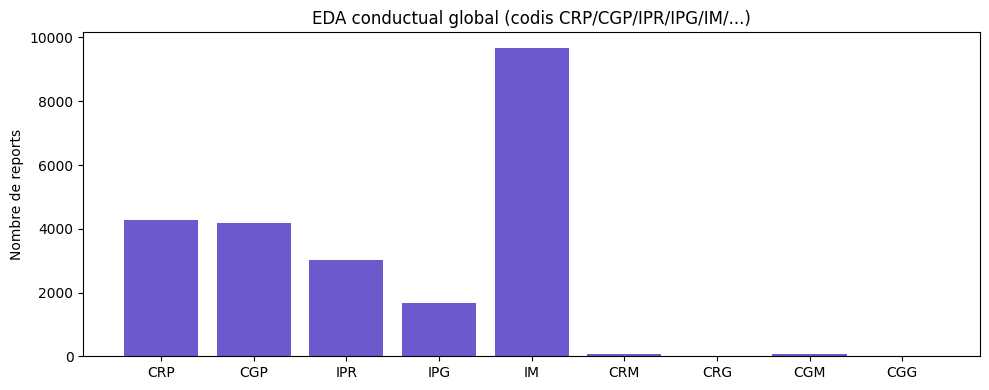

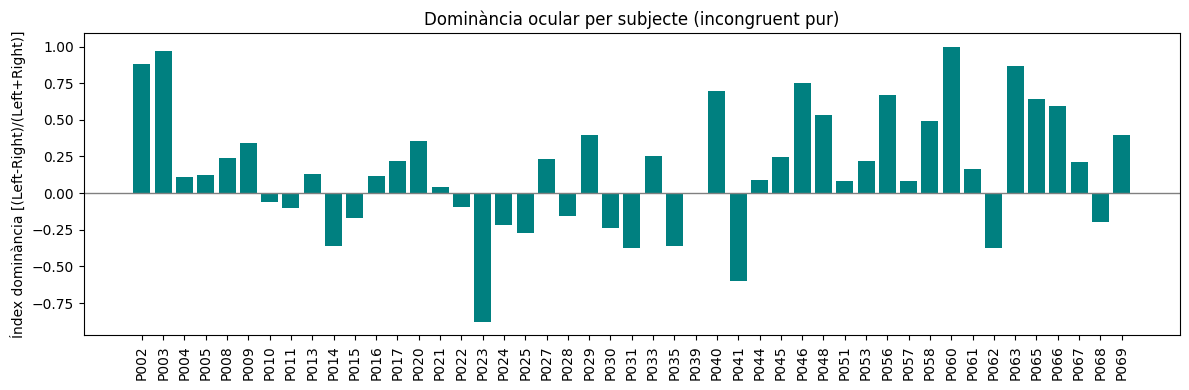

In [11]:
# Plot 1: distribució codis conductuals globals
x = np.arange(len(LABELS_ORDER))
vals = [label_counts[k] for k in LABELS_ORDER]

plt.figure(figsize=(10, 4))
plt.bar(x, vals, color="slateblue")
plt.xticks(x, LABELS_ORDER)
plt.ylabel("Nombre de reports")
plt.title("EDA conductual global (codis CRP/CGP/IPR/IPG/IM/...)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_conductual_global_codis.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: índex de dominància ocular per subjecte
plt.figure(figsize=(12, 4))
plt.axhline(0, color="gray", linewidth=1)
plt.bar(df_dominancia["subjecte"], df_dominancia["index_dominancia_ull"], color="teal")
plt.ylabel("Índex dominància [(Left-Right)/(Left+Right)]")
plt.title("Dominància ocular per subjecte (incongruent pur)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "dominancia_ocular_per_subjecte_incongruent_pur.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
eye_test_global = binomtest(left_global, n=left_global + right_global, p=0.5, alternative="two-sided")
color_test_global = binomtest(red_global, n=red_global + green_global, p=0.5, alternative="two-sided")

eye_ci = eye_test_global.proportion_ci(confidence_level=0.95, method="exact")
color_ci = color_test_global.proportion_ci(confidence_level=0.95, method="exact")

p_ull = left_global / (left_global + right_global)
p_color = red_global / (red_global + green_global)

idx_ull_global = 2 * p_ull - 1
idx_color_global = 2 * p_color - 1

print("Test global de Dominància ocular (incongruent pur)")
print(f"  Left-eye coherent : {left_global}")
print(f"  Right-eye coherent: {right_global}")
print(f"  Proporció esquerre: {p_ull:.3f} (IC95% [{eye_ci.low:.3f}, {eye_ci.high:.3f}])")
print(f"  Índex global      : {idx_ull_global:.3f}")
print(f"  p-valor binomial  : {eye_test_global.pvalue:.4e}")

print("\nTest global de Dominància de color")
print(f"  Vermell : {red_global}")
print(f"  Verd    : {green_global}")
print(f"  Proporció vermell: {p_color:.3f} (IC95% [{color_ci.low:.3f}, {color_ci.high:.3f}])")
print(f"  Índex global      : {idx_color_global:.3f}")
print(f"  p-valor binomial  : {color_test_global.pvalue:.4e}")

Test global de Dominància ocular (incongruent pur)
  Left-eye coherent : 2796
  Right-eye coherent: 1893
  Proporció esquerre: 0.596 (IC95% [0.582, 0.610])
  Índex global      : 0.193
  p-valor binomial  : 7.3452e-40

Test global de Dominància de color
  Vermell : 7303
  Verd    : 5896
  Proporció vermell: 0.553 (IC95% [0.545, 0.562])
  Índex global      : 0.107
  p-valor binomial  : 1.6869e-34


In [13]:
# Comparació explícita: pooled/ponderat vs macro-average
subj_ull = df_dominancia[df_dominancia["n_ull"] > 0].copy()
subj_color = df_dominancia[df_dominancia["n_color"] > 0].copy()

subj_ull["p_left_subj"] = subj_ull["left_eye"] / subj_ull["n_ull"]
subj_color["p_red_subj"] = subj_color["red_count"] / subj_color["n_color"]

# Pooled (equivalent a ponderat per n)
p_ull_pooled = left_global / (left_global + right_global)
p_color_pooled = red_global / (red_global + green_global)

# Macro-average (mateix pes per subjecte)
p_ull_macro = subj_ull["p_left_subj"].mean()
p_color_macro = subj_color["p_red_subj"].mean()

# Weighted-average explícit (ha de coincidir amb pooled)
p_ull_weighted = np.average(subj_ull["p_left_subj"], weights=subj_ull["n_ull"])
p_color_weighted = np.average(subj_color["p_red_subj"], weights=subj_color["n_color"])

print("Comparació de mesures globals")
print("  Dominància ocular (proporció esquerre):")
print(f"    Pooled / ponderat per n : {p_ull_pooled:.4f}")
print(f"    Weighted average        : {p_ull_weighted:.4f}")
print(f"    Macro-average           : {p_ull_macro:.4f}")
print(f"    Diferència macro-pooled : {p_ull_macro - p_ull_pooled:+.4f}")

print("\n  Dominància de color (proporció vermell):")
print(f"    Pooled / ponderat per n : {p_color_pooled:.4f}")
print(f"    Weighted average        : {p_color_weighted:.4f}")
print(f"    Macro-average           : {p_color_macro:.4f}")
print(f"    Diferència macro-pooled : {p_color_macro - p_color_pooled:+.4f}")

Comparació de mesures globals
  Dominància ocular (proporció esquerre):
    Pooled / ponderat per n : 0.5963
    Weighted average        : 0.5963
    Macro-average           : 0.5819
    Diferència macro-pooled : -0.0143

  Dominància de color (proporció vermell):
    Pooled / ponderat per n : 0.5533
    Weighted average        : 0.5533
    Macro-average           : 0.5542
    Diferència macro-pooled : +0.0009


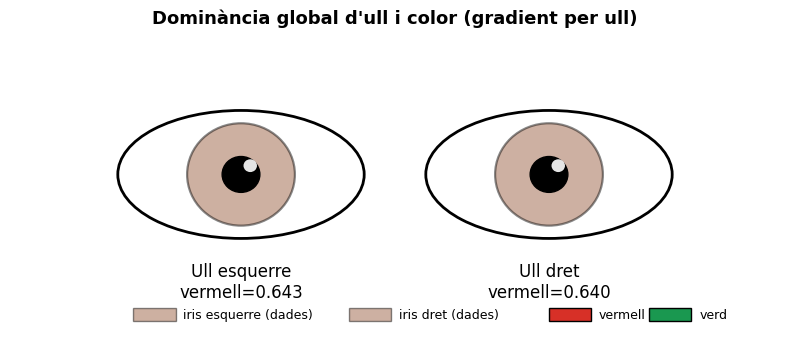

Resum utilitzat pel plot d'ulls
  Ull esquerre: red=1798, green=998, proporció vermell=0.643, intensitat=0.286
  Ull dret    : red=1212, green=681, proporció vermell=0.640, intensitat=0.281


In [14]:
# Dominància global visual (ulls + color), amb gradient per ull
left_red = int(df_dominancia["left_red"].sum())
left_green = int(df_dominancia["left_green"].sum())
right_red = int(df_dominancia["right_red"].sum())
right_green = int(df_dominancia["right_green"].sum())

left_total = max(left_red + left_green, 1)
right_total = max(right_red + right_green, 1)
left_red_ratio = left_red / left_total
right_red_ratio = right_red / right_total

left_intensity = 2 * abs(left_red_ratio - 0.5)
right_intensity = 2 * abs(right_red_ratio - 0.5)
left_iris_alpha = 0.25 + 0.75 * left_intensity
right_iris_alpha = 0.25 + 0.75 * right_intensity

# Color gradient verd->vermell segons proporció de vermell per ull
red_rgb = np.array([0.84, 0.18, 0.15])
green_rgb = np.array([0.10, 0.60, 0.31])
left_iris_color = (1 - left_red_ratio) * green_rgb + left_red_ratio * red_rgb
right_iris_color = (1 - right_red_ratio) * green_rgb + right_red_ratio * red_rgb

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 4.2)
ax.axis("off")


def draw_eye(cx, cy, width, height, iris_color, iris_alpha):
    sclera = Ellipse((cx, cy), width, height, facecolor="white", edgecolor="black", linewidth=2, alpha=1.0)
    iris = Circle(
        (cx, cy), radius=height * 0.40, facecolor=iris_color, edgecolor="black", linewidth=1.6, alpha=iris_alpha
    )
    pupil = Circle((cx, cy), radius=height * 0.14, facecolor="black", edgecolor="black", linewidth=1)
    glare = Circle((cx + 0.12, cy + 0.12), radius=height * 0.05, facecolor="white", edgecolor="none", alpha=0.9)
    ax.add_patch(sclera)
    ax.add_patch(iris)
    ax.add_patch(pupil)
    ax.add_patch(glare)


draw_eye(3.0, 2.25, 3.2, 1.75, left_iris_color, left_iris_alpha)
draw_eye(7.0, 2.25, 3.2, 1.75, right_iris_color, right_iris_alpha)

ax.text(3.0, 1.05, f"Ull esquerre\nvermell={left_red_ratio:.3f}", ha="center", va="top", fontsize=12)
ax.text(7.0, 1.05, f"Ull dret\nvermell={right_red_ratio:.3f}", ha="center", va="top", fontsize=12)

legend_y = 0.24

ax.add_patch(
    Rectangle((1.6, legend_y), 0.55, 0.18, facecolor=left_iris_color, alpha=left_iris_alpha, edgecolor="black")
)
ax.text(2.25, legend_y + 0.09, "iris esquerre (dades)", va="center", fontsize=9)

ax.add_patch(
    Rectangle((4.4, legend_y), 0.55, 0.18, facecolor=right_iris_color, alpha=right_iris_alpha, edgecolor="black")
)
ax.text(5.05, legend_y + 0.09, "iris dret (dades)", va="center", fontsize=9)

ax.add_patch(Rectangle((7.0, legend_y), 0.55, 0.18, facecolor="#d73027", alpha=1.0, edgecolor="black"))
ax.text(7.65, legend_y + 0.09, "vermell", va="center", fontsize=9)

ax.add_patch(Rectangle((8.3, legend_y), 0.55, 0.18, facecolor="#1a9850", alpha=1.0, edgecolor="black"))
ax.text(8.95, legend_y + 0.09, "verd", va="center", fontsize=9)

ax.set_title("Dominància global d'ull i color (gradient per ull)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "dominancia_global_ull_color_gradient.png", dpi=300, bbox_inches="tight")
plt.show()

print("Resum utilitzat pel plot d'ulls")
print(
    f"  Ull esquerre: red={left_red}, green={left_green}, proporció vermell={left_red_ratio:.3f}, intensitat={left_intensity:.3f}"
)
print(
    f"  Ull dret    : red={right_red}, green={right_green}, proporció vermell={right_red_ratio:.3f}, intensitat={right_intensity:.3f}"
)

#### Visualització estilitzada de dominància global (ulls)

Aquest gràfic representa dos ulls: l'opacitat de cada ull codifica la dominància ocular (esquerre/dret) i el color de l'iris codifica la predominància de color (vermell/verd), modulada per l'evidència estadística global.

Subjectes amb biaix significatiu (p < 0.05):
  Ull   : 28/47
  Color : 29/47
Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_significanca_subjectes.csv


,subjecte,left_eye,right_eye,Índex dominància ull,IC95% ull (low),IC95% ull (high),p_ull,ull_predominant,sig_ull,red_count,green_count,Índex dominància color,IC95% color (low),IC95% color (high),p_color,color_predominant,sig_color
0,P002,97,6,0.883495,0.877513,0.978325,3.001586e-22,Esquerre,True,169,78,0.368421,0.622257,0.741677,6.990574e-09,Vermell,True
1,P003,190,3,0.968912,0.955248,0.996783,1.909063e-52,Esquerre,True,225,159,0.171875,0.534865,0.635675,8.864316e-04,Vermell,True
2,P004,36,29,0.107692,0.425319,0.677306,4.570208e-01,Esquerre,False,121,162,-0.144876,0.369183,0.487473,1.726415e-02,Verd,True
3,P005,68,53,0.123967,0.468865,0.651996,2.029243e-01,Esquerre,False,157,131,0.090278,0.485681,0.603659,1.405792e-01,Vermell,False
4,P008,36,22,0.241379,0.483718,0.744892,8.694890e-02,Esquerre,False,91,59,0.213333,0.523685,0.685347,1.112159e-02,Vermell,True
5,P009,81,40,0.338843,0.578086,0.752242,2.442170e-04,Esquerre,True,206,142,0.183908,0.538279,0.644050,7.100480e-04,Vermell,True
6,P010,74,83,-0.057325,0.391278,0.552500,5.233008e-01,Dret,False,258,146,0.277228,0.589650,0.685530,2.744343e-08,Vermell,True
7,P011,13,16,-0.103448,0.264455,0.643061,7.110711e-01,Dret,False,94,56,0.253333,0.544036,0.704188,2.405516e-03,Vermell,True
8,P013,90,69,0.132075,0.485237,0.644330,1.124301e-01,Esquerre,False,131,253,-0.317708,0.293811,0.390952,4.773196e-10,Verd,True
9,P014,22,47,-0.362319,0.211748,0.442054,3.544813e-03,Dret,True,85,113,-0.141414,0.359350,0.501385,5.473388e-02,Verd,False


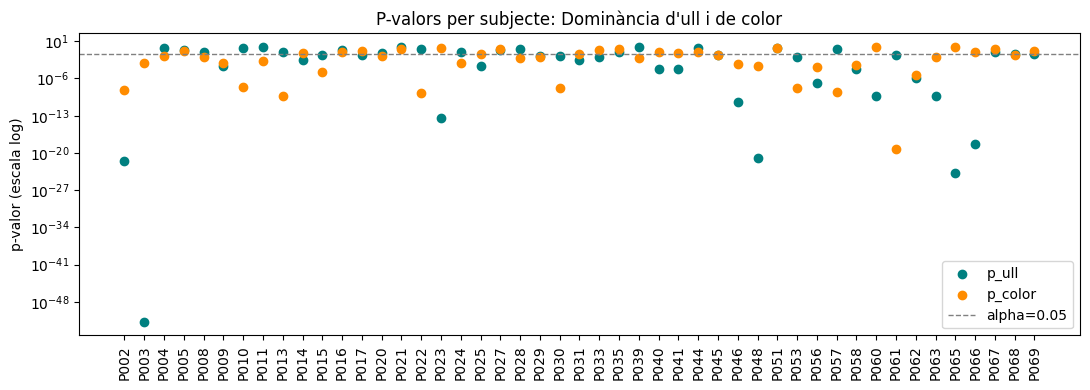

In [15]:
# Criteris de preferència (només descriptius)
df_stats = df_dominancia.copy()
df_stats["ull_predominant"] = np.where(
    df_stats["index_dominancia_ull"] > 0,
    "Esquerre",
    np.where(df_stats["index_dominancia_ull"] < 0, "Dret", "Equilibrat"),
)
df_stats["color_predominant"] = np.where(
    df_stats["index_dominancia_color"] > 0,
    "Vermell",
    np.where(df_stats["index_dominancia_color"] < 0, "Verd", "Equilibrat"),
)

# IC95% exactes per subjecte (si no venen del dataframe principal)
if "ci95_ull_low" not in df_stats.columns:
    df_stats[["ci95_ull_low", "ci95_ull_high"]] = df_stats.apply(
        lambda r: pd.Series(row_binom_ci(r["left_eye"], r["n_ull"])),
        axis=1,
    )
    df_stats[["ci95_color_low", "ci95_color_high"]] = df_stats.apply(
        lambda r: pd.Series(row_binom_ci(r["red_count"], r["n_color"])),
        axis=1,
    )

m_ull = int((df_stats["n_ull"] > 0).sum())
m_color = int((df_stats["n_color"] > 0).sum())
df_stats["sig_ull"] = (df_stats["p_ull"] < 0.05) & (df_stats["n_ull"] > 0)
df_stats["sig_color"] = (df_stats["p_color"] < 0.05) & (df_stats["n_color"] > 0)

print("Subjectes amb biaix significatiu (p < 0.05):")
print(f"  Ull   : {int(df_stats['sig_ull'].sum())}/{m_ull}")
print(f"  Color : {int(df_stats['sig_color'].sum())}/{m_color}")

cols_stats = [
    "subjecte",
    "left_eye",
    "right_eye",
    "index_dominancia_ull",
    "ci95_ull_low",
    "ci95_ull_high",
    "p_ull",
    "ull_predominant",
    "sig_ull",
    "red_count",
    "green_count",
    "index_dominancia_color",
    "ci95_color_low",
    "ci95_color_high",
    "p_color",
    "color_predominant",
    "sig_color",
]

df_stats_show = (
    df_stats[cols_stats]
    .rename(
        columns={
            "index_dominancia_ull": "Índex dominància ull",
            "ci95_ull_low": "IC95% ull (low)",
            "ci95_ull_high": "IC95% ull (high)",
            "index_dominancia_color": "Índex dominància color",
            "ci95_color_low": "IC95% color (low)",
            "ci95_color_high": "IC95% color (high)",
        }
    )
    .sort_values("subjecte")
    .reset_index(drop=True)
)

df_stats_show.to_csv(TABLES_DIR / "dominancia_significanca_subjectes.csv", index=False)
print(f"Desat taula: {TABLES_DIR / 'dominancia_significanca_subjectes.csv'}")

display(df_stats_show)

# Mini-visualització de p-valors per inspecció ràpida
plt.figure(figsize=(11, 4))
plt.scatter(df_stats["subjecte"], df_stats["p_ull"], label="p_ull", color="teal")
plt.scatter(df_stats["subjecte"], df_stats["p_color"], label="p_color", color="darkorange")
plt.axhline(0.05, color="gray", linestyle="--", linewidth=1, label="alpha=0.05")
plt.yscale("log")
plt.ylabel("p-valor (escala log)")
plt.title("P-valors per subjecte: Dominància d'ull i de color")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p_valors_dominancia_ull_color_per_subjecte.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 2: Dominància i preguntes de recerca (fase inicial)

Aquest bloc amplia l'anàlisi de dominància amb visualitzacions d'intervals de confiança per subjecte i comparació pooled vs macro-average.

In [16]:
# Q1-Q2: significació individual (criteri simple p<0.05)
df_infer = df_dominancia.copy()

m_ull = int((df_infer["n_ull"] > 0).sum())
m_color = int((df_infer["n_color"] > 0).sum())

print("Significació per subjecte")
print(f"  Ull   p<0.05 : {int((df_infer['p_ull'] < 0.05).sum())}/{m_ull}")
print(f"  Color p<0.05 : {int((df_infer['p_color'] < 0.05).sum())}/{m_color}")

Significació per subjecte
  Ull   p<0.05 : 28/47
  Color p<0.05 : 29/47


### Forest plot per subjecte (proporció + IC95%)

Comparació visual de dominància ocular i de color per subjecte, amb intervals de confiança exactes.

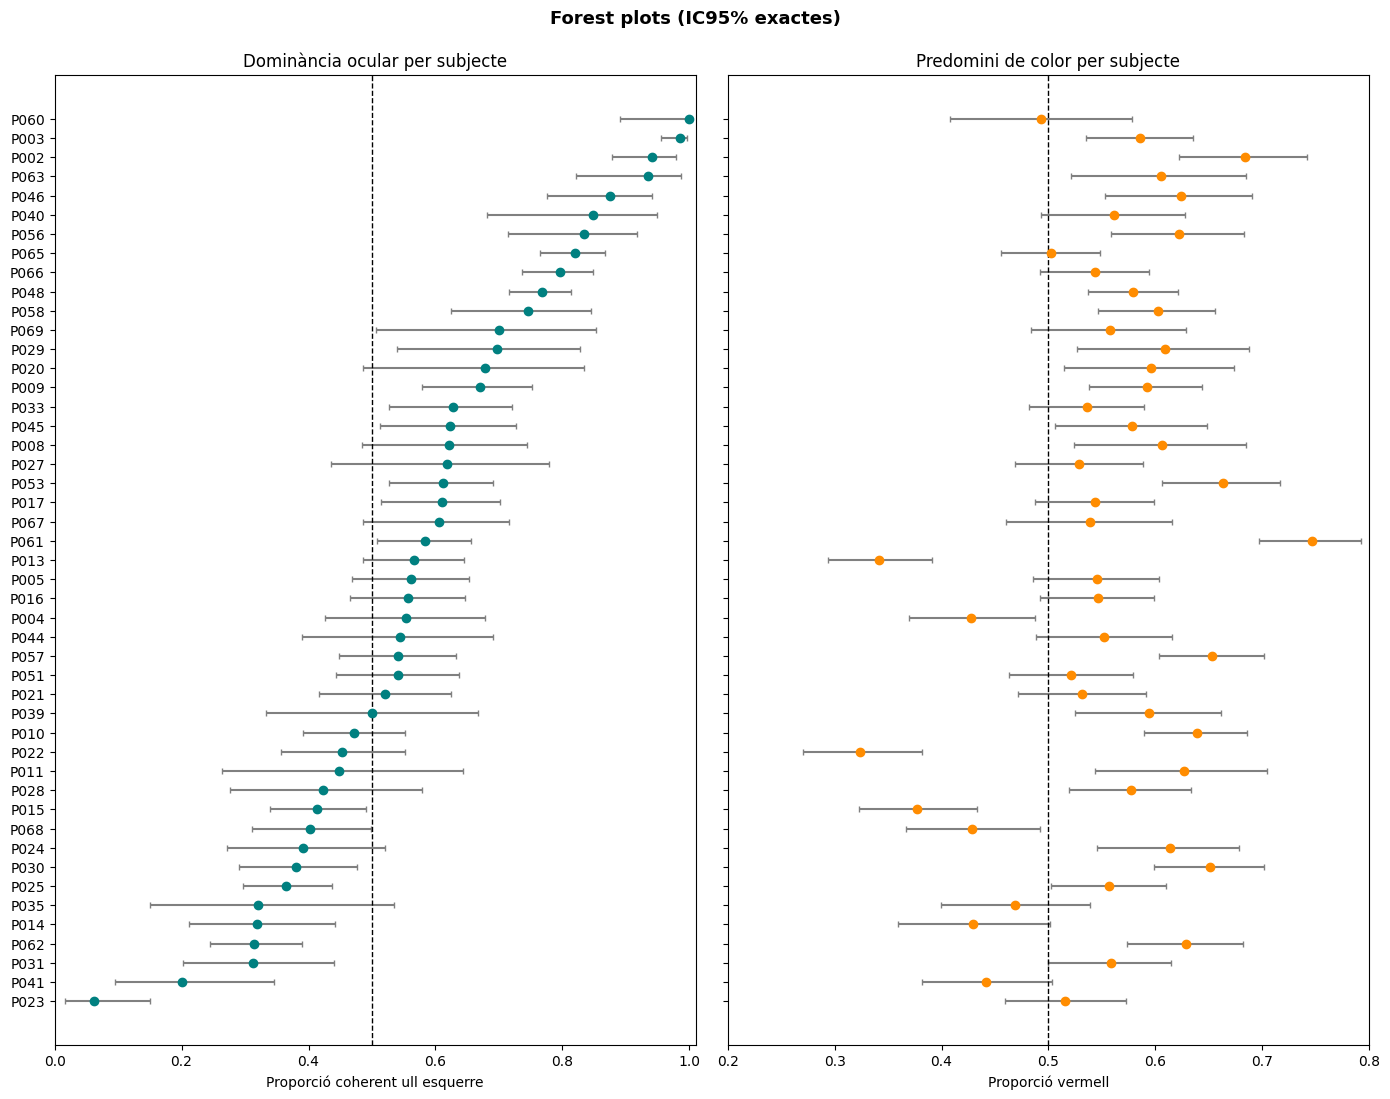

In [17]:
# Construcció de dades de forest plot (ull i color) reutilitzant IC95% ja calculats
forest = df_dominancia.copy()
forest["p_left"] = forest["left_eye"] / forest["n_ull"]
forest["p_red"] = forest["red_count"] / forest["n_color"]

# Garantia mínima per compatibilitat amb versions antigues del dataframe
if "ci95_ull_low" not in forest.columns:
    forest[["ci95_ull_low", "ci95_ull_high"]] = forest.apply(
        lambda r: pd.Series(row_binom_ci(r["left_eye"], r["n_ull"])),
        axis=1,
    )
    forest[["ci95_color_low", "ci95_color_high"]] = forest.apply(
        lambda r: pd.Series(row_binom_ci(r["red_count"], r["n_color"])),
        axis=1,
    )

forest = forest.sort_values("p_left").reset_index(drop=True)
y = np.arange(len(forest))

fig, axes = plt.subplots(1, 2, figsize=(14, 11), sharey=True)

# Dominància ocular
x = forest["p_left"].values
xerr = np.vstack([x - forest["ci95_ull_low"].values, forest["ci95_ull_high"].values - x])
axes[0].errorbar(x, y, xerr=xerr, fmt="o", color="teal", ecolor="gray", capsize=2)
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Dominància ocular per subjecte")
axes[0].set_xlabel("Proporció coherent ull esquerre")
axes[0].set_yticks(y)
axes[0].set_yticklabels(forest["subjecte"])
axes[0].set_xlim(0, 1.01)

# Predomini de color
xc = forest["p_red"].values
xerrc = np.vstack([xc - forest["ci95_color_low"].values, forest["ci95_color_high"].values - xc])
axes[1].errorbar(xc, y, xerr=xerrc, fmt="o", color="darkorange", ecolor="gray", capsize=2)
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Predomini de color per subjecte")
axes[1].set_xlabel("Proporció vermell")
axes[1].set_xlim(0.2, 0.8)

plt.suptitle("Forest plots (IC95% exactes)", y=0.995, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "forest_plots_ic95_exactes.png", dpi=300, bbox_inches="tight")
plt.show()

### Mitjana per subjecte (macro-average)

Mostrem una estimació simple amb la **mitjana normal per subjecte** de la proporció de dominància (ull i color), amb IC95% bootstrap.

Mitjana normal per subjecte (macro-average)
  Ull   (proporció esquerre): 0.5819  IC95% [0.5248, 0.6399]
  Color (proporció vermell) : 0.5542  IC95% [0.5290, 0.5785]


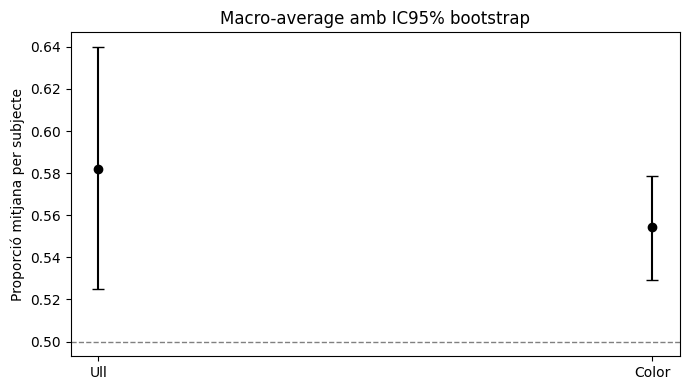

In [18]:
rng = np.random.default_rng(42)


def bootstrap_macro_ci(success_col, total_col, n_boot=5000):
    d = df_dominancia[[success_col, total_col]].dropna().copy()
    d = d[d[total_col] > 0].reset_index(drop=True)
    p_subj = d[success_col] / d[total_col]
    macro = p_subj.mean()

    boot = np.empty(n_boot)
    n = len(p_subj)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[i] = p_subj.iloc[idx].mean()

    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
    return macro, ci_low, ci_high


macro_ull, ull_lo, ull_hi = bootstrap_macro_ci("left_eye", "n_ull")
macro_color, col_lo, col_hi = bootstrap_macro_ci("red_count", "n_color")

print("Mitjana normal per subjecte (macro-average)")
print(f"  Ull   (proporció esquerre): {macro_ull:.4f}  IC95% [{ull_lo:.4f}, {ull_hi:.4f}]")
print(f"  Color (proporció vermell) : {macro_color:.4f}  IC95% [{col_lo:.4f}, {col_hi:.4f}]")

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Ull", "Color"]
means = [macro_ull, macro_color]
ci_low_err = [macro_ull - ull_lo, macro_color - col_lo]
ci_high_err = [ull_hi - macro_ull, col_hi - macro_color]
ax.errorbar(labels, means, yerr=[ci_low_err, ci_high_err], fmt="o", color="black", capsize=4)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("Proporció mitjana per subjecte")
ax.set_title("Macro-average amb IC95% bootstrap")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "macro_average_ic95_bootstrap.png", dpi=300, bbox_inches="tight")
plt.show()

### Relació entre dominància ocular i de color

Pregunta: els subjectes més dominants per ull també tendeixen a ser més dominants per color?

Correlació entre índex de dominància ocular i de color (Spearman)
  rho = 0.240
  p   = 0.104


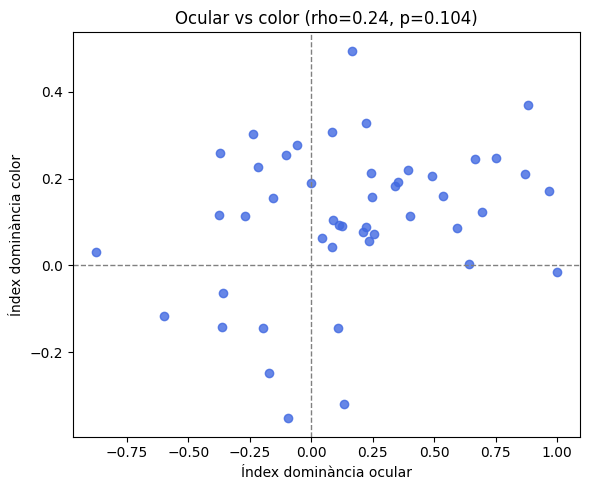

In [19]:
corr_df = df_dominancia[["subjecte", "index_dominancia_ull", "index_dominancia_color"]].dropna()
rho, p_corr = spearmanr(corr_df["index_dominancia_ull"], corr_df["index_dominancia_color"])

print("Correlació entre índex de dominància ocular i de color (Spearman)")
print(f"  rho = {rho:.3f}")
print(f"  p   = {p_corr:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    corr_df["index_dominancia_ull"],
    corr_df["index_dominancia_color"],
    color="royalblue",
    alpha=0.8,
)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Índex dominància ocular")
ax.set_ylabel("Índex dominància color")
ax.set_title(f"Ocular vs color (rho={rho:.2f}, p={p_corr:.3f})")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlacio_dominancia_ocular_vs_color.png", dpi=300, bbox_inches="tight")
plt.show()

## Histogrames de classes per subjecte

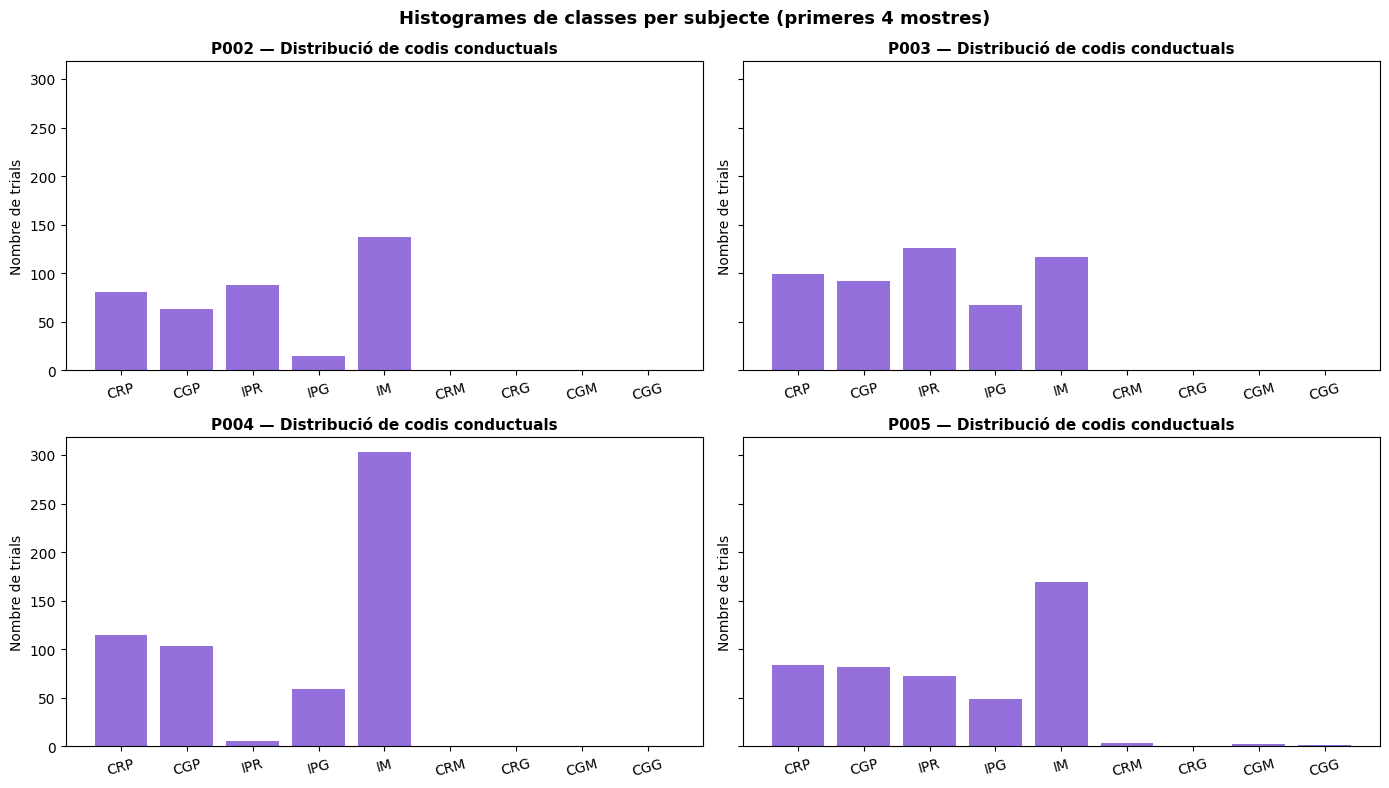

In [20]:
# Histogrames de classes per subjecte en una sola figura (grid 2x2)
subjectes_plot = df_dominancia["subjecte"].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.flatten()

for ax, subj in zip(axes, subjectes_plot):
    subj_data = df_dominancia[df_dominancia["subjecte"] == subj]
    counts = subj_data[LABELS_ORDER].values.flatten()
    ax.bar(LABELS_ORDER, counts, color="mediumpurple")
    ax.set_title(f"{subj} — Distribució de codis conductuals", fontsize=11, fontweight="bold")
    ax.set_ylabel("Nombre de trials")
    ax.tick_params(axis="x", rotation=15)

fig.suptitle("Histogrames de classes per subjecte (primeres 4 mostres)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "histogrames_classes_per_subjecte_grid_2x2.png", dpi=300, bbox_inches="tight")
plt.show()

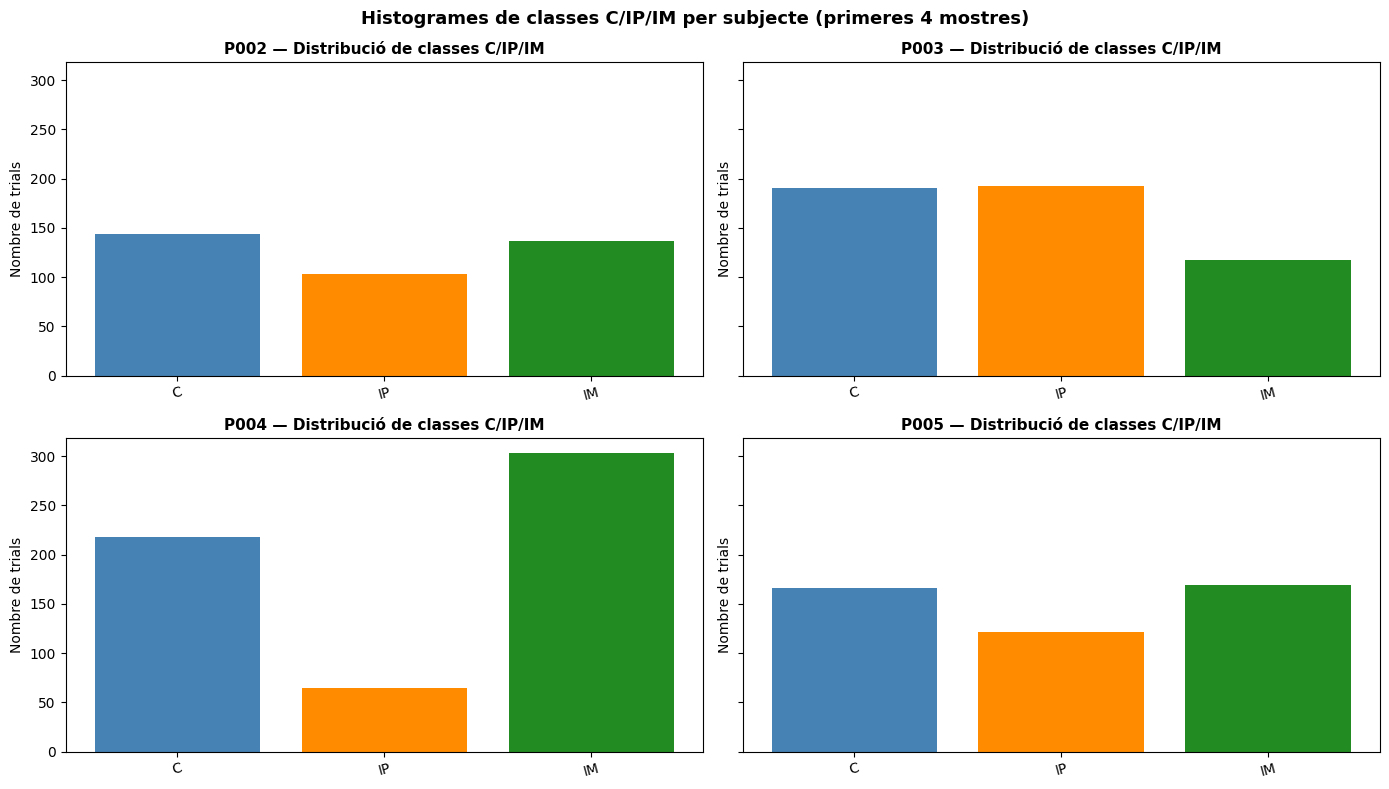

In [21]:
# Histogrames de classes per subjecte (C, IP, IM) en una sola figura (grid 2x2)
subjectes_plot = df_dominancia["subjecte"].head(4).tolist()
classes_plot = ["C", "IP", "IM"]

class_map = {
    "C": ["CRP", "CGP"],
    "IP": ["IPR", "IPG"],
    "IM": ["IM"],
}
class_colors = {
    "C": "steelblue",
    "IP": "darkorange",
    "IM": "forestgreen",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.flatten()
for ax, subj in zip(axes, subjectes_plot):
    subj_data = df_dominancia[df_dominancia["subjecte"] == subj]
    counts = [float(subj_data[class_map[cls]].sum(axis=1).iloc[0]) for cls in classes_plot]

    ax.bar(classes_plot, counts, color=[class_colors[c] for c in classes_plot])
    ax.set_title(f"{subj} — Distribució de classes C/IP/IM", fontsize=11, fontweight="bold")
    ax.set_ylabel("Nombre de trials")
    ax.tick_params(axis="x", rotation=15)

# Si hi ha menys de 4 subjectes, amaga subplots buits
for ax in axes[len(subjectes_plot) :]:
    ax.axis("off")

fig.suptitle("Histogrames de classes C/IP/IM per subjecte (primeres 4 mostres)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "histogrames_classes_c_ip_im_per_subjecte_grid_2x2.png", dpi=300, bbox_inches="tight")
plt.show()

### Anàlisi complementària C/IP/IM (subjecte + global)

Aquest bloc afegeix plots per veure millor la relació entre C, IP i IM:
1. Patró per subjecte en percentatge (stacked) i heatmap.
2. Distribució global entre subjectes (boxplot + mitjana amb IC95%).
3. Tendències ordenades per subjecte.
4. Correlacions entre proporcions C/IP/IM.

In [22]:
# Configuració compartida C/IP/IM + taula resum (execució lineal)
CIPIM_CLASSES = ["C", "IP", "IM"]
CIPIM_CLASS_MAP = {
    "C": ["CRP", "CGP"],
    "IP": ["IPR", "IPG"],
    "IM": ["IM"],
}
CIPIM_COLORS = {
    "C": "steelblue",
    "IP": "darkorange",
    "IM": "forestgreen",
}

df_cipim = pd.DataFrame({"subjecte": df_dominancia["subjecte"]})
for cls in CIPIM_CLASSES:
    df_cipim[cls] = df_dominancia[CIPIM_CLASS_MAP[cls]].sum(axis=1)

df_cipim["total_cipim"] = df_cipim[CIPIM_CLASSES].sum(axis=1)
for cls in CIPIM_CLASSES:
    df_cipim[f"p_{cls}"] = df_cipim[cls] / df_cipim["total_cipim"]

df_cipim = df_cipim.sort_values("subjecte").reset_index(drop=True)

In [23]:
df_cipim.to_csv(TABLES_DIR / "c_ip_im_resum_subjectes.csv", index=False)
print(f"Desada taula: {TABLES_DIR / 'c_ip_im_resum_subjectes.csv'}")
print(f"Subjectes inclosos: {len(df_cipim)}")

display(df_cipim.head())

Desada taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\c_ip_im_resum_subjectes.csv
Subjectes inclosos: 47


,subjecte,C,IP,IM,total_cipim,p_C,p_IP,p_IM
0,P002,144,103,137,384,0.375000,0.268229,0.356771
1,P003,191,193,117,501,0.381238,0.385230,0.233533
2,P004,218,65,303,586,0.372014,0.110922,0.517065
3,P005,166,121,169,456,0.364035,0.265351,0.370614
4,P008,90,58,100,248,0.362903,0.233871,0.403226


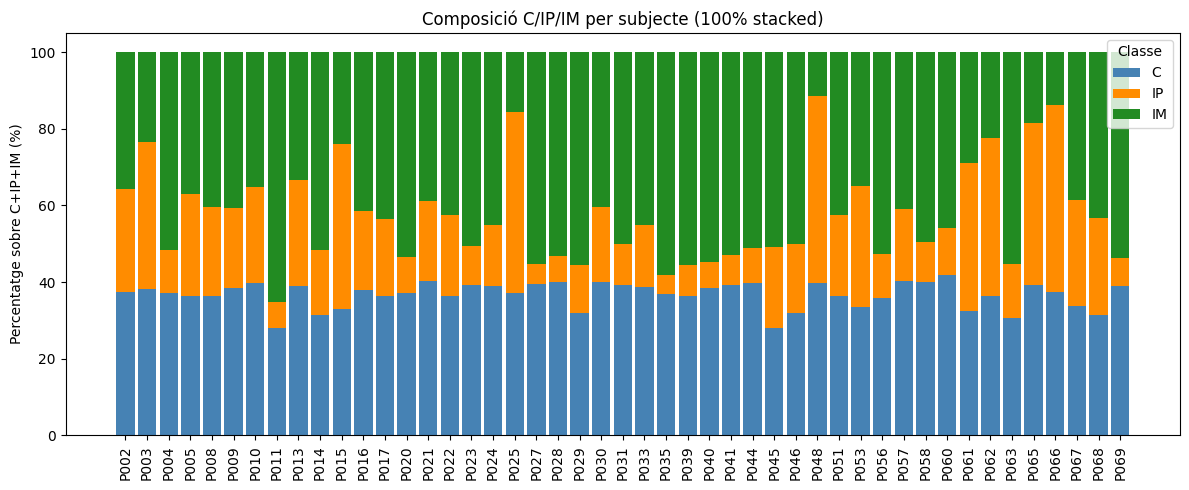

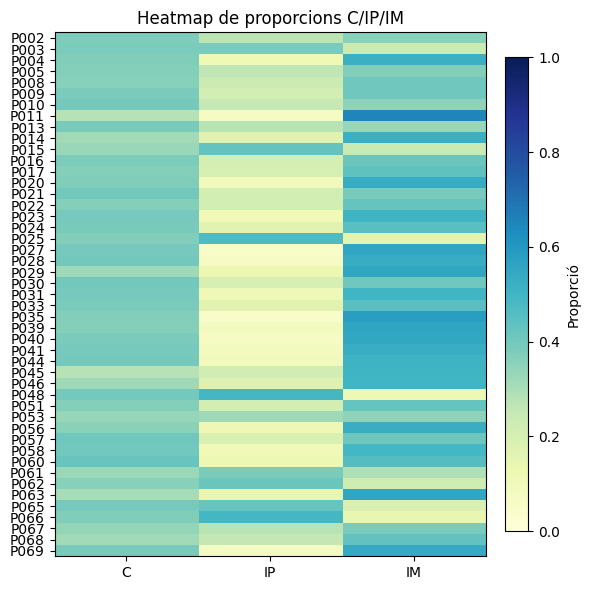

In [24]:
# Plot 1A: stacked bar en percentatge per subjecte
subjectes = df_cipim["subjecte"].tolist()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(subjectes))
bottom = np.zeros(len(subjectes))

for cls in CIPIM_CLASSES:
    vals = df_cipim[f"p_{cls}"].values * 100
    ax.bar(x, vals, bottom=bottom, label=cls, color=CIPIM_COLORS[cls], width=0.85)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(subjectes, rotation=90)
ax.set_ylabel("Percentatge sobre C+IP+IM (%)")
ax.set_title("Composició C/IP/IM per subjecte (100% stacked)")
ax.legend(title="Classe")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_subjecte_stacked_percentatge.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 1B: heatmap de proporcions per subjecte
heat_data = df_cipim[["p_C", "p_IP", "p_IM"]].values

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(heat_data, aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(np.arange(len(CIPIM_CLASSES)))
ax.set_xticklabels(CIPIM_CLASSES)
ax.set_yticks(np.arange(len(subjectes)))
ax.set_yticklabels(subjectes)
ax.set_title("Heatmap de proporcions C/IP/IM")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.04, label="Proporció")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_subjecte_heatmap_proporcions.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\nils\AppData\Local\Temp\ipykernel_16732\542779081.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(values, labels=labels_cls, patch_artist=True)


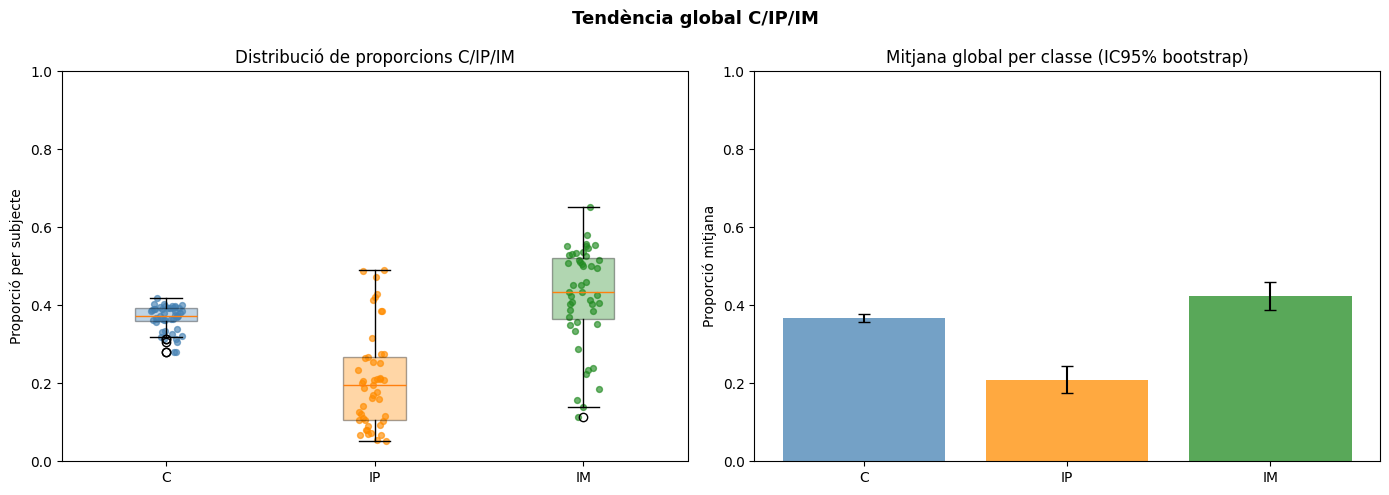

In [25]:
# Plot 2: distribució global entre subjectes (boxplot + mitjana amb IC95%)
prop_cols = [f"p_{cls}" for cls in CIPIM_CLASSES]
labels_cls = CIPIM_CLASSES
values = [df_cipim[c].dropna().values for c in prop_cols]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (A) Boxplot + punts individuals
bp = axes[0].boxplot(values, labels=labels_cls, patch_artist=True)
for patch, cls in zip(bp["boxes"], labels_cls):
    patch.set_facecolor(CIPIM_COLORS[cls])
    patch.set_alpha(0.35)

rng_local = np.random.default_rng(42)
for i, (cls, vals) in enumerate(zip(labels_cls, values), start=1):
    jitter = rng_local.uniform(-0.08, 0.08, size=len(vals))
    axes[0].scatter(np.full(len(vals), i) + jitter, vals, color=CIPIM_COLORS[cls], alpha=0.65, s=18)

axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Proporció per subjecte")
axes[0].set_title("Distribució de proporcions C/IP/IM")

# (B) Mitjana global + IC95% bootstrap
means = []
ci_low = []
ci_high = []
boot_n = 4000
for vals in values:
    vals = np.asarray(vals)
    means.append(vals.mean())
    boot = np.empty(boot_n)
    n = len(vals)
    for i in range(boot_n):
        idx = rng_local.integers(0, n, size=n)
        boot[i] = vals[idx].mean()
    lo, hi = np.percentile(boot, [2.5, 97.5])
    ci_low.append(means[-1] - lo)
    ci_high.append(hi - means[-1])

x = np.arange(len(labels_cls))
axes[1].bar(x, means, color=[CIPIM_COLORS[c] for c in labels_cls], alpha=0.75)
axes[1].errorbar(x, means, yerr=[ci_low, ci_high], fmt="none", ecolor="black", capsize=4)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels_cls)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Proporció mitjana")
axes[1].set_title("Mitjana global per classe (IC95% bootstrap)")

fig.suptitle("Tendència global C/IP/IM", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_global_distribucio_i_ic95.png", dpi=300, bbox_inches="tight")
plt.show()

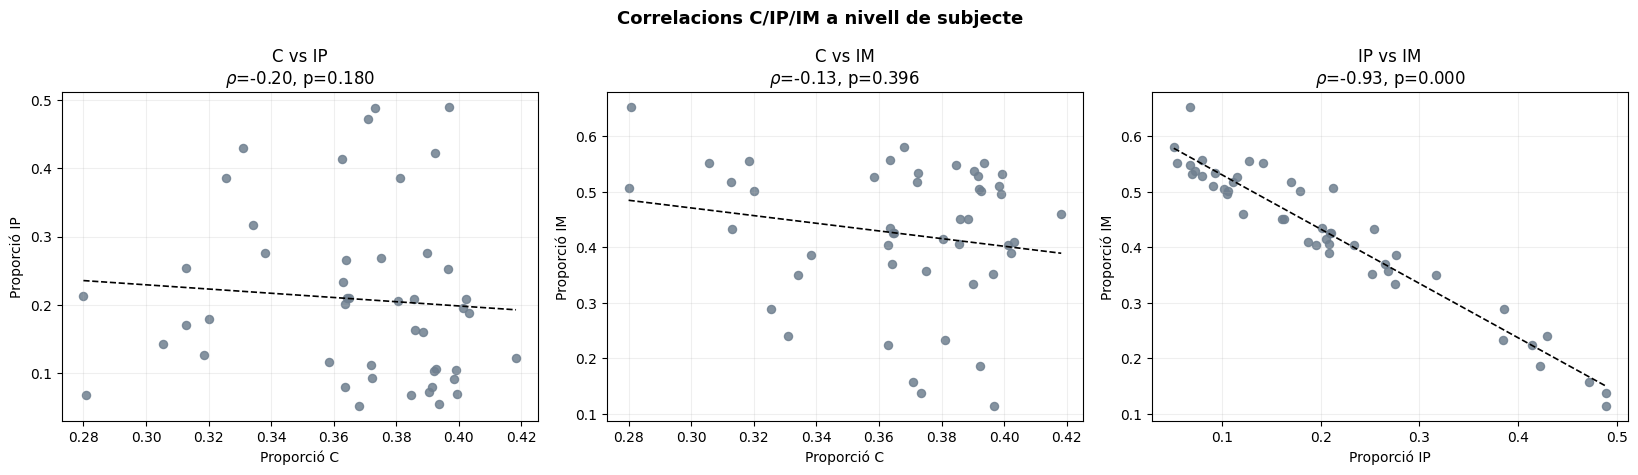

In [26]:
# Plot 3: correlacions a nivell de subjecte (scatter + Spearman)
corr_pairs = [
    ("p_C", "p_IP", "C", "IP"),
    ("p_C", "p_IM", "C", "IM"),
    ("p_IP", "p_IM", "IP", "IM"),
]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), sharex=False, sharey=False)

for ax, (x_col, y_col, x_lab, y_lab) in zip(axes, corr_pairs):
    x_vals = df_cipim[x_col].values
    y_vals = df_cipim[y_col].values

    rho, p_val = spearmanr(x_vals, y_vals)

    ax.scatter(x_vals, y_vals, color="slategray", alpha=0.85, s=34)

    # Recta de tendència lineal només com a guia visual.
    m, b = np.polyfit(x_vals, y_vals, 1)
    x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
    ax.plot(x_line, m * x_line + b, color="black", linewidth=1.2, linestyle="--")

    ax.set_xlabel(f"Proporció {x_lab}")
    ax.set_ylabel(f"Proporció {y_lab}")
    ax.set_title(f"{x_lab} vs {y_lab}\n$\\rho$={rho:.2f}, p={p_val:.3f}")
    ax.grid(alpha=0.2)

fig.suptitle("Correlacions C/IP/IM a nivell de subjecte", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_correlacions_nivell_subjecte_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

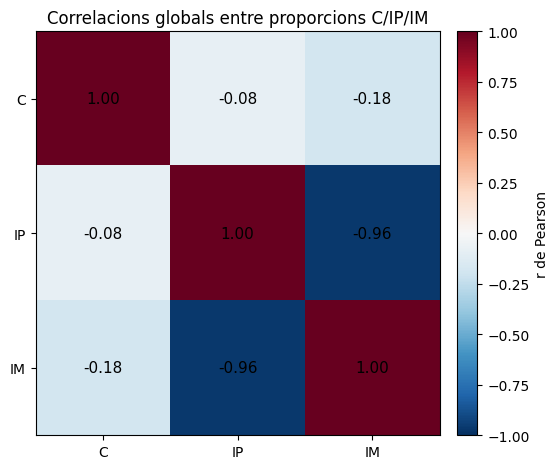

In [27]:
# Plot 4: matriu de correlacions entre proporcions C/IP/IM
corr_mat = df_cipim[["p_C", "p_IP", "p_IM"]].corr().values
labels = CIPIM_CLASSES

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(corr_mat, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr_mat[i, j]:.2f}", ha="center", va="center", color="black", fontsize=11)

ax.set_title("Correlacions globals entre proporcions C/IP/IM")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.04, label="r de Pearson")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_correlacions_proporcions.png", dpi=300, bbox_inches="tight")
plt.show()

### Mitjana harmònica i balanç de classes

Abans del Cohen's d, aquest bloc mostra com la **mitjana harmònica** captura el desbalanç entre C, IP i IM:
- baixa fort quan una classe és petita,
- queda propera als recomptes reals quan les 3 classes estan equilibrades.

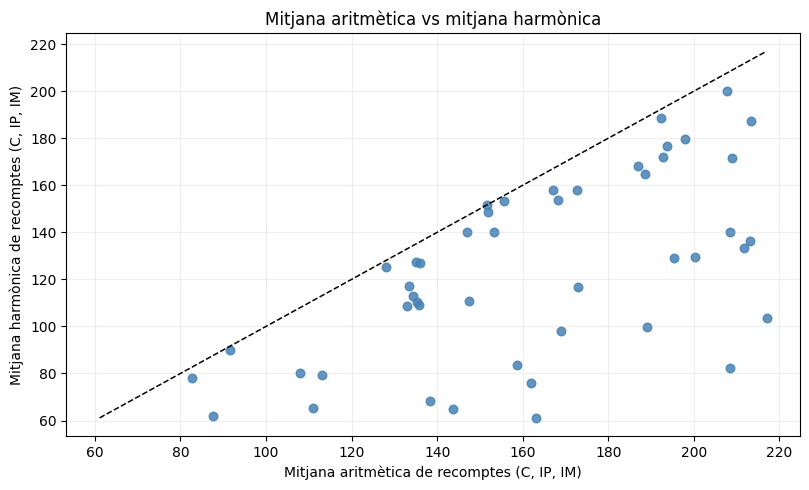

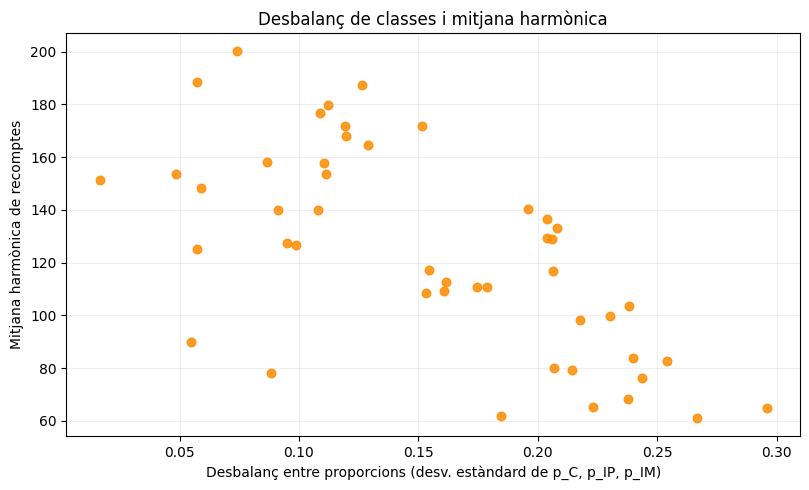

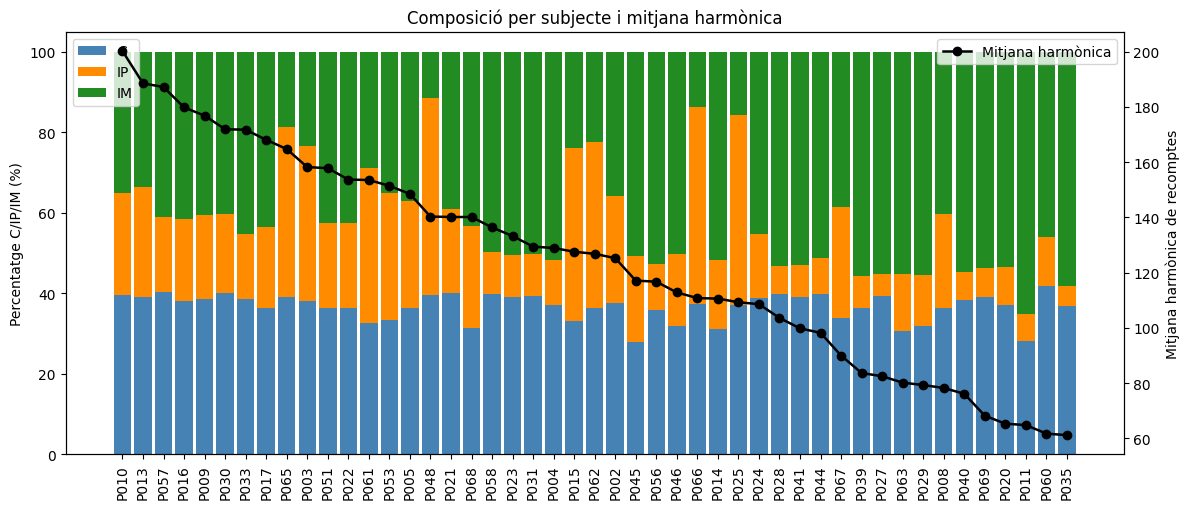

In [28]:
# Tres visualitzacions del concepte de mitjana harmònica sobre C/IP/IM

df_hm = df_cipim[["subjecte", "C", "IP", "IM", "p_C", "p_IP", "p_IM"]].copy()
df_hm["n_harm_3classes"] = 3.0 / ((1.0 / df_hm["C"]) + (1.0 / df_hm["IP"]) + (1.0 / df_hm["IM"]))
df_hm["n_arit_3classes"] = (df_hm["C"] + df_hm["IP"] + df_hm["IM"]) / 3.0
df_hm["balance_index"] = df_hm[["p_C", "p_IP", "p_IM"]].std(axis=1)

# Plot 1: mitjana aritmètica vs harmònica per subjecte
fig, ax = plt.subplots(figsize=(8.2, 5))
ax.scatter(df_hm["n_arit_3classes"], df_hm["n_harm_3classes"], color="steelblue", s=38, alpha=0.85)
xy_min = min(df_hm["n_arit_3classes"].min(), df_hm["n_harm_3classes"].min())
xy_max = max(df_hm["n_arit_3classes"].max(), df_hm["n_harm_3classes"].max())
ax.plot([xy_min, xy_max], [xy_min, xy_max], linestyle="--", linewidth=1.1, color="black")
ax.set_xlabel("Mitjana aritmètica de recomptes (C, IP, IM)")
ax.set_ylabel("Mitjana harmònica de recomptes (C, IP, IM)")
ax.set_title("Mitjana aritmètica vs mitjana harmònica")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mitjana_aritmetica_vs_harmonica_c_ip_im.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: desbalanç de proporcions vs mitjana harmònica
fig, ax = plt.subplots(figsize=(8.2, 5))
ax.scatter(df_hm["balance_index"], df_hm["n_harm_3classes"], color="darkorange", s=38, alpha=0.85)
ax.set_xlabel("Desbalanç entre proporcions (desv. estàndard de p_C, p_IP, p_IM)")
ax.set_ylabel("Mitjana harmònica de recomptes")
ax.set_title("Desbalanç de classes i mitjana harmònica")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "desbalanc_proporcions_vs_mitjana_harmonica.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 3: proporcions apilades, ordenades per mitjana harmònica
plot_df = df_hm.sort_values("n_harm_3classes", ascending=False).reset_index(drop=True)
subjectes_hm = plot_df["subjecte"].tolist()
x = np.arange(len(plot_df))
bottom = np.zeros(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 5.2))
for cls in ["C", "IP", "IM"]:
    vals = plot_df[f"p_{cls}"].values * 100
    ax.bar(x, vals, bottom=bottom, label=cls, color=CIPIM_COLORS[cls], width=0.85)
    bottom += vals

ax2 = ax.twinx()
ax2.plot(x, plot_df["n_harm_3classes"].values, color="black", linewidth=1.8, marker="o", label="Mitjana harmònica")
ax2.set_ylabel("Mitjana harmònica de recomptes")

ax.set_xticks(x)
ax.set_xticklabels(subjectes_hm, rotation=90)
ax.set_ylabel("Percentatge C/IP/IM (%)")
ax.set_title("Composició per subjecte i mitjana harmònica")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "composicio_i_mitjana_harmonica_per_subjecte.png", dpi=300, bbox_inches="tight")
plt.show()

### Efecte per subjecte: Cohen's d real (theta FCz i alpha Oz)

Aquí calculem **Cohen's d real** per subjecte sobre una variable contínua, en el contrast **Incongruent Pur (IP) vs Congruent (C)**:
$$
d = \frac{\bar{x}_{IP} - \bar{x}_C}{s_{pooled}}
$$

Definicions d'aquest bloc:
- **Theta**: potència de banda 5–7 Hz a **FCz**.
- **Alpha**: potència de banda 8–12 Hz a **Oz**.
- Resum trial-a-trial a la finestra temporal $[0.5, 1.0]$ s.

Sobre undersampling per a Cohen's d:
- recomanat com a anàlisi principal: **no** (mantenir totes les dades),
- recomanat com a sensibilitat: **sí** (comparar amb versió balancejada).

In [29]:
COHENS_TABLE_PATH = TABLES_DIR / "cohens_d_real_per_subjecte.csv"

try:
    df_cohens = pd.read_csv(COHENS_TABLE_PATH)
    print(f"Taula carregada: {COHENS_TABLE_PATH}")
except Exception:
    print("Calculant Cohen's d per subjecte...")

    def trial_bandpower_mean(epochs_obj, channel, band, time_window):
        if channel not in epochs_obj.ch_names:
            return None
        data = epochs_obj.get_data(picks=[channel]).squeeze(axis=1)  # (n_trials, n_times)
        sfreq = epochs_obj.info["sfreq"]

        # Potencia de banda rapida: filtre temporal + potencia quadratica.
        filtered = mne.filter.filter_data(
            data,
            sfreq=sfreq,
            l_freq=band[0],
            h_freq=band[1],
            method="fir",
            verbose=False,
        )
        power = filtered**2
        tmask = (epochs_obj.times >= time_window[0]) & (epochs_obj.times <= time_window[1])
        return power[:, tmask].mean(axis=1)

    def cohens_d_independent(x_ip, x_c):
        """Calcula Cohen's d per mostres independents amb desviació estàndard agrupada (pooled).
        Retorna np.nan si no es pot calcular per falta de dades o desviació zero."""
        n_ip = len(x_ip)
        n_c = len(x_c)
        if n_ip < 2 or n_c < 2:
            return np.nan

        s_ip = float(np.std(x_ip, ddof=1))
        s_c = float(np.std(x_c, ddof=1))
        pooled = np.sqrt(((n_ip - 1) * (s_ip**2) + (n_c - 1) * (s_c**2)) / (n_ip + n_c - 2))
        if not np.isfinite(pooled) or pooled == 0:
            return np.nan

        return (float(np.mean(x_ip)) - float(np.mean(x_c))) / pooled

    def get_undersampled_indices(n_ip, n_c, rng):
        n_min = min(n_ip, n_c)
        if n_min < 2:
            return None, None
        idx_ip = rng.choice(n_ip, size=n_min, replace=False)
        idx_c = rng.choice(n_c, size=n_min, replace=False)
        return idx_ip, idx_c

    rows_d = []

    for fif_path in sorted(DATA_DIR.glob("*.fif")):
        subj = fif_path.stem
        ep = mne.read_epochs(fif_path, preload=False, verbose=False)

        for ch in ep.info["chs"]:
            if ch["unit"] == 0:
                ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ch["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        ep.load_data()
        # Convertim μV -> V
        ep._data *= 1e-6

        inv_id = {v: k for k, v in ep.event_id.items()}

        c_names = [inv_id[code] for code in COND_EVENTS_CODES["Congruent"] if code in inv_id]
        ip_names = [inv_id[code] for code in COND_EVENTS_CODES["Incongruent_Pur"] if code in inv_id]
        im_names = [inv_id[code] for code in COND_EVENTS_CODES["Incongruent_Mixt"] if code in inv_id]

        if not c_names or not ip_names:
            print(
                f"Subjecte {subj}: no s'han trobat els codis d'event necessaris per C/IP. S'haurà de revisar manualment."
            )
            continue

        ep_c = ep[c_names].copy().load_data()
        ep_ip = ep[ip_names].copy().load_data()

        # Només ens interessa el nombre de trials IM, però no farem res amb ells en el càlcul de Cohen's d, així que no cal carregar-los.
        n_im = len(ep[im_names]) if im_names else 0

        theta_c = trial_bandpower_mean(ep_c, channel="FCz", band=(5, 7), time_window=ERP_WINDOW)
        theta_ip = trial_bandpower_mean(ep_ip, channel="FCz", band=(5, 7), time_window=ERP_WINDOW)
        alpha_c = trial_bandpower_mean(ep_c, channel="Oz", band=(8, 12), time_window=ERP_WINDOW)
        alpha_ip = trial_bandpower_mean(ep_ip, channel="Oz", band=(8, 12), time_window=ERP_WINDOW)

        if theta_c is None or theta_ip is None or alpha_c is None or alpha_ip is None:
            print(
                f"Subjecte {subj}: no s'han pogut calcular les potències de banda per falta de canals. S'haurà de revisar manualment."
            )
            continue

        d_theta_raw = cohens_d_independent(theta_ip, theta_c)
        d_alpha_raw = cohens_d_independent(alpha_ip, alpha_c)

        rng_us = np.random.default_rng(42 + hash(subj) % 10000)
        idx_ip, idx_c = get_undersampled_indices(len(theta_ip), len(theta_c), rng_us)

        if idx_ip is not None and idx_c is not None:
            d_theta_us = cohens_d_independent(theta_ip[idx_ip], theta_c[idx_c])
            d_alpha_us = cohens_d_independent(alpha_ip[idx_ip], alpha_c[idx_c])
        else:
            d_theta_us = np.nan
            d_alpha_us = np.nan
            print(
                f"Subjecte {subj}: no s'han pogut calcular Cohen's d amb undersampling per falta de trials suficients en alguna classe."
            )

        n_c = len(theta_c)
        n_ip = len(theta_ip)

        if min(n_c, n_ip, n_im) < 2:
            print(
                f"Subjecte {subj}: no s'han pogut calcular les mitjanes harmòniques per falta de trials suficients en alguna classe (C={n_c}, IP={n_ip}, IM={n_im})."
            )
            n_harm = np.nan
        else:
            n_harm = 3.0 / ((1.0 / n_c) + (1.0 / n_ip) + (1.0 / n_im))

        n_balanced = 2.0 * min(n_c, n_ip)

        row_ci = df_cipim[df_cipim["subjecte"] == subj]

        rows_d.append(
            {
                "subjecte": subj,
                "cohens_d_theta_fcz": d_theta_raw,
                "cohens_d_alpha_oz": d_alpha_raw,
                "cohens_d_theta_fcz_us": d_theta_us,
                "cohens_d_alpha_oz_us": d_alpha_us,
                "C": n_c,
                "IP": n_ip,
                "IM": n_im,
                "n_harm_3classes": n_harm,
                "n_balanced_ci": n_balanced,
            }
        )

        del ep_c, ep_ip, theta_c, theta_ip, alpha_c, alpha_ip
        gc.collect()

    df_cohens = pd.DataFrame(rows_d)
    if df_cohens.empty:
        raise RuntimeError("No s'ha pogut calcular cap Cohen's d per subjecte.")

    df_cohens.to_csv(COHENS_TABLE_PATH, index=False)
    print(f"Desada taula: {COHENS_TABLE_PATH}")

# Taules ordenades (més gran -> més petit)
df_theta_sorted = df_cohens.sort_values("cohens_d_theta_fcz", ascending=False).reset_index(drop=True)
df_alpha_sorted = df_cohens.sort_values("cohens_d_alpha_oz", ascending=False).reset_index(drop=True)

print("Cohen's d theta (FCz) ordenat de més gran a més petit:")
display(df_theta_sorted[["subjecte", "cohens_d_theta_fcz", "cohens_d_theta_fcz_us", "C", "IP"]])

print("Cohen's d alpha (Oz) ordenat de més gran a més petit:")
display(df_alpha_sorted[["subjecte", "cohens_d_alpha_oz", "cohens_d_alpha_oz_us", "C", "IP"]])

print("Extrems theta (màxim i mínim):")
display(pd.concat([df_theta_sorted.head(1), df_theta_sorted.tail(1)], ignore_index=True))

print("Extrems alpha (màxim i mínim):")
display(pd.concat([df_alpha_sorted.head(1), df_alpha_sorted.tail(1)], ignore_index=True))

Taula carregada: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\cohens_d_real_per_subjecte.csv
Cohen's d theta (FCz) ordenat de més gran a més petit:


,subjecte,cohens_d_theta_fcz,cohens_d_theta_fcz_us,C,IP
0,P040,0.462300,0.406247,187,33
1,P045,0.348442,0.281347,112,85
2,P056,0.340618,0.239987,186,60
3,P023,0.323009,0.288233,249,65
4,P014,0.257505,0.319052,127,69
5,P002,0.216033,0.215705,144,103
6,P024,0.194757,0.301737,155,64
7,P027,0.174563,-0.023284,246,34
8,P067,0.157750,0.200525,93,76
9,P033,0.138825,0.190058,242,102


Cohen's d alpha (Oz) ordenat de més gran a més petit:


,subjecte,cohens_d_alpha_oz,cohens_d_alpha_oz_us,C,IP
0,P024,0.327909,0.260096,155,64
1,P004,0.315582,0.307149,218,65
2,P046,0.199650,0.093177,129,72
3,P013,0.160384,0.133450,225,159
4,P053,0.137332,0.098706,152,144
5,P008,0.112074,0.176677,90,58
6,P045,0.097975,0.087587,112,85
7,P010,0.063343,0.109491,247,157
8,P020,0.020275,-0.024935,124,31
9,P056,0.000086,-0.177672,186,60


Extrems theta (màxim i mínim):


,subjecte,cohens_d_theta_fcz,cohens_d_alpha_oz,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,C,IP,IM,n_harm_3classes,n_balanced_ci
0,P040,0.462300,-0.197679,0.406247,0.173502,187,33,266,76.122768,66.0
1,P057,-0.416631,-0.633250,-0.511480,-0.659600,258,120,262,187.194683,240.0


Extrems alpha (màxim i mínim):


,subjecte,cohens_d_theta_fcz,cohens_d_alpha_oz,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,C,IP,IM,n_harm_3classes,n_balanced_ci
0,P024,0.194757,0.327909,0.301737,0.260096,155,64,180,108.569112,128.0
1,P057,-0.416631,-0.633250,-0.511480,-0.659600,258,120,262,187.194683,240.0


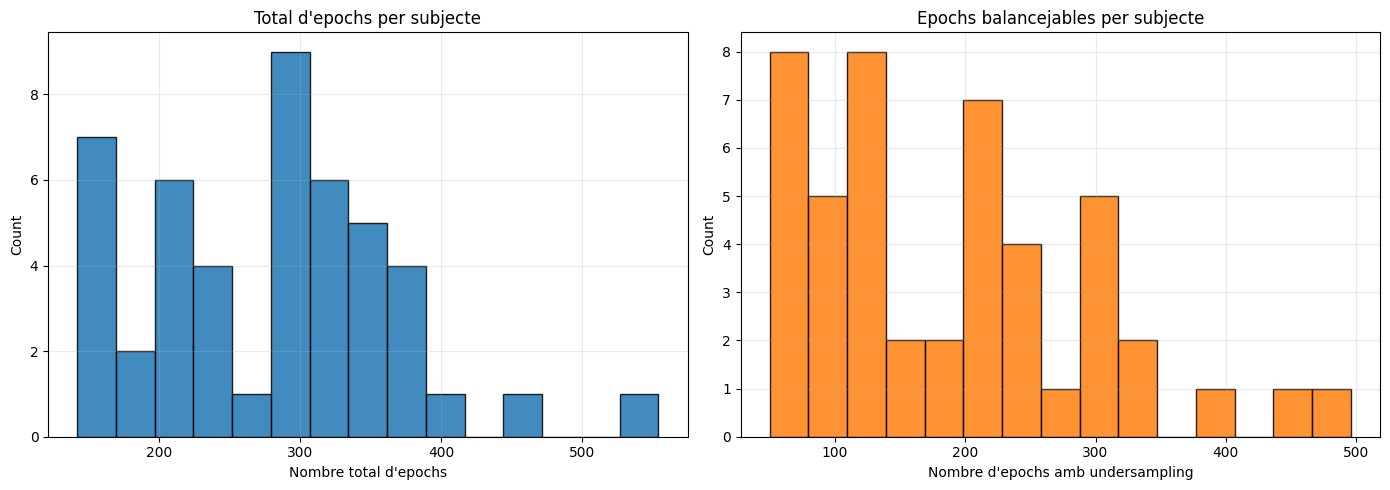

Resum ràpid:
- Total epochs per subjecte: min=142, max=554, mitjana=280.0
- 2×min(C, IP): min=50, max=496, mitjana=188.6


,subjecte,cohens_d_theta_fcz,cohens_d_alpha_oz,C,IP,n_harm_3classes,n_balanced_ci
0,P002,0.216033,-0.343979,144,103,125.248135,206.0
1,P003,-0.203969,-0.504878,191,193,158.194826,382.0
2,P004,-0.019846,0.315582,218,65,128.909717,130.0
3,P005,-0.202974,-0.199584,166,121,148.472816,242.0
4,P008,-0.005703,0.112074,90,58,78.221778,116.0
5,P009,-0.096554,-0.225065,224,121,176.823855,242.0
6,P010,-0.030113,0.063343,247,157,200.210624,314.0
7,P011,-0.208068,-0.210972,121,29,64.786504,58.0
8,P013,0.004541,0.160384,225,159,188.500232,318.0
9,P014,0.257505,-0.020979,127,69,110.584100,138.0


In [30]:
# Histogrames de disponibilitat d'epochs per subjecte
# 1) Nombre total d'epochs per subjecte
#    Aquí comptem totes les mostres disponibles per subjecte (C + IP).
df_epochs_subjecte = df_cohens.copy()
df_epochs_subjecte["n_total_epochs"] = df_epochs_subjecte["C"] + df_epochs_subjecte["IP"]

# 2) Nombre d'epochs balancejables per subjecte: 2 * min(C, IP)
#    És el màxim que es podria usar si vols balancejar perfectament les classes.
df_balanceig = df_epochs_subjecte.copy()
df_balanceig["n_balancejable"] = 2 * np.minimum(df_balanceig["C"], df_balanceig["IP"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma 1: total d'epochs per subjecte
axes[0].hist(df_epochs_subjecte["n_total_epochs"], bins=15, color="tab:blue", edgecolor="black", alpha=0.85)
axes[0].set_title("Total d'epochs per subjecte")
axes[0].set_xlabel("Nombre total d'epochs")
axes[0].set_ylabel("Count")
axes[0].grid(alpha=0.25)

# Histograma 2: 2 * min(C, IP)
axes[1].hist(df_balanceig["n_balancejable"], bins=15, color="tab:orange", edgecolor="black", alpha=0.85)
axes[1].set_title("Epochs balancejables per subjecte")
axes[1].set_xlabel("Nombre d'epochs amb undersampling")
axes[1].set_ylabel("Count")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Resum ràpid:")
print(
    f"- Total epochs per subjecte: min={df_epochs_subjecte['n_total_epochs'].min():.0f}, max={df_epochs_subjecte['n_total_epochs'].max():.0f}, mitjana={df_epochs_subjecte['n_total_epochs'].mean():.1f}"
)
print(
    f"- 2×min(C, IP): min={df_balanceig['n_balancejable'].min():.0f}, max={df_balanceig['n_balancejable'].max():.0f}, mitjana={df_balanceig['n_balancejable'].mean():.1f}"
)

# Display de les dades per subjecte
display(
    df_cohens[["subjecte", "cohens_d_theta_fcz", "cohens_d_alpha_oz", "C", "IP", "n_harm_3classes", "n_balanced_ci"]]
)

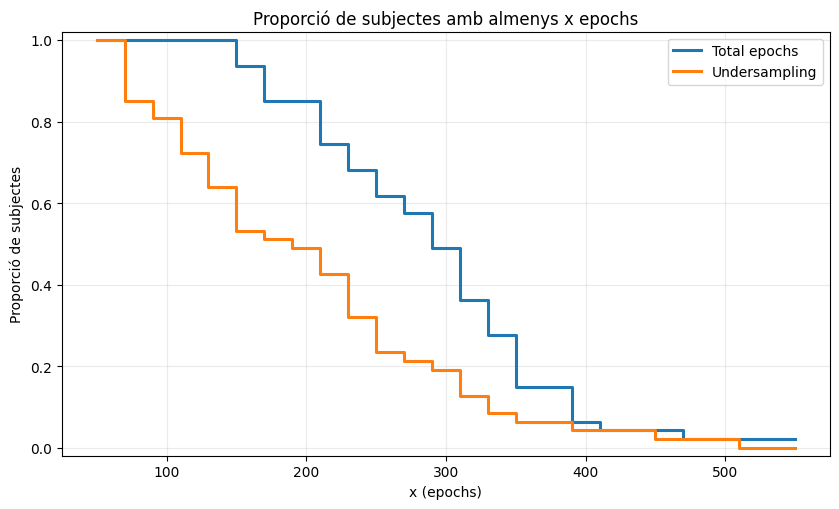

>=  50 epochs -> total: 100.0% | undersampling: 100.0%
>= 100 epochs -> total: 100.0% | undersampling: 72.3%
>= 150 epochs -> total: 93.6% | undersampling: 53.2%
>= 200 epochs -> total: 78.7% | undersampling: 46.8%
>= 250 epochs -> total: 61.7% | undersampling: 23.4%
>= 300 epochs -> total: 42.6% | undersampling: 17.0%
>= 350 epochs -> total: 14.9% | undersampling: 6.4%
>= 400 epochs -> total: 6.4% | undersampling: 4.3%
>= 450 epochs -> total: 4.3% | undersampling: 2.1%
>= 500 epochs -> total: 2.1% | undersampling: 0.0%


In [31]:
# Plot germà: proporció de subjectes amb >= x epochs
vals_total = df_epochs_subjecte["n_total_epochs"].to_numpy(dtype=float)
vals_us = df_balanceig["n_balancejable"].to_numpy(dtype=float)

x_min = int(min(vals_total.min(), vals_us.min()))
x_max = int(max(vals_total.max(), vals_us.max()))
# Pas de 10 epochs per mantenir el gràfic net i interpretable
x_grid = np.arange(x_min, x_max + 1, 20)

prop_total = np.array([(vals_total >= x).mean() for x in x_grid], dtype=float)
prop_us = np.array([(vals_us >= x).mean() for x in x_grid], dtype=float)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.step(x_grid, prop_total, where="post", color="tab:blue", linewidth=2.2, label="Total epochs")
ax.step(x_grid, prop_us, where="post", color="tab:orange", linewidth=2.2, label="Undersampling")

ax.set_title("Proporció de subjectes amb almenys x epochs")
ax.set_xlabel("x (epochs)")
ax.set_ylabel("Proporció de subjectes")
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Petit resum numèric en alguns llindars clau
for x in range(50, 501, 50):
    p_total = (vals_total >= x).mean()
    p_us = (vals_us >= x).mean()
    print(f">= {x:3d} epochs -> total: {p_total:.1%} | undersampling: {p_us:.1%}")

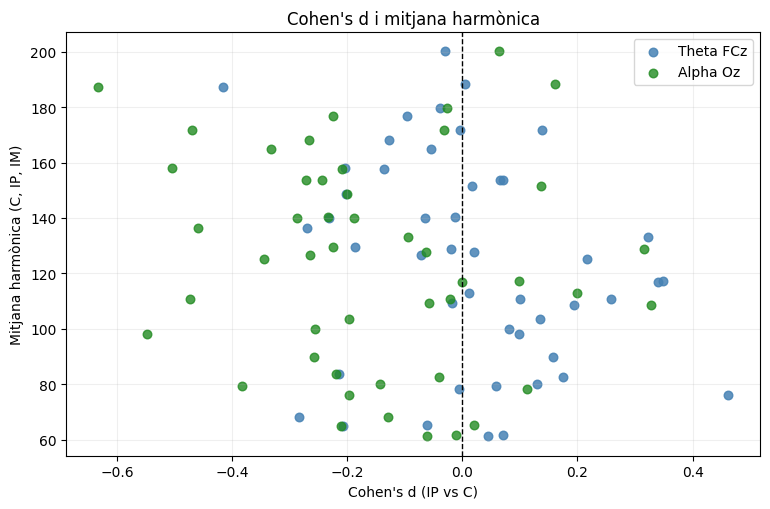

In [32]:
# x = Cohen's d, y = mitjana harmònica
df_plot = df_theta_sorted.copy()
fig, ax = plt.subplots(figsize=(7.8, 5.2))
ax.scatter(
    df_plot["cohens_d_theta_fcz"], df_plot["n_harm_3classes"], color="steelblue", alpha=0.85, s=38, label="Theta FCz"
)
ax.scatter(
    df_plot["cohens_d_alpha_oz"], df_plot["n_harm_3classes"], color="forestgreen", alpha=0.8, s=38, label="Alpha Oz"
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Cohen's d (IP vs C)")
ax.set_ylabel("Mitjana harmònica (C, IP, IM)")
ax.set_title("Cohen's d i mitjana harmònica")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mitjana_harmonica.png", dpi=300, bbox_inches="tight")
plt.show()

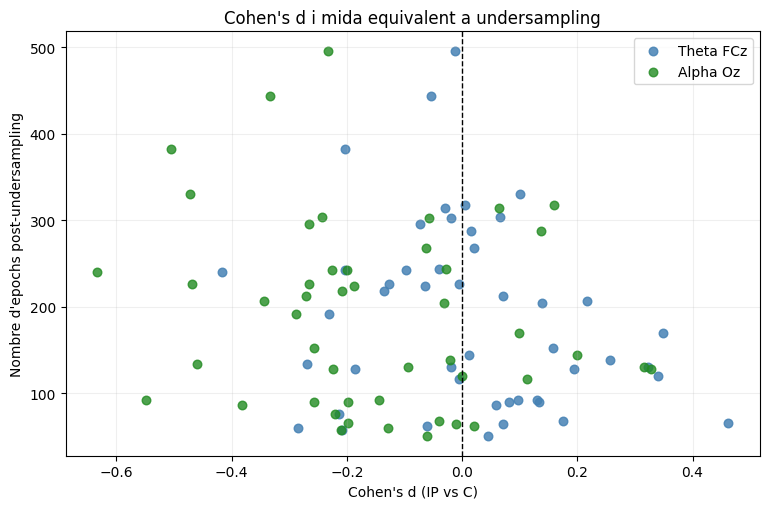

In [33]:
# x = Cohen's d, y = mida equivalent a undersampling
df_plot = df_theta_sorted.copy()
fig, ax = plt.subplots(figsize=(7.8, 5.2))
ax.scatter(
    df_plot["cohens_d_theta_fcz"], df_plot["n_balanced_ci"], color="steelblue", alpha=0.85, s=38, label="Theta FCz"
)
ax.scatter(
    df_plot["cohens_d_alpha_oz"], df_plot["n_balanced_ci"], color="forestgreen", alpha=0.8, s=38, label="Alpha Oz"
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Cohen's d (IP vs C)")
ax.set_ylabel("Nombre d'epochs post-undersampling")
ax.set_title("Cohen's d i mida equivalent a undersampling")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mida_undersampling.png", dpi=300, bbox_inches="tight")
plt.show()

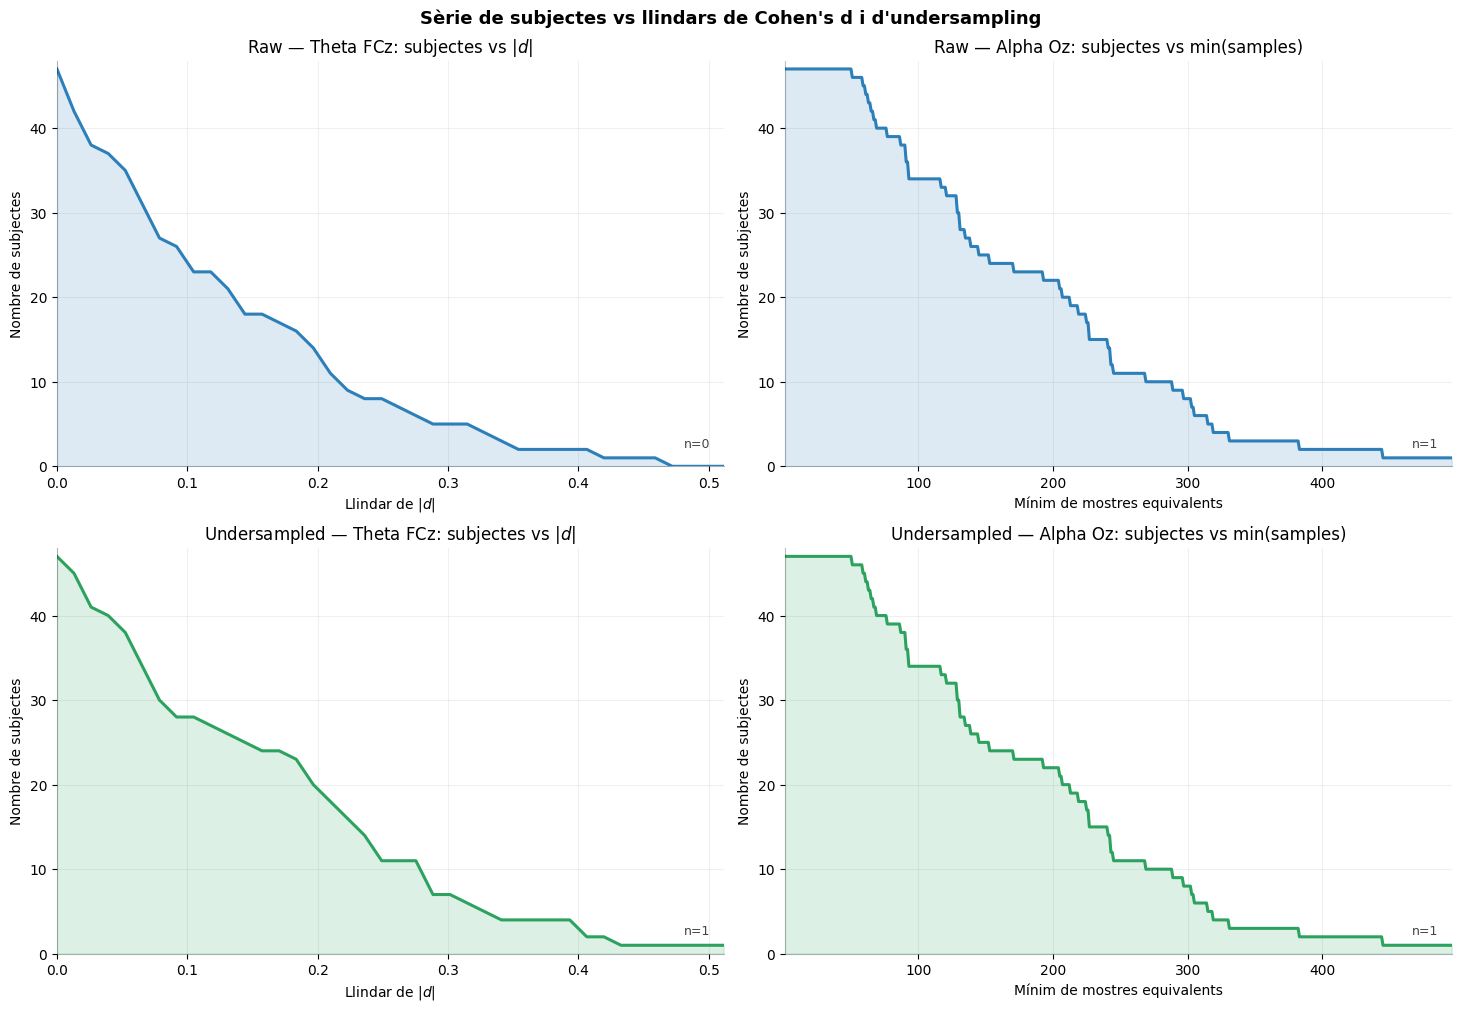

In [34]:
# Sèrie de plots: nombre de subjectes en funció del llindar de Cohen's d i del mínim de mostres
# Farem un grid 2x2 amb un bucle imbricat: files = raw/undersampled, columnes = |d| i min(samples)

series_specs = [
    (
        "raw",
        {
            "theta": df_cohens["cohens_d_theta_fcz"].abs().to_numpy(),
            "alpha": df_cohens["cohens_d_alpha_oz"].abs().to_numpy(),
        },
    ),
    (
        "undersampled",
        {
            "theta": df_cohens["cohens_d_theta_fcz_us"].abs().to_numpy(),
            "alpha": df_cohens["cohens_d_alpha_oz_us"].abs().to_numpy(),
        },
    ),
]

sample_counts = df_cohens["n_balanced_ci"].to_numpy()
d_limits = {
    "theta": float(np.nanmax(df_cohens[["cohens_d_theta_fcz", "cohens_d_theta_fcz_us"]].abs().to_numpy())),
    "alpha": float(np.nanmax(df_cohens[["cohens_d_alpha_oz", "cohens_d_alpha_oz_us"]].abs().to_numpy())),
}
d_thresholds = {key: np.linspace(0.0, max(value, 1e-6), 40) for key, value in d_limits.items()}
sample_thresholds = np.arange(1, int(np.nanmax(sample_counts)) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14.5, 10), constrained_layout=True)
panel_info = [("theta", "Theta FCz"), ("alpha", "Alpha Oz")]
row_colors = {"raw": "#2C7FB8", "undersampled": "#2CA25F"}
row_titles = {"raw": "Raw", "undersampled": "Undersampled"}

for row_idx, (row_key, values_by_band) in enumerate(series_specs):
    for col_idx, (band_key, band_label) in enumerate(panel_info):
        ax = axes[row_idx, col_idx]
        values = values_by_band[band_key]
        color = row_colors[row_key]

        if col_idx == 0:
            thresholds = d_thresholds[band_key]
            counts = np.array([(values >= thr).sum() for thr in thresholds])
            ax.plot(thresholds, counts, color=color, linewidth=2.2)
            ax.fill_between(thresholds, counts, alpha=0.16, color=color)
            ax.set_xlabel(r"Llindar de $|d|$")
            ax.set_ylabel("Nombre de subjectes")
            ax.set_title(f"{row_titles[row_key]} — {band_label}: subjectes vs $|d|$")
            ax.set_xlim(thresholds.min(), thresholds.max())
            ax.set_ylim(0, len(df_cohens) + 1)
        else:
            thresholds = sample_thresholds
            counts = np.array([(sample_counts >= thr).sum() for thr in thresholds])
            ax.plot(thresholds, counts, color=color, linewidth=2.2)
            ax.fill_between(thresholds, counts, alpha=0.16, color=color)
            ax.set_xlabel("Mínim de mostres equivalents")
            ax.set_ylabel("Nombre de subjectes")
            ax.set_title(f"{row_titles[row_key]} — {band_label}: subjectes vs min(samples)")
            ax.set_xlim(thresholds.min(), thresholds.max())
            ax.set_ylim(0, len(df_cohens) + 1)

        ax.grid(alpha=0.18, linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.spines["left"].set_alpha(0.25)
        ax.spines["bottom"].set_alpha(0.25)
        ax.text(
            0.98,
            0.04,
            f"n={counts[-1]:d}",
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=9,
            color="#444444",
        )

fig.suptitle("Sèrie de subjectes vs llindars de Cohen's d i d'undersampling", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_subjectes_vs_llindars_nested_grid.png", dpi=300, bbox_inches="tight")
plt.show()

Sembla que tant 100 com 200 són bons thresholds i es troben en punts relativament estables de la corba. Amb un llindar mínim de 100 trials per classe, es manté la majoria de subjectes i es redueix el risc de sobreajustar-se a subjectes amb molt poques dades. Amb 200 trials, es redueix encara més el risc però es perden més subjectes. En aquest cas, sembla que 100 és un bon compromís entre mantenir subjectes i garantir una estimació robusta de Cohen's d.

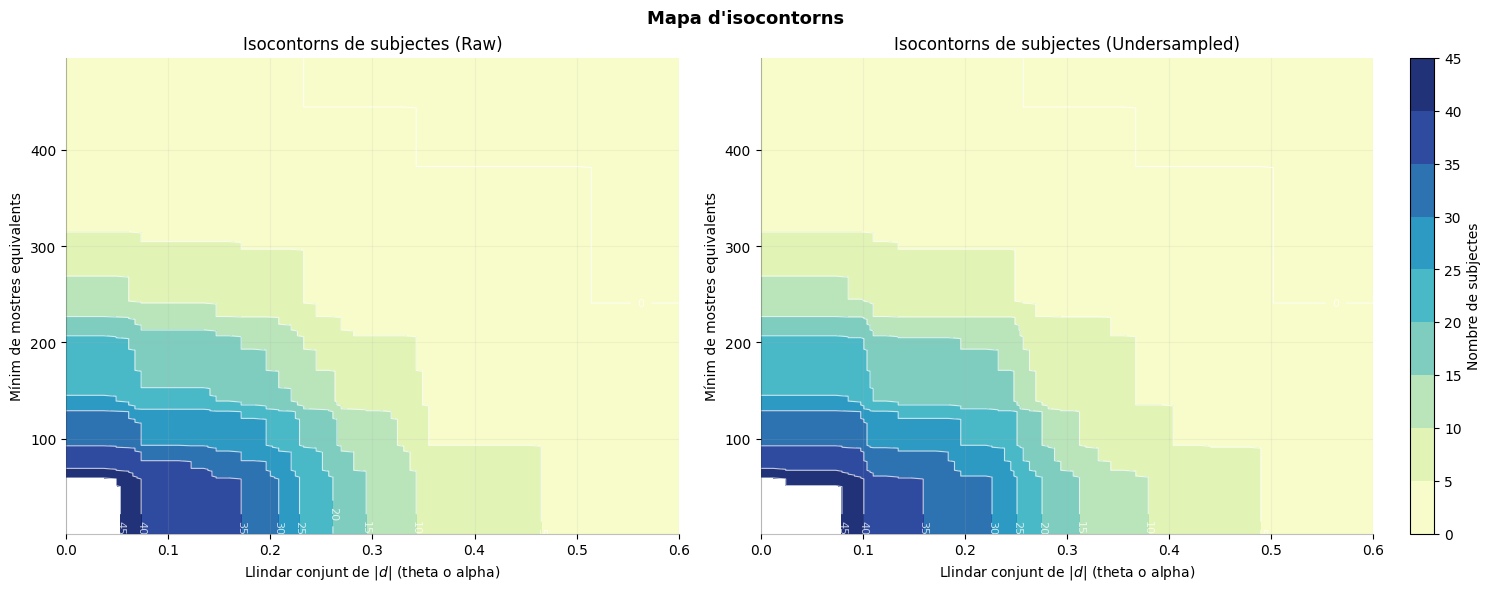

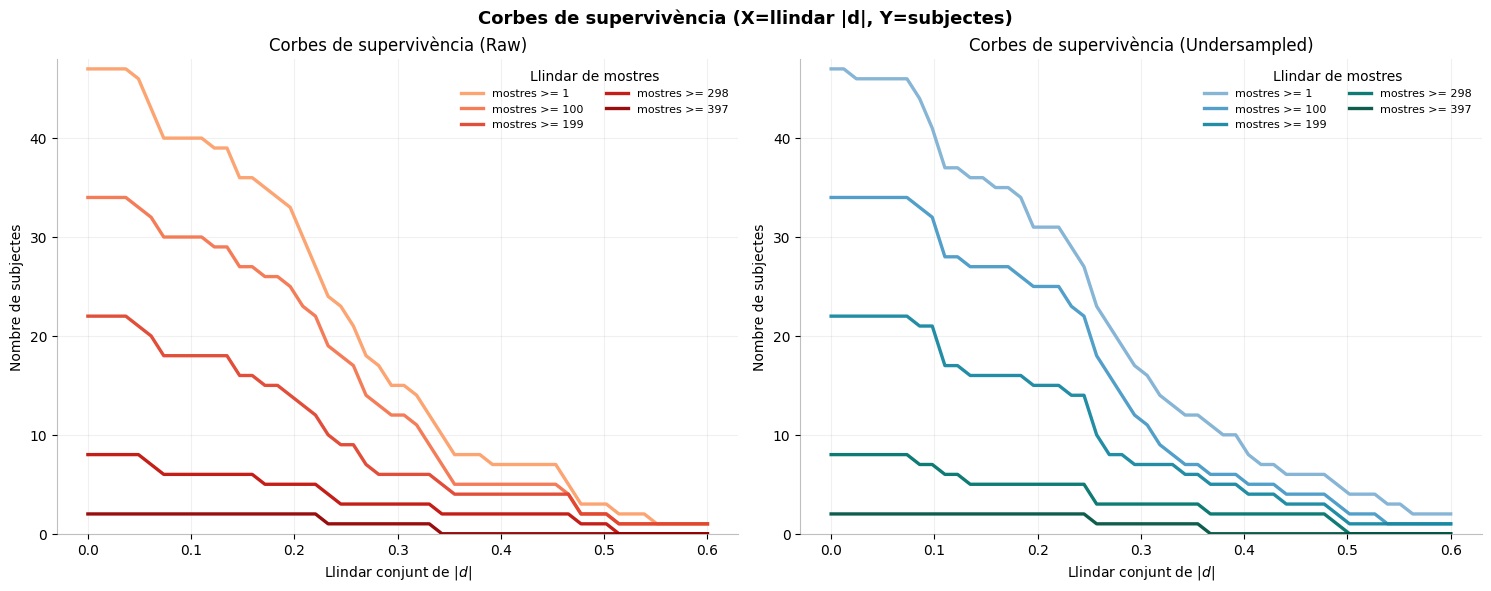

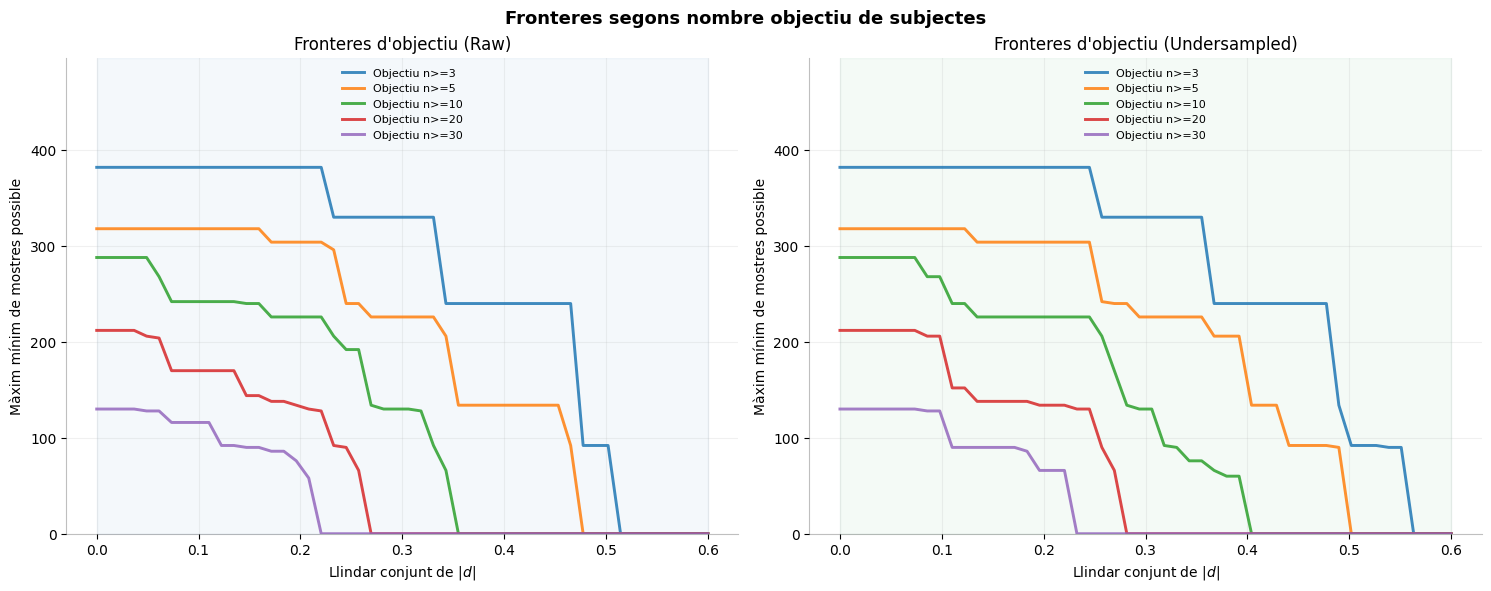

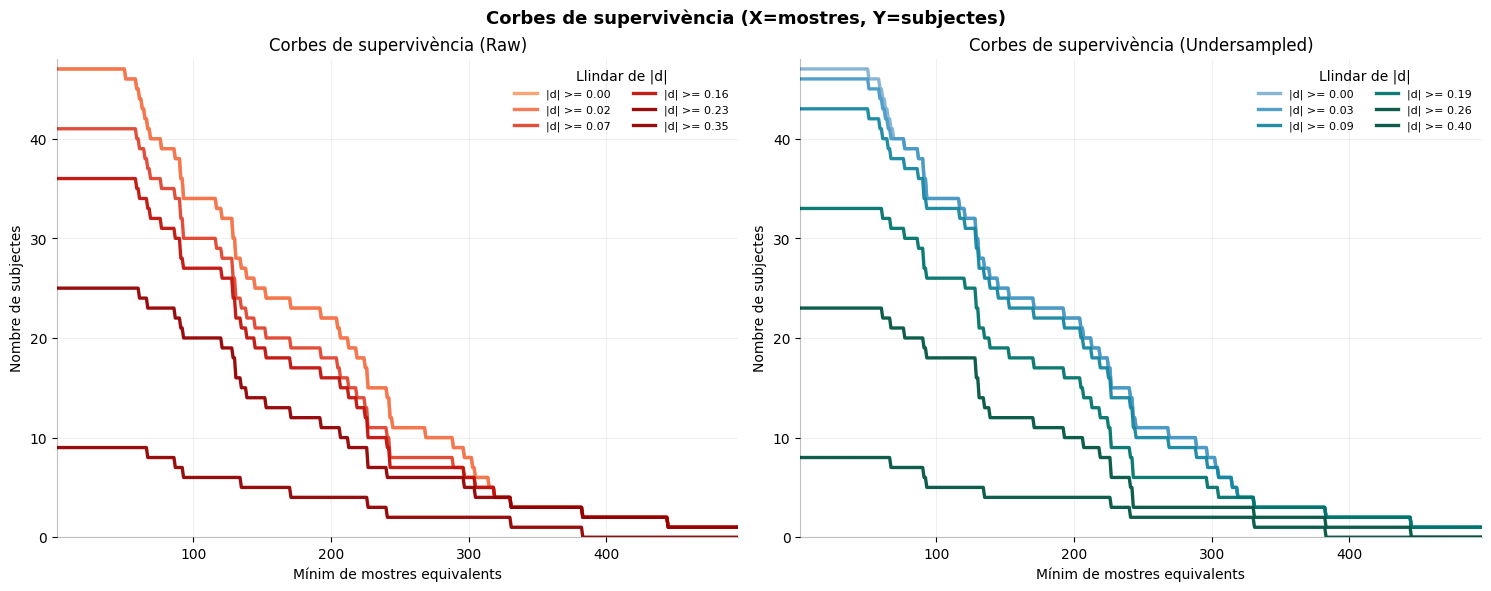

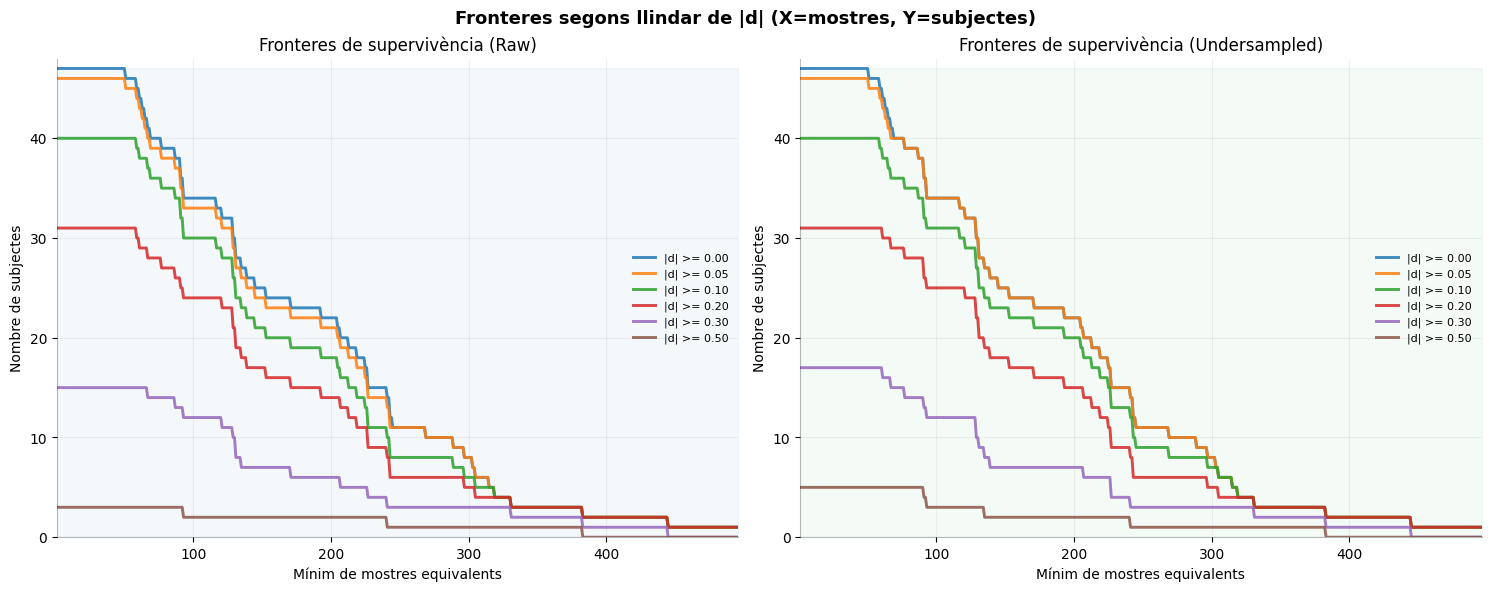

In [35]:
sample_counts = df_cohens["n_balanced_ci"].to_numpy()
d_thr_max = float(
    np.nanmax(
        df_cohens[
            [
                "cohens_d_theta_fcz",
                "cohens_d_alpha_oz",
                "cohens_d_theta_fcz_us",
                "cohens_d_alpha_oz_us",
            ]
        ]
        .abs()
        .to_numpy()
    )
)

d_thresholds = np.linspace(0.0, 0.6, 50)
sample_thresholds = np.arange(1, int(np.nanmax(sample_counts)) + 1)

specs = {
    "Raw": {
        "theta": df_cohens["cohens_d_theta_fcz"].abs().to_numpy(),
        "alpha": df_cohens["cohens_d_alpha_oz"].abs().to_numpy(),
        "color": "#2C7FB8",
    },
    "Undersampled": {
        "theta": df_cohens["cohens_d_theta_fcz_us"].abs().to_numpy(),
        "alpha": df_cohens["cohens_d_alpha_oz_us"].abs().to_numpy(),
        "color": "#2CA25F",
    },
}


def build_grid(theta_vals, alpha_vals, d_thresholds):
    grid = np.zeros((len(sample_thresholds), len(d_thresholds)), dtype=int)
    for i, n_thr in enumerate(sample_thresholds):
        for j, d_thr in enumerate(d_thresholds):
            keep = ((theta_vals >= d_thr) | (alpha_vals >= d_thr)) & (sample_counts >= n_thr)
            grid[i, j] = int(keep.sum())
    return grid


grid_by_name = {name: build_grid(vals["theta"], vals["alpha"], d_thresholds) for name, vals in specs.items()}

# --- Plot A: Isocontorns suaus (raw vs undersampled) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)
for ax, (name, vals) in zip(axes, specs.items()):
    grid = grid_by_name[name]
    levels = np.arange(0, len(df_cohens) + 1, max(1, len(df_cohens) // 8))

    cf = ax.contourf(
        d_thresholds,
        sample_thresholds,
        grid,
        levels=levels,
        cmap="YlGnBu",
        alpha=0.95,
    )
    c = ax.contour(
        d_thresholds,
        sample_thresholds,
        grid,
        levels=levels,
        colors="white",
        linewidths=0.8,
        alpha=0.75,
    )
    ax.clabel(c, fmt="%d", fontsize=8)

    ax.set_title(f"Isocontorns de subjectes ({name})")
    ax.set_xlabel(r"Llindar conjunt de $|d|$ (theta o alpha)")
    ax.set_ylabel("Mínim de mostres equivalents")
    ax.grid(alpha=0.14)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02)
cbar.set_label("Nombre de subjectes")
fig.suptitle("Mapa d'isocontorns", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_isocontorns.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot B: Corbes de supervivència clàssiques (X=llindar |d|, Y=subjectes) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

palette_by_name = {
    "Raw": plt.cm.OrRd(np.linspace(0.45, 0.95, 5)),
    "Undersampled": plt.cm.PuBuGn(np.linspace(0.45, 0.95, 5)),
}

for ax, (name, vals) in zip(axes, specs.items()):
    # Inclou 0 percentile (mínim de mostres) per veure l'escenari més laxe.
    q_levels = np.quantile(sample_thresholds, [0.0, 0.2, 0.4, 0.6, 0.8]).astype(int)
    q_levels = np.unique(np.clip(q_levels, sample_thresholds.min(), sample_thresholds.max()))
    palette = palette_by_name[name]

    for k, n_thr in enumerate(q_levels):
        counts = []
        for d_thr in d_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            d_thresholds,
            counts,
            color=palette[min(k, len(palette) - 1)],
            linewidth=2.4,
            alpha=0.95,
            label=f"mostres >= {n_thr}",
        )

    ax.set_title(f"Corbes de supervivència ({name})")
    ax.set_xlabel(r"Llindar conjunt de $|d|$")
    ax.set_ylabel("Nombre de subjectes")
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8, ncol=2, title="Llindar de mostres")

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Corbes de supervivència (X=llindar |d|, Y=subjectes)", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_corbes_supervivencia_x_d.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot C: Fronteres clàssiques (X=llindar |d|, Y=mostres) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

n_targets = [3, 5, 10, 20, 30]
n_targets = [n for n in n_targets if n <= len(df_cohens)]
if len(n_targets) == 0:
    n_targets = [max(1, len(df_cohens) // 2)]

for ax, (name, vals) in zip(axes, specs.items()):
    grid = grid_by_name[name]
    color = vals["color"]

    for target_n in n_targets:
        frontier = []
        for j in range(len(d_thresholds)):
            col = grid[:, j]
            rows_ok = np.where(col >= target_n)[0]
            if len(rows_ok) == 0:
                frontier.append(0)
            else:
                frontier.append(sample_thresholds[rows_ok.max()])

        ax.plot(
            d_thresholds,
            frontier,
            linewidth=2.1,
            alpha=0.85,
            label=f"Objectiu n>={target_n}",
        )

    ax.fill_between(d_thresholds, 0, np.nanmax(sample_thresholds), color=color, alpha=0.05)
    ax.set_title(f"Fronteres d'objectiu ({name})")
    ax.set_xlabel(r"Llindar conjunt de $|d|$")
    ax.set_ylabel("Màxim mínim de mostres possible")
    ax.set_ylim(0, sample_thresholds.max())
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Fronteres segons nombre objectiu de subjectes", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_fronteres_objectiu_x_d.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot D: Corbes de supervivència noves (X=mostres, Y=subjectes) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

# Paletes separades per millorar la visibilitat entre corbes i entre panells.
palette_by_name = {
    "Raw": plt.cm.OrRd(np.linspace(0.45, 0.95, 5)),
    "Undersampled": plt.cm.PuBuGn(np.linspace(0.45, 0.95, 5)),
}

for ax, (name, vals) in zip(axes, specs.items()):
    # Corbes per quantils de llindar de |d|; cada punt és n_subjectes amb mostres >= x.
    d_pool = np.concatenate([vals["theta"], vals["alpha"]])
    d_levels = np.quantile(d_pool, [0.0, 0.1, 0.3, 0.5, 0.7, 0.9])
    d_levels = np.unique(np.clip(d_levels, d_thresholds.min(), d_thresholds.max()))
    palette = palette_by_name[name]

    for k, d_thr in enumerate(d_levels):
        counts = []
        for n_thr in sample_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            sample_thresholds,
            counts,
            color=palette[min(k, len(palette) - 1)],
            linewidth=2.4,
            alpha=0.95,
            label=f"|d| >= {d_thr:.2f}",
        )

    ax.set_title(f"Corbes de supervivència ({name})")
    ax.set_xlabel("Mínim de mostres equivalents")
    ax.set_ylabel("Nombre de subjectes")
    ax.set_xlim(sample_thresholds.min(), sample_thresholds.max())
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8, ncol=2, title="Llindar de |d|")

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Corbes de supervivència (X=mostres, Y=subjectes)", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_corbes_supervivencia_x_samples.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot E: Fronteres noves per llindars fixos de |d| (X=mostres, Y=subjectes) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

d_targets = [0.00, 0.05, 0.10, 0.20, 0.30, 0.50]
d_targets = [d for d in d_targets if d <= d_thresholds.max()]
if len(d_targets) == 0:
    d_targets = [float(d_thresholds.max())]

for ax, (name, vals) in zip(axes, specs.items()):
    color = vals["color"]

    for d_thr in d_targets:
        counts = []
        for n_thr in sample_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            sample_thresholds,
            counts,
            linewidth=2.1,
            alpha=0.85,
            label=f"|d| >= {d_thr:.2f}",
        )

    ax.fill_between(sample_thresholds, 0, len(df_cohens), color=color, alpha=0.05)
    ax.set_title(f"Fronteres de supervivència ({name})")
    ax.set_xlabel("Mínim de mostres equivalents")
    ax.set_ylabel("Nombre de subjectes")
    ax.set_xlim(sample_thresholds.min(), sample_thresholds.max())
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Fronteres segons llindar de |d| (X=mostres, Y=subjectes)", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_fronteres_objectiu_x_samples.png", dpi=300, bbox_inches="tight")
plt.show()

In [36]:
# Mínim nombre de 130 trials balancejables (C + IP) per garantir una base mínima sòlida.
MIN_BALANCED_TRIALS = 130
eligible_subjects = df_cohens[df_cohens["n_balanced_ci"] >= MIN_BALANCED_TRIALS]
print(f"Subjectes elegibles amb >= {MIN_BALANCED_TRIALS} trials balancejables: {len(eligible_subjects)}")
display(
    eligible_subjects[["subjecte", "cohens_d_theta_fcz_us", "cohens_d_alpha_oz_us", "n_balanced_ci"]]
    .head(10)
    .style.hide(axis="index")
    .format({"n_balanced_ci": "{:.1f}", "score_seleccio": "{:.3f}"})
)

Subjectes elegibles amb >= 130 trials balancejables: 30


subjecte,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,n_balanced_ci
P002,0.215705,-0.400586,206.0
P003,-0.218469,-0.501443,382.0
P004,-0.153976,0.307149,130.0
P005,-0.283649,-0.220500,242.0
P009,-0.143990,-0.266939,242.0
P010,-0.072616,0.109491,314.0
P013,-0.044237,0.133450,318.0
P014,0.319052,-0.057904,138.0
P015,0.001961,-0.106888,268.0
P016,-0.060671,-0.100098,244.0


In [37]:
# Rànquing final de subjectes (undersampled): combina |d| theta, |d| alpha i mida mostral
def minmax_01(s: pd.Series) -> pd.Series:
    s = s.astype(float)
    lo, hi = float(np.nanmin(s)), float(np.nanmax(s))
    if np.isclose(hi - lo, 0.0):
        return pd.Series(np.zeros(len(s), dtype=float), index=s.index)
    return (s - lo) / (hi - lo)


# Es poden ajustar aquests pesos si volem prioritzar més l'efecte (Cohen's d) o més la mida mostral.
W_EFFECT = 0.75
W_SIZE = 0.25

rank_df = eligible_subjects[["subjecte", "cohens_d_theta_fcz_us", "cohens_d_alpha_oz_us", "n_balanced_ci"]].copy()
rank_df["d_theta_us_abs"] = rank_df["cohens_d_theta_fcz_us"].abs()
rank_df["d_alpha_us_abs"] = rank_df["cohens_d_alpha_oz_us"].abs()

# Efecte combinat: mitjana geomètrica perquè theta i alpha hagin de ser tots dos alts.
rank_df["d_combo_us"] = np.sqrt(rank_df["d_theta_us_abs"] * rank_df["d_alpha_us_abs"])
rank_df["d_combo_us_norm"] = minmax_01(rank_df["d_combo_us"])
rank_df["n_balanced_norm"] = minmax_01(rank_df["n_balanced_ci"])

rank_df["score_seleccio"] = W_EFFECT * rank_df["d_combo_us_norm"] + W_SIZE * rank_df["n_balanced_norm"]

rank_df = rank_df.sort_values("score_seleccio", ascending=False).reset_index(drop=True)

cols_show = [
    "subjecte",
    "d_theta_us_abs",
    "d_alpha_us_abs",
    "d_combo_us",
    "n_balanced_ci",
    "score_seleccio",
]

print("Top 10 subjectes")
display(
    rank_df.head(10)[cols_show]
    .style.hide(axis="index")
    .format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "d_combo_us": "{:.3f}",
            "n_balanced_ci": "{:.1f}",
            "score_seleccio": "{:.3f}",
        }
    )
)

print("Pitjors 5 subjectes")
display(
    rank_df.tail(5)[cols_show]
    .style.hide(axis="index")
    .format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "d_combo_us": "{:.3f}",
            "n_balanced_ci": "{:.1f}",
            "score_seleccio": "{:.3f}",
        }
    )
)

Top 10 subjectes


subjecte,d_theta_us_abs,d_alpha_us_abs,d_combo_us,n_balanced_ci,score_seleccio
P057,0.511,0.660,0.581,240.0,0.825
P058,0.420,0.539,0.476,134.0,0.614
P003,0.218,0.501,0.331,382.0,0.593
P002,0.216,0.401,0.294,206.0,0.424
P017,0.228,0.337,0.278,226.0,0.416
P005,0.284,0.220,0.250,242.0,0.391
P021,0.243,0.271,0.257,192.0,0.366
P065,0.043,0.358,0.125,444.0,0.364
P051,0.189,0.265,0.224,218.0,0.340
P066,0.054,0.489,0.162,330.0,0.335


Pitjors 5 subjectes


subjecte,d_theta_us_abs,d_alpha_us_abs,d_combo_us,n_balanced_ci,score_seleccio
P022,0.028,0.256,0.084,212.0,0.152
P033,0.190,0.020,0.061,204.0,0.116
P053,0.001,0.099,0.011,288.0,0.108
P046,0.075,0.093,0.083,144.0,0.104
P015,0.002,0.107,0.014,268.0,0.098


In [38]:
# Selecció automàtica: 5 punts d'inflexió de la corba de supervivència
# Identifica transicions reals on canvia significativament la velocitat de caiguda de subjectes
# AMB SEPARABILITAT: punts distants entre ells

score_thresholds = np.linspace(0.0, 1.0, 101)

# Calcular utilitat per a cada llindar
utility_rows = []
for t in score_thresholds:
    sel = rank_df[rank_df["score_seleccio"] >= t]
    n_sel = int(len(sel))
    if n_sel == 0:
        mean_score = np.nan
        utility = np.nan
    else:
        mean_score = float(sel["score_seleccio"].mean())
        utility = float(np.sqrt(n_sel / len(rank_df)) * mean_score)
    utility_rows.append(
        {
            "llindar": float(t),
            "n_subjectes": n_sel,
            "frac_subjectes": n_sel / len(rank_df),
            "score_mitja": mean_score,
            "utility": utility,
        }
    )

df_utility = pd.DataFrame(utility_rows).dropna().sort_values("llindar").reset_index(drop=True)

# Per a cada llindar t, mostra quants subjectes tenen score >= t.
survival_counts = np.array([(rank_df["score_seleccio"] >= t).sum() for t in score_thresholds], dtype=int)

# Calcular derivada numèrica (canvi de N per pas de threshold)
diffs = np.diff(survival_counts)
abs_diffs = np.abs(diffs)

# Calcular "acceleració" (canvi de la derivada - on canvia la velocitat de caigda)
accel = np.diff(abs_diffs)

# Identificar punts on hi ha pics d'acceleració (transicions)
threshold_accel = np.percentile(accel, 80)  # Top 30% de canvis
inflection_indices = np.where(accel > threshold_accel)[0]

# Agrupar índexs propers (evitar duplicats)
if len(inflection_indices) > 0:
    inflection_points = []
    current_group = [inflection_indices[0]]
    for i in range(1, len(inflection_indices)):
        if inflection_indices[i] - inflection_indices[i - 1] <= 2:
            current_group.append(inflection_indices[i])
        else:
            inflection_points.append(int(np.mean(current_group)))
            current_group = [inflection_indices[i]]
    inflection_points.append(int(np.mean(current_group)))
else:
    inflection_points = []

# Convertir a índexs de df_utility
inflection_thresholds = []
for idx in inflection_points:
    if idx < len(score_thresholds):
        thr = score_thresholds[idx]
        # Buscar el llindar més proper a df_utility
        closest_idx = int((df_utility["llindar"] - thr).abs().idxmin())
        if closest_idx not in [x[0] for x in inflection_thresholds]:
            n_subj = int(df_utility.loc[closest_idx, "n_subjectes"])
            score_mean = float(df_utility.loc[closest_idx, "score_mitja"])
            utility_val = float(df_utility.loc[closest_idx, "utility"])
            inflection_thresholds.append((closest_idx, thr, n_subj, score_mean, utility_val))

# Ordenar per utilitat descendent
inflection_thresholds_sorted = sorted(inflection_thresholds, key=lambda x: x[4], reverse=True)

# Seleccionar 5 punts amb separabilitat mínima (distància mínima entre llindars: 0.05)
MIN_THRESHOLD_GAP = 0.05
selected_points = []
for idx, thr, n_subj, score_mean, util in inflection_thresholds_sorted:
    # Comprovar si aquest punt és prou allunyat dels ja seleccionats
    if len(selected_points) == 0:
        selected_points.append((idx, thr, n_subj, score_mean, util))
    else:
        min_gap_to_existing = min(abs(thr - sp[1]) for sp in selected_points)
        if min_gap_to_existing >= MIN_THRESHOLD_GAP:
            selected_points.append((idx, thr, n_subj, score_mean, util))
    if len(selected_points) == 5:
        break

# Convertir a DataFrame final
selected_indices = [sp[0] for sp in selected_points]
df_key = (
    df_utility.loc[selected_indices, ["llindar", "n_subjectes", "score_mitja", "utility"]]
    .sort_values("llindar")  # Ordenar per llindar creixent per millor visualització
    .reset_index(drop=True)
)

display(
    df_key.style.hide(axis="index").format(
        {
            "llindar": "{:.3f}",
            "n_subjectes": "{:d}",
            "score_mitja": "{:.3f}",
            "utility": "{:.3f}",
        }
    )
)

# Mostrar selecció top-10 i automàtica per referència
top_pairs = [
    (row["subjecte"], f"{row['score_seleccio']:.2f}")
    for _, row in rank_df.head(10)[["subjecte", "score_seleccio"]].iterrows()
]

auto_threshold = float(df_key.loc[0, "llindar"])  # Millor proposició per utilitat
auto_df = rank_df[rank_df["score_seleccio"] >= auto_threshold][["subjecte", "score_seleccio"]]
auto_pairs = [(row["subjecte"], f"{row['score_seleccio']:.2f}") for _, row in auto_df.iterrows()]

print(f"Top-10 (Subj, score):")
print(top_pairs)
print(f"\nSelecció automàtica (Proposició 1, Subj, score) [{len(auto_pairs)}]:")
print(auto_pairs)

llindar,n_subjectes,score_mitja,utility
0.080,30,0.295,0.295
0.190,22,0.353,0.302
0.300,13,0.434,0.285
0.350,8,0.499,0.258
0.590,3,0.677,0.214


Top-10 (Subj, score):
[('P057', '0.83'), ('P058', '0.61'), ('P003', '0.59'), ('P002', '0.42'), ('P017', '0.42'), ('P005', '0.39'), ('P021', '0.37'), ('P065', '0.36'), ('P051', '0.34'), ('P066', '0.34')]

Selecció automàtica (Proposició 1, Subj, score) [30]:
[('P057', '0.83'), ('P058', '0.61'), ('P003', '0.59'), ('P002', '0.42'), ('P017', '0.42'), ('P005', '0.39'), ('P021', '0.37'), ('P065', '0.36'), ('P051', '0.34'), ('P066', '0.34'), ('P048', '0.33'), ('P062', '0.32'), ('P009', '0.32'), ('P067', '0.28'), ('P004', '0.27'), ('P030', '0.26'), ('P023', '0.24'), ('P010', '0.23'), ('P045', '0.22'), ('P013', '0.21'), ('P068', '0.21'), ('P061', '0.20'), ('P014', '0.17'), ('P016', '0.17'), ('P025', '0.16'), ('P022', '0.15'), ('P033', '0.12'), ('P053', '0.11'), ('P046', '0.10'), ('P015', '0.10')]


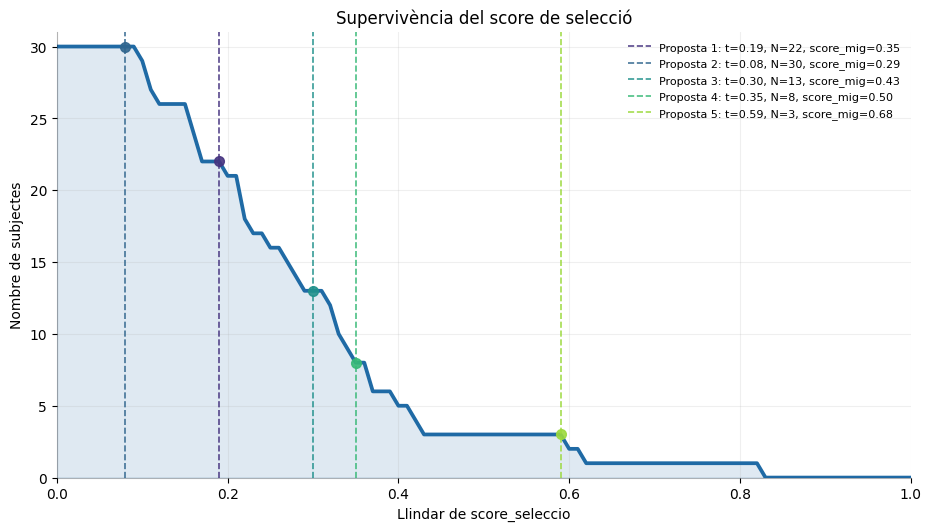

In [39]:
# Plot de supervivència del score de selecció amb llindars proposats

# Ordenem propostes per balanceig (utility): Proposta 1 = millor, ..., Proposta 5 = cinquena millor.
proposed_df = (
    df_key.sort_values("utility", ascending=False)
    .dropna(subset=["llindar"])
    .drop_duplicates(subset=["llindar"], keep="first")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
ax.plot(
    score_thresholds,
    survival_counts,
    color="#1f6aa5",
    linewidth=2.7,
)
ax.fill_between(score_thresholds, survival_counts, color="#1f6aa5", alpha=0.14)

th_colors = plt.cm.viridis(np.linspace(0.15, 0.85, max(1, len(proposed_df))))
proposal_handles = []
proposal_labels = []
for i, (_, row) in enumerate(proposed_df.iterrows()):
    thr = float(row["llindar"])
    n_subj = int(row["n_subjectes"])
    score_mean = float(row["score_mitja"])

    # Línia vertical al llindar
    line = ax.axvline(
        thr,
        color=th_colors[i],
        linestyle="--",
        linewidth=1.2,
        alpha=0.9,
    )

    # Marcador (punt) a la intersecció amb la corba
    ax.plot(thr, n_subj, "o", color=th_colors[i], markersize=7, alpha=0.9, zorder=5)

    proposal_handles.append(line)
    proposal_labels.append(f"Proposta {i + 1}: t={thr:.2f}, N={n_subj}, score_mig={score_mean:.2f}")

ax.set_title("Supervivència del score de selecció")
ax.set_xlabel("Llindar de score_seleccio")
ax.set_ylabel("Nombre de subjectes")
ax.set_xlim(0, 1)
ax.set_ylim(0, len(rank_df) + 1)
ax.grid(alpha=0.2)

# Llegenda només amb propostes, per maximitzar interpretabilitat.
ax.legend(proposal_handles, proposal_labels, frameon=False, loc="upper right", fontsize=8)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

plt.savefig(FIGURES_DIR / "cohens_d_score_seleccio_survival.png", dpi=300, bbox_inches="tight")
plt.show()

### Subjectes seleccionats

In [40]:
# Tots els subjectes seleccionats pel criteri automàtic, ordenats per score
subjectes_seleccionats_df = rank_df[rank_df["score_seleccio"] >= auto_threshold][
    ["subjecte", "d_theta_us_abs", "d_alpha_us_abs", "n_balanced_ci", "score_seleccio"]
]

subjectes_seleccionats_df = subjectes_seleccionats_df.rename(columns={"n_balanced_ci": "n_mostres"})
subjectes_seleccionats_df["n_mostres"] = subjectes_seleccionats_df["n_mostres"].astype("Int64")

subjectes_seleccionats_df = subjectes_seleccionats_df.sort_values("score_seleccio", ascending=False).reset_index(
    drop=True
)

# Únic dataset de selecció: el notebook de classificació ja podrà decidir quants agafar
subjectes_seleccionats_df.to_csv(TABLES_DIR / "subjectes_seleccionats.csv", index=False)

print(f"Subjectes seleccionats desats: {len(subjectes_seleccionats_df)}")
display(
    subjectes_seleccionats_df.style.hide(axis="index").format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "score_seleccio": "{:.3f}",
            "n_mostres": "{:d}",
        }
    )
)

Subjectes seleccionats desats: 30


subjecte,d_theta_us_abs,d_alpha_us_abs,n_mostres,score_seleccio
P057,0.511,0.660,240,0.825
P058,0.420,0.539,134,0.614
P003,0.218,0.501,382,0.593
P002,0.216,0.401,206,0.424
P017,0.228,0.337,226,0.416
P005,0.284,0.220,242,0.391
P021,0.243,0.271,192,0.366
P065,0.043,0.358,444,0.364
P051,0.189,0.265,218,0.340
P066,0.054,0.489,330,0.335


### ERP (temps vs. voltatge)
Senyal promig ± SEM per Fz, FCz, Cz. Serveix com a sanity check: si l'estímul produeix una resposta evocada clara i coherent entre condicions, les dades estan bé.

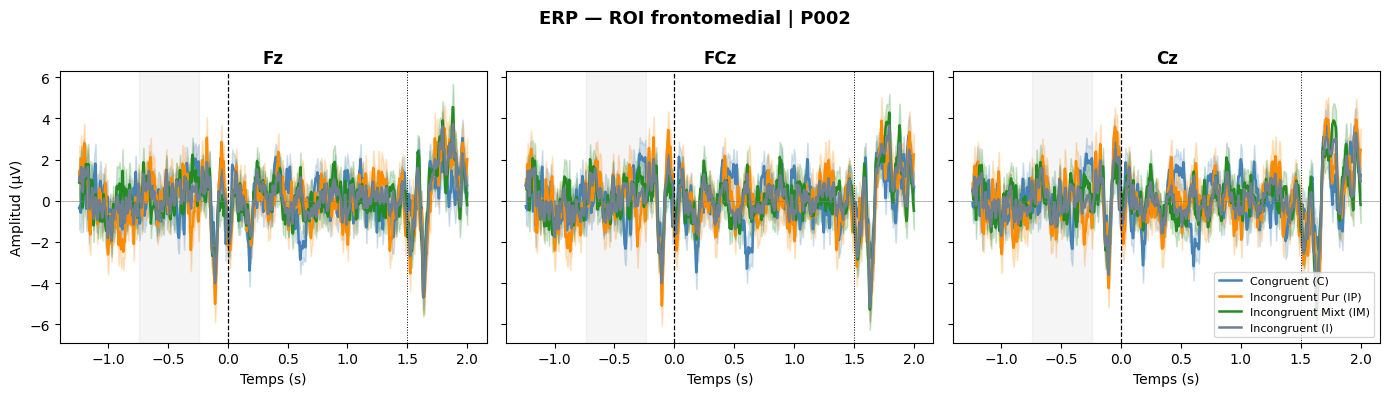

In [41]:
fig, axes = plt.subplots(1, len(ROI_FRONTAL), figsize=(14, 4), sharey=True)
times = epochs_all.times

for ax, ch in zip(axes, ROI_FRONTAL):
    for cond, ep in epochs_cond.items():
        data = ep.get_data(picks=[ch]).squeeze() * 1e6
        mean, sem = data.mean(axis=0), data.std(axis=0) / np.sqrt(len(ep))
        ax.plot(times, mean, label=LABELS[cond], color=COLORS[cond], linewidth=1.8)
        ax.fill_between(times, mean - sem, mean + sem, color=COLORS[cond], alpha=0.2)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.9)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.7)
    ax.axhline(0, color="gray", linewidth=0.4)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08)
    ax.set_title(ch, fontsize=12, fontweight="bold")
    ax.set_xlabel("Temps (s)")

axes[0].set_ylabel("Amplitud (µV)")
axes[-1].legend(fontsize=8, loc="lower right")
fig.suptitle(f"ERP — ROI frontomedial | {SUBJ}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "erp_roi_frontomedial_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### Theta power time-course (temps vs. potència, dB)
Potència theta (5–7 Hz) baseline-corregida, promig sobre Fz/FCz/Cz.
**Aquest és el plot central del TFG**: si el conflicte activa el sistema de monitoratge, IP ha de mostrar més potència theta que C durant la presentació de l'estímul.
Equivalent a la Figura 2B de l'article.

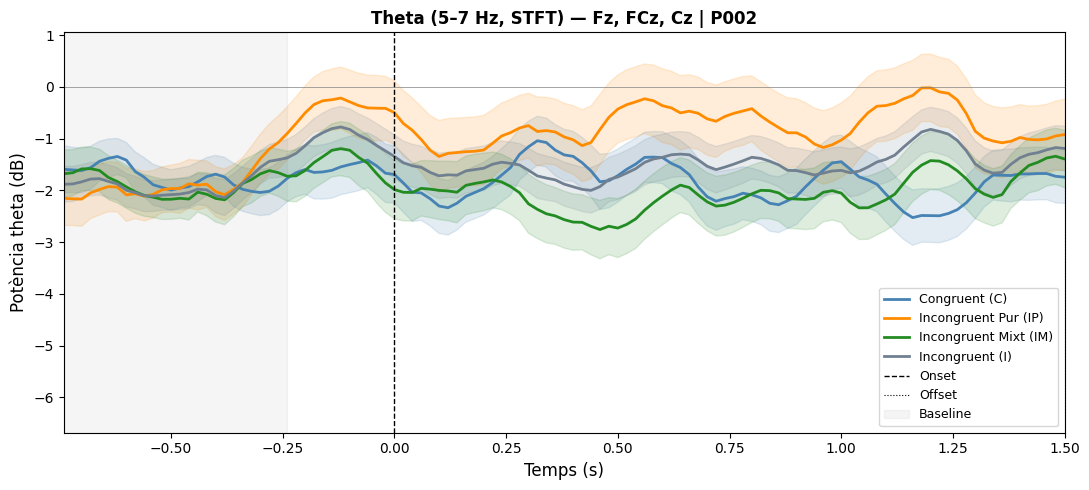

In [42]:
theta_tc = {}
for cond, ep in epochs_cond.items():
    t, mean_ts, sem_ts = stft_band_timecourse(ep, ROI_FRONTAL, band=(5, 7), baseline=BASELINE)
    theta_tc[cond] = (t, mean_ts, sem_ts)

fig, ax = plt.subplots(figsize=(11, 5))
for cond, (times, power_ts, sem_ts) in theta_tc.items():
    ax.plot(times, power_ts, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times, power_ts - sem_ts, power_ts + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Potència theta (dB)", fontsize=12)
ax.set_title(f"Theta (5–7 Hz, STFT) — Fz, FCz, Cz | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "theta_5_7hz_stft_roi_frontal_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### TFR map diferencial. Figura 3 (A i C)
Diferència de potència (IP−C i IP−IM) per tot l'espectre i tots els elèctrodes. 
Vermell = més potència en IP; blau = menys. Les bandes theta i alpha marcades.

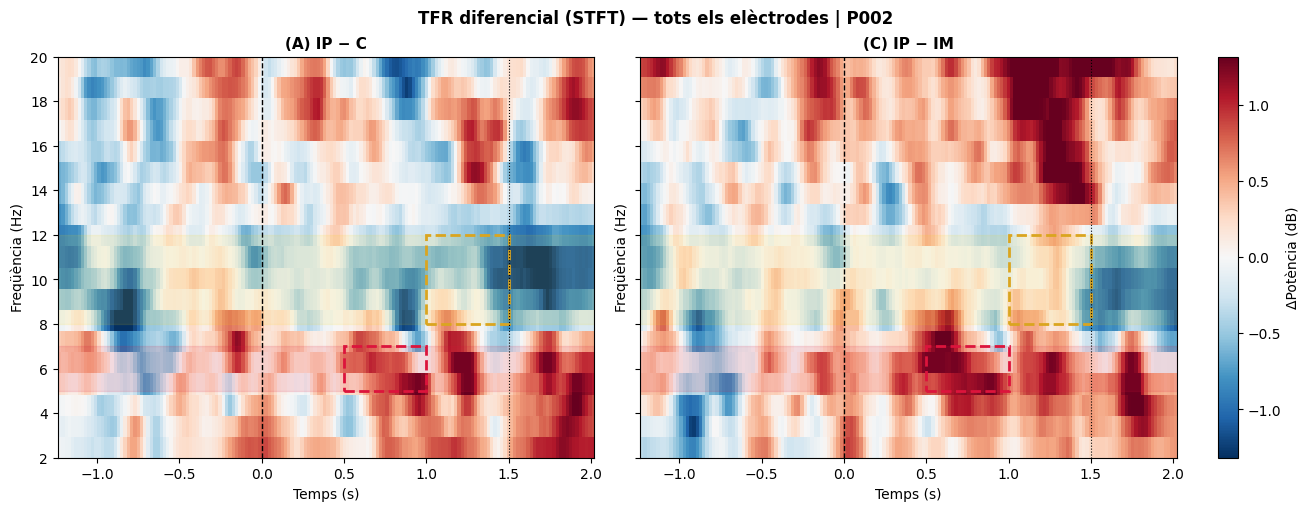

In [43]:
tfr_cond_mean = {}
for cond, ep in epochs_cond.items():
    f, t, mean_db = stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4)
    tfr_cond_mean[cond] = {"freqs": f, "times": t, "mean_db": mean_db}  # (n_freq, n_t)

contrasts = [
    ("A", "Incongruent_Pur", "Congruent", "IP − C"),
    ("C", "Incongruent_Pur", "Incongruent_Mixt", "IP − IM"),
]
raw_diffs = [tfr_cond_mean[ca]["mean_db"] - tfr_cond_mean[cb]["mean_db"] for _, ca, cb, _ in contrasts]
VLIM = float(np.quantile(np.abs(np.concatenate([d.ravel() for d in raw_diffs])), 0.98))
VLIM = max(VLIM, 1e-6)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
for ax, (panel, ca, cb, title), diff in zip(axes, contrasts, raw_diffs):
    t = tfr_cond_mean[ca]["times"]
    f = tfr_cond_mean[ca]["freqs"]
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        extent=[t[0], t[-1], f[0], f[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="nearest",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.axhspan(5, 7, color="crimson", alpha=0.12)
    ax.axhspan(8, 12, color="gold", alpha=0.10)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="goldenrod", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Freqüència (Hz)")
    ax.set_ylim(2, 20)

fig.colorbar(im, ax=axes.ravel().tolist(), location="right", fraction=0.046, pad=0.03, label="ΔPotència (dB)")
fig.suptitle(f"TFR diferencial (STFT) — tots els elèctrodes | {SUBJ}", fontsize=12, fontweight="bold")
plt.savefig(FIGURES_DIR / "tfr_diferencial_stft_tots_electrodes_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### Alpha suppression. Figura 4A
Potència alpha (8–12 Hz) sobre ROI parieto-occipital. Supressió alpha = major activació visual.
Hipòtesi: IP i IM haurien de mostrar més supressió (valors més baixos) que C.

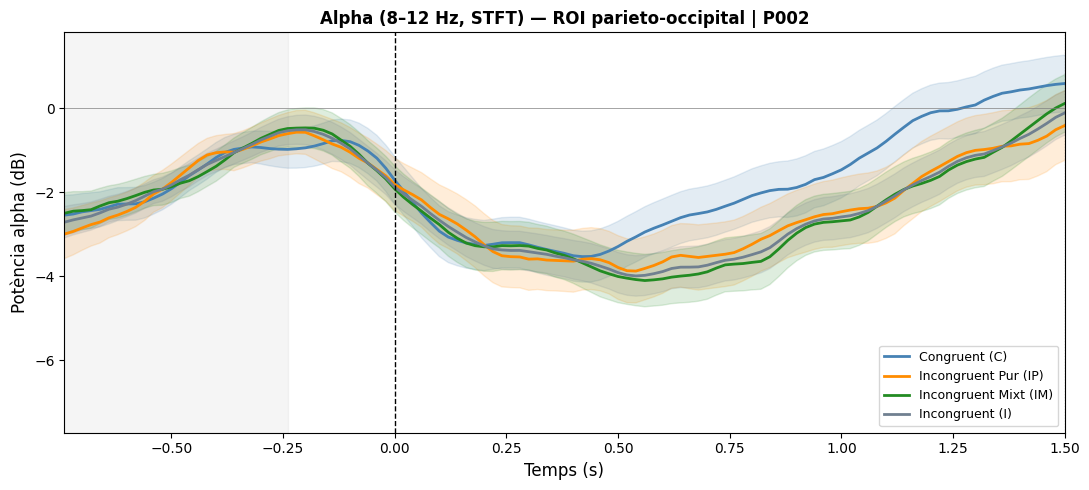

In [44]:
alpha_tc = {}
for cond, ep in epochs_cond.items():
    po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
    if not po_ok:
        continue
    t, mean_ts, sem_ts = stft_band_timecourse(ep, po_ok, band=(8, 12), baseline=BASELINE)
    alpha_tc[cond] = (t, mean_ts, sem_ts)

fig, ax = plt.subplots(figsize=(11, 5))
for cond, (times, power_ts, sem_ts) in alpha_tc.items():
    ax.plot(times, power_ts, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times, power_ts - sem_ts, power_ts + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Potència alpha (dB)", fontsize=12)
ax.set_title(f"Alpha (8–12 Hz, STFT) — ROI parieto-occipital | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alpha_8_12hz_stft_roi_parieto_occipital_individual.png", dpi=300, bbox_inches="tight")
plt.show()

---

## Part 3: Mitjana sobre tots els subjectes

El loop carrega cada subjecte, calcula els TFRs theta i alpha, i acumula els time-courses.
Al final es fa la mitjana entre subjectes i es reploten els mateixos gràfics amb SEM real entre subjectes.

In [46]:
# Funció que processa UN SOL fitxer i retorna els seus resultats.
def processa_un_subjecte(fif_path):
    subj_id = fif_path.stem
    ep_all, ep_cond = load_subject(fif_path)

    # Diccionari local per emmagatzemar la feina d'aquest subjecte
    res = {"subj_id": subj_id, "theta": {}, "alpha": {}, "ga_sum": {}, "freqs": None, "times": None, "times_ga": None}

    try:
        for cond, ep in ep_cond.items():
            if len(ep) == 0:
                continue

            # Theta
            t, ts_theta, _ = stft_band_timecourse(ep, ROI_FRONTAL, band=(5, 7))
            res["theta"][cond] = ts_theta
            if res["times_ga"] is None:
                res["times_ga"] = t

            # Alpha
            po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
            if po_ok:
                _, ts_alpha, _ = stft_band_timecourse(ep, po_ok, band=(8, 12))
                res["alpha"][cond] = ts_alpha

            # TFR Global (ch_block=2 per reduir memòria)
            f_tfr, t_tfr, mean_db = stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=2)

            res["ga_sum"][cond] = mean_db

            if res["freqs"] is None:
                res["freqs"] = f_tfr
                res["times"] = t_tfr

    finally:
        del ep_cond, ep_all
        gc.collect()

    return res


# 2. Processament seqüencial per reduir pics de memòria
fif_files = sorted(DATA_DIR.glob("*.fif"))

all_theta = {cond: [] for cond in COND_EVENTS_CODES}
all_alpha = {cond: [] for cond in COND_EVENTS_CODES}
subjectes_inclosos = []
ga_tfr_sum = {}
ga_tfr_n = {cond: 0 for cond in COND_EVENTS_CODES}
times_ga, freqs_tfr_ga, times_tfr_ga = None, None, None

print(f"Iniciant processament seqüencial de {len(fif_files)} subjectes...")
for ruta in fif_files:
    res = processa_un_subjecte(ruta)
    subjectes_inclosos.append(res["subj_id"])

    if times_ga is None and res["times_ga"] is not None:
        times_ga = res["times_ga"]
    if freqs_tfr_ga is None and res["freqs"] is not None:
        freqs_tfr_ga = res["freqs"]
        times_tfr_ga = res["times"]

    for cond in COND_EVENTS_CODES:
        if cond in res["theta"]:
            all_theta[cond].append(res["theta"][cond])
        if cond in res["alpha"]:
            all_alpha[cond].append(res["alpha"][cond])

        if cond in res["ga_sum"]:
            if cond not in ga_tfr_sum:
                ga_tfr_sum[cond] = np.zeros_like(res["ga_sum"][cond], dtype=np.float32)
            ga_tfr_sum[cond] += res["ga_sum"][cond].astype(np.float32, copy=False)
            ga_tfr_n[cond] += 1

    del res
    gc.collect()

print(f"\nInclosos : {len(subjectes_inclosos)} subjectes.")

Iniciant processament seqüencial de 47 subjectes...

Inclosos : 47 subjectes.


### TFR map diferencial (grand average)
Mateix càlcul que al cas individual, però recorrent els subjectes un a un i acumulant només el mapa TFR mitjà per condició per reduir l'ús de memòria.

In [68]:
# Només mantenir les keys d'interès per a les anàlisis posteriors (C, IP, IM)
all_alpha_cipim = {
    cond: all_alpha[cond] for cond in ["Congruent", "Incongruent_Pur", "Incongruent_Mixt"] if all_alpha[cond]
}
all_theta_cipim = {
    cond: all_theta[cond] for cond in ["Congruent", "Incongruent_Pur", "Incongruent_Mixt"] if all_theta[cond]
}
ga_tfr_sum_cipim = {
    cond: ga_tfr_sum[cond] for cond in ["Congruent", "Incongruent_Pur", "Incongruent_Mixt"] if cond in ga_tfr_sum
}
ga_tfr_n_cipim = {cond: ga_tfr_n[cond] for cond in ["Congruent", "Incongruent_Pur", "Incongruent_Mixt"]}

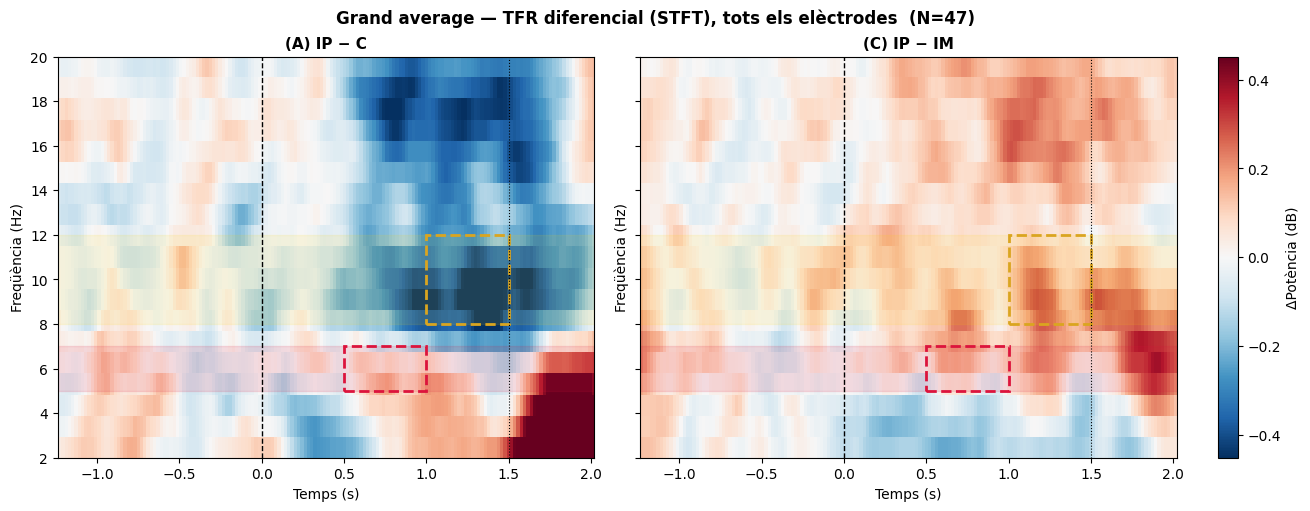

Subjectes contribuents per condició:
  Congruent (C)           : 47
  Incongruent Pur (IP)    : 47
  Incongruent Mixt (IM)   : 47
  Incongruent (I)         : 47
  Errors                  : 36


In [71]:
tfr_ga_mean = {}
for cond, sum_db in ga_tfr_sum_cipim.items():
    if ga_tfr_n_cipim[cond] > 0:
        tfr_ga_mean[cond] = sum_db / ga_tfr_n_cipim[cond]

if freqs_tfr_ga is None or times_tfr_ga is None:
    raise RuntimeError("No s'ha pogut calcular cap TFR per al grand average.")

contrasts = [
    ("A", "Incongruent_Pur", "Congruent", "IP − C"),
    ("C", "Incongruent_Pur", "Incongruent_Mixt", "IP − IM"),
]
raw_diffs = [tfr_ga_mean[ca] - tfr_ga_mean[cb] for _, ca, cb, _ in contrasts]
VLIM = float(np.quantile(np.abs(np.concatenate([d.ravel() for d in raw_diffs])), 0.98))
VLIM = max(VLIM, 1e-6)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
for ax, (panel, ca, cb, title), diff in zip(axes, contrasts, raw_diffs):
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        extent=[times_tfr_ga[0], times_tfr_ga[-1], freqs_tfr_ga[0], freqs_tfr_ga[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="nearest",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.axhspan(5, 7, color="crimson", alpha=0.12)
    ax.axhspan(8, 12, color="gold", alpha=0.10)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="goldenrod", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Freqüència (Hz)")
    ax.set_ylim(2, 20)

fig.colorbar(im, ax=axes.ravel().tolist(), location="right", fraction=0.046, pad=0.03, label="ΔPotència (dB)")

conds_used = sorted({ca for _, ca, _, _ in contrasts} | {cb for _, _, cb, _ in contrasts})
n_tfr = min(ga_tfr_n[c] for c in conds_used)
fig.suptitle(
    f"Grand average — TFR diferencial (STFT), tots els elèctrodes  (N={n_tfr})",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(FIGURES_DIR / "grand_average_tfr_diferencial_stft_tots_electrodes.png", dpi=300, bbox_inches="tight")
plt.show()

print("Subjectes contribuents per condició:")
for cond in COND_EVENTS_CODES:
    print(f"  {LABELS[cond]:24s}: {ga_tfr_n[cond]:2d}")

### Theta power time-course
Cada línia és la mitjana entre subjectes. L'àrea ombrejada és el SEM entre subjectes (no entre trials ni entre canals com en els plots individuals).

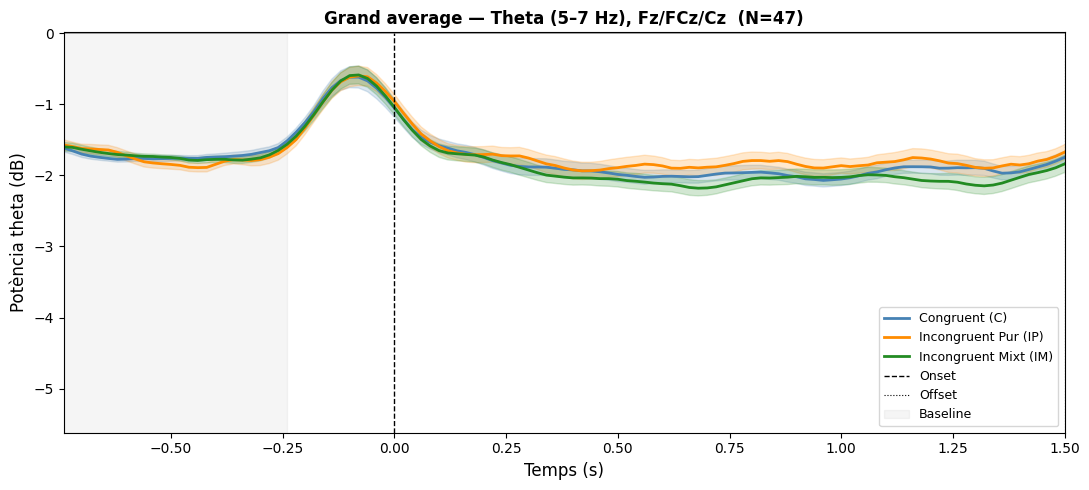

In [72]:
def plot_timecourse_ga(accumulator, times, ylabel, title, output_name):
    """Plot de grand average amb SEM entre subjectes."""
    fig, ax = plt.subplots(figsize=(11, 5))
    n_subj = len(next(iter(accumulator.values())))

    for cond, ts_list in accumulator.items():
        mat = np.array(ts_list)  # (n_subjectes, n_times)
        mean_ga = mat.mean(axis=0)
        sem_ga = mat.std(axis=0) / np.sqrt(len(ts_list))
        ax.plot(times, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
        ax.fill_between(times, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
    ax.set_xlabel("Temps (s)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(f"{title}  (N={n_subj})", fontsize=12, fontweight="bold")
    ax.set_xlim(FULL_TRIAL)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / output_name, dpi=300, bbox_inches="tight")
    plt.show()


plot_timecourse_ga(
    all_theta_cipim,
    times_ga,
    ylabel="Potència theta (dB)",
    title="Grand average — Theta (5–7 Hz), Fz/FCz/Cz",
    output_name="grand_average_theta_5_7hz_roi_frontal.png",
)

### Alpha suppression

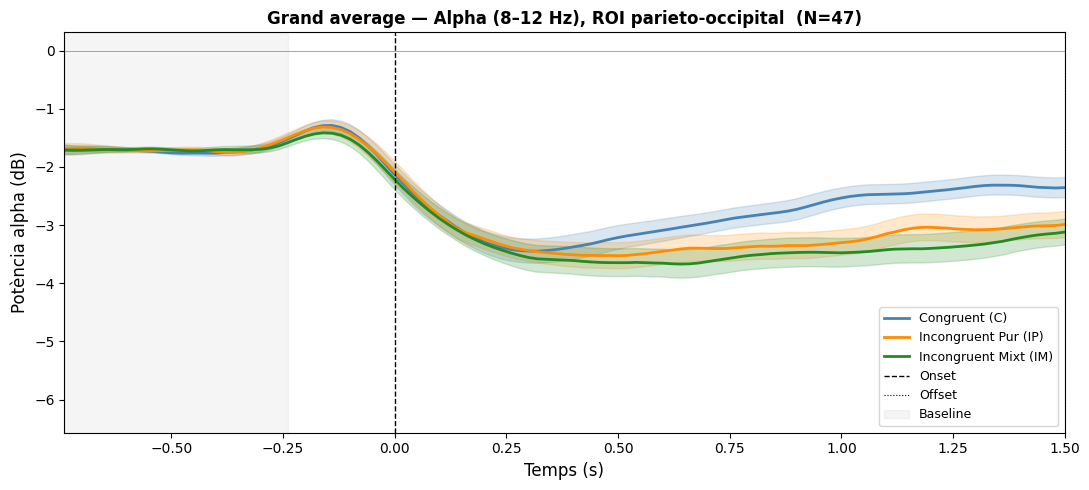

In [74]:
plot_timecourse_ga(
    all_alpha_cipim,
    times_ga,
    ylabel="Potència alpha (dB)",
    title="Grand average — Alpha (8–12 Hz), ROI parieto-occipital",
    output_name="grand_average_alpha_8_12hz_roi_parieto_occipital.png",
)

### ERP (Event-Related Potential)
Mitjana del senyal en el domini temporal. Aquí cal recalcular perquè necessitem les dades en brut (µV), no els TFRs.

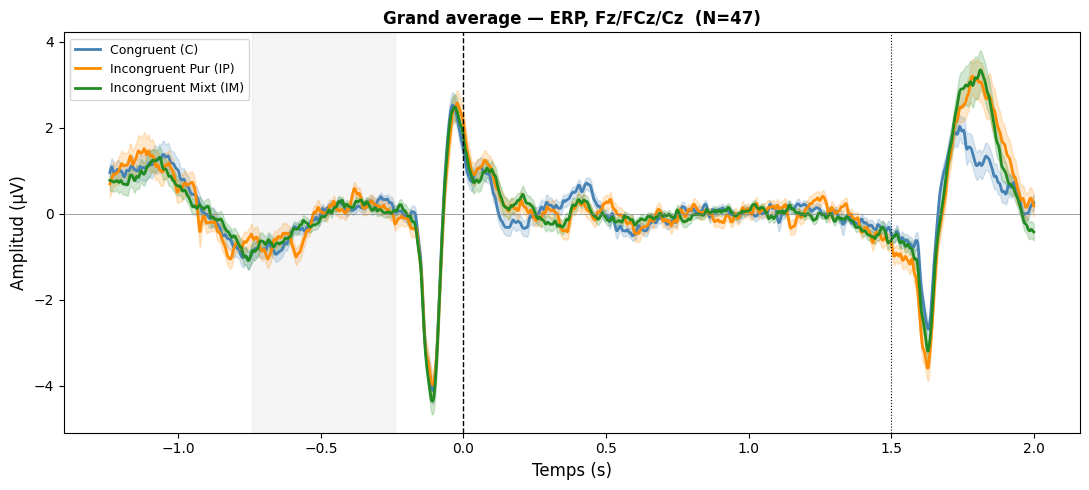

In [82]:
all_erp = {
    cond: [] for cond in COND_EVENTS_CODES if cond not in ["Incongruent", "Errors"]
}  # (n_subjectes, n_times) per canal promig
times_erp = None

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    if subj_id not in subjectes_inclosos:
        continue

    ep_all, ep_cond = load_subject(fif_path)
    if times_erp is None:
        times_erp = ep_all.times
    for cond, ep in ep_cond.items():
        if cond in ["Incongruent", "Errors"]:
            continue
        # Promig sobre trials i sobre canals ROI → (n_times,)
        data = ep.get_data(picks=ROI_FRONTAL).mean(axis=0).mean(axis=0) * 1e6
        all_erp[cond].append(data)

    del ep_cond, ep_all
    gc.collect()

fig, ax = plt.subplots(figsize=(11, 5))
n_subj = len(subjectes_inclosos)
for cond, ts_list in all_erp.items():
    mat = np.array(ts_list)
    mean_ga = mat.mean(axis=0)
    sem_ga = mat.std(axis=0) / np.sqrt(n_subj)
    ax.plot(times_erp, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times_erp, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Amplitud (µV)", fontsize=12)
ax.set_title(f"Grand average — ERP, Fz/FCz/Cz  (N={n_subj})", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "grand_average_erp_fz_fcz_cz.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 4: Cansament al llarg de la sessió

Pregunta de recerca: **Hi ha un cansament visible?**

Responem la pregunta en dues parts separades:
1. **Errors cap al final**: mirem si la taxa d'errors augmenta del primer terç a l'últim terç de trials.
2. **Disminució de l'amplitud ERP**: mirem si l'amplitud ERP disminueix del primer terç a l'últim terç.

Per cada part fem:
- **Anàlisi global** (agregat sobre subjectes)
- **Anàlisi per subjecte** (taula individual de tendències)

In [ ]:
def build_bootstrap_curve(series_list, n_bootstrap=1000, smooth_win=5, min_subjects=5, seed=42):
    """Retorna diccionari amb x, valid, mean, low, high, n_subjects i max_n."""
    if len(series_list) == 0:
        return None

    cleaned = []
    for s in series_list:
        arr = np.asarray(s, dtype=float).ravel()
        if arr.size > 0:
            cleaned.append(arr)

    min_subjects = int(min_subjects)
    if len(cleaned) < max(1, min_subjects):
        return None

    max_n = max(arr.size for arr in cleaned)
    n_subjects = len(cleaned)
    all_values = np.full((n_subjects, max_n), np.nan, dtype=float)
    for i, arr in enumerate(cleaned):
        all_values[i, : arr.size] = arr

    valid_counts = np.sum(~np.isnan(all_values), axis=0)
    has_any = valid_counts > 0
    valid_mask = valid_counts >= min_subjects
    if not np.any(valid_mask):
        return None

    n_bootstrap = int(n_bootstrap)
    rng = np.random.default_rng(seed)
    bootstrap_means = np.full((n_bootstrap, max_n), np.nan, dtype=float)
    for i in range(n_bootstrap):
        sample_idx = rng.integers(0, n_subjects, size=n_subjects)
        sample = all_values[sample_idx, :]
        bootstrap_means[i, has_any] = np.nanmean(sample[:, has_any], axis=0)

    mean_curve = np.nanmean(all_values, axis=0)
    low_ci = np.nanpercentile(bootstrap_means, 2.5, axis=0)
    high_ci = np.nanpercentile(bootstrap_means, 97.5, axis=0)

    if smooth_win is not None and int(smooth_win) > 1:
        win = int(smooth_win)
        kernel = np.ones(win, dtype=float) / float(win)

        def _smooth_nan(arr):
            numer = np.convolve(np.nan_to_num(arr, nan=0.0), kernel, mode="same")
            denom = np.convolve(np.isfinite(arr).astype(float), kernel, mode="same")
            out = np.full_like(arr, np.nan, dtype=float)
            mask = denom > 0
            out[mask] = numer[mask] / denom[mask]
            return out

        mean_curve = _smooth_nan(mean_curve)
        low_ci = _smooth_nan(low_ci)
        high_ci = _smooth_nan(high_ci)

    return {
        "x": np.arange(max_n),
        "valid": valid_mask,
        "mean": mean_curve,
        "low": low_ci,
        "high": high_ci,
        "n_subjects": n_subjects,
        "max_n": max_n,
    }


# Càlcul únic de mètriques de cansament i sèries ERP per subjecte
df_fatigue, subject_amp_series = compute_fatigue_metrics(DATA_DIR)

PART A — Errors cap al final
Global (macro-average per subjecte):
  Error T1 (inici) : 0.0050
  Error T2 (mig)   : 0.0040
  Error T3 (final) : 0.0085
  Delta T3-T1      : +0.004
  Subjectes amb augment d'errors (T3>T1): 13/47
  Test de signe (unilateral, augment): p=0.1917


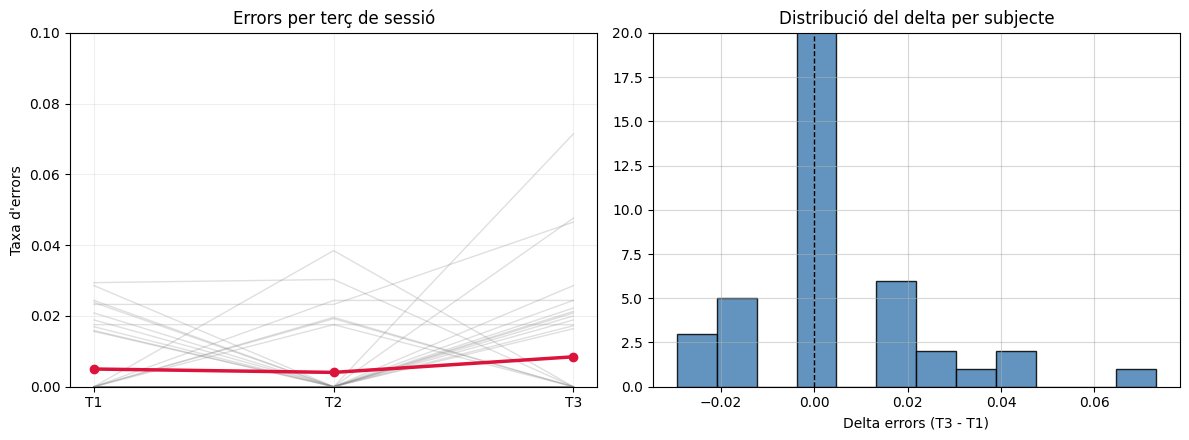

Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\fatiga_errors_subjectes.csv


,subjecte,n_trials,error_t1,error_t2,error_t3,error_delta_t3_t1,error_slope,error_rho,error_p
0,P014,416,0.0000,0.0000,0.0476,0.0732,0.0588,0.1111,0.0235
1,P040,495,0.0000,0.0000,0.0000,0.0408,0.0719,0.1558,0.0005
2,P008,254,0.0000,0.0385,0.0000,0.0400,0.0254,0.0484,0.4421
3,P017,579,0.0000,0.0000,0.0172,0.0351,0.0749,0.1247,0.0026
4,P062,413,0.0000,0.0000,0.0000,0.0244,0.0103,0.0273,0.5801
5,P069,427,0.0233,0.0233,0.0465,0.0244,0.0108,0.0190,0.6959
6,P035,494,0.0000,0.0000,0.0200,0.0204,0.0237,0.0686,0.1280
7,P022,512,0.0000,0.0192,0.0000,0.0196,-0.0138,-0.0343,0.4385
8,P051,529,0.0189,0.0000,0.0189,0.0196,0.0182,0.0369,0.3974
9,P056,520,0.0000,0.0000,0.0000,0.0192,0.0114,0.0753,0.0863


In [109]:
# PART A — Errors cap al final

# Tendència global (macro, mateix pes per subjecte)
global_err_t1 = float(df_fatigue["error_t1"].mean())
global_err_t2 = float(df_fatigue["error_t2"].mean())
global_err_t3 = float(df_fatigue["error_t3"].mean())
global_err_delta = float(df_fatigue["error_delta_t3_t1"].mean())

n_pos = int((df_fatigue["error_delta_t3_t1"] > 0).sum())
n_neg = int((df_fatigue["error_delta_t3_t1"] < 0).sum())
n_nonzero = n_pos + n_neg
p_sign = binomtest(n_pos, n=n_nonzero, p=0.5, alternative="greater").pvalue if n_nonzero > 0 else np.nan

print("PART A — Errors cap al final")
print("Global (macro-average per subjecte):")
print(f"  Error T1 (inici) : {global_err_t1:.4f}")
print(f"  Error T2 (mig)   : {global_err_t2:.4f}")
print(f"  Error T3 (final) : {global_err_t3:.4f}")
print(f"  Delta T3-T1      : {global_err_delta:+.3f}")
print(f"  Subjectes amb augment d'errors (T3>T1): {n_pos}/{len(df_fatigue)}")
print(f"  Test de signe (unilateral, augment): p={p_sign:.4g}")

# Visualització global + trajectòries individuals
x = np.array([1, 2, 3])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

for _, r in df_fatigue.iterrows():
    axes[0].plot(x, [r["error_t1"], r["error_t2"], r["error_t3"]], color="gray", alpha=0.25, linewidth=1)

axes[0].plot(x, [global_err_t1, global_err_t2, global_err_t3], color="crimson", marker="o", linewidth=2.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["T1", "T2", "T3"])
axes[0].set_ylabel("Taxa d'errors")
axes[0].set_title("Errors per terç de sessió")
axes[0].set_ylim(0, 0.1)
axes[0].grid(alpha=0.2)

axes[1].hist(df_fatigue["error_delta_t3_t1"], bins=12, color="steelblue", edgecolor="black", alpha=0.85)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_xlabel("Delta errors (T3 - T1)")
axes[1].set_title("Distribució del delta per subjecte")
axes[1].set_ylim(0, 20)
axes[1].grid(alpha=0.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "errors_cap_al_final_i_distribucio_delta.png", dpi=300, bbox_inches="tight")
plt.show()

# Resum per subjecte
cols_error = [
    "subjecte",
    "n_trials",
    "error_t1",
    "error_t2",
    "error_t3",
    "error_delta_t3_t1",
    "error_slope",
    "error_rho",
    "error_p",
]
df_fatigue[cols_error].sort_values("error_delta_t3_t1", ascending=False).reset_index(drop=True).round(4).to_csv(
    TABLES_DIR / "fatiga_errors_subjectes.csv", index=False
)
print(f"Desat taula: {TABLES_DIR / 'fatiga_errors_subjectes.csv'}")
display(df_fatigue[cols_error].sort_values("error_delta_t3_t1", ascending=False).reset_index(drop=True).round(4))

C:\Users\nils\AppData\Local\Temp\ipykernel_16732\2089904988.py:34: RuntimeWarning: Mean of empty slice
  bootstrap_means[i, has_any] = np.nanmean(sample[:, has_any], axis=0)


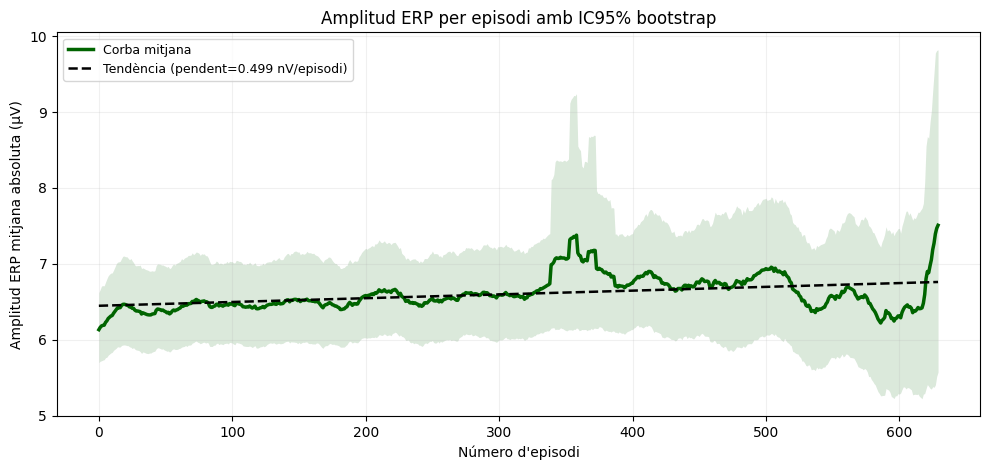

Subjectes inclosos: 47
Episodis màxims: 651
Pendent línia de tendència (tots): 0.499 nV/episodi


In [122]:
# PART B — Amplitud ERP per episodi amb IC95% bootstrap (tots els subjectes)
subject_labels = sorted(subject_amp_series.keys())
subject_series = [subject_amp_series[s] for s in subject_labels]

curve = build_bootstrap_curve(
    series_list=subject_series,
    n_bootstrap=BOOT_N,
    smooth_win=20,
    min_subjects=5,
    seed=42,
)

if curve is None:
    print("No hi ha dades ERP per construir la corba.")
else:
    x = curve["x"]
    valid = curve["valid"]
    mean_s = curve["mean"]
    low_s = curve["low"]
    high_s = curve["high"]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.fill_between(x[valid], low_s[valid], high_s[valid], color="darkgreen", alpha=0.14, linewidth=0)
    ax.plot(x[valid], mean_s[valid], color="darkgreen", linewidth=2.5, label="Corba mitjana")

    x_fit = x[valid].astype(float)
    y_fit_uv = mean_s[valid]
    m_all_uv, b_all_uv = np.polyfit(x_fit, y_fit_uv, 1)
    m_all_nv = m_all_uv * 1000.0
    y_trend = m_all_uv * x_fit + b_all_uv
    ax.plot(
        x_fit,
        y_trend,
        color="black",
        linestyle="--",
        linewidth=1.8,
        label=f"Tendència (pendent={m_all_nv:.3f} nV/episodi)",
    )

    ax.set_xlabel("Número d'episodi")
    ax.set_ylabel("Amplitud ERP mitjana absoluta (µV)")
    ax.set_title("Amplitud ERP per episodi amb IC95% bootstrap")
    ax.grid(alpha=0.18)
    ax.legend(fontsize=9, loc="best")

    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "amplitud_erp_per_episodi_ic95_bootstrap_tots_subjectes.png", dpi=300, bbox_inches="tight"
    )
    plt.show()

    print(f"Subjectes inclosos: {curve['n_subjects']}")
    print(f"Episodis màxims: {curve['max_n']}")
    print(f"Pendent línia de tendència (tots): {m_all_nv:.3f} nV/episodi")

Subjectes seleccionats (augment d'errors T3>T2 o T3>T1): 14
['P014', 'P017', 'P020', 'P021', 'P024', 'P025', 'P031', 'P035', 'P039', 'P041', 'P051', 'P060', 'P068', 'P069']


C:\Users\nils\AppData\Local\Temp\ipykernel_16732\2089904988.py:34: RuntimeWarning: Mean of empty slice
  bootstrap_means[i, has_any] = np.nanmean(sample[:, has_any], axis=0)


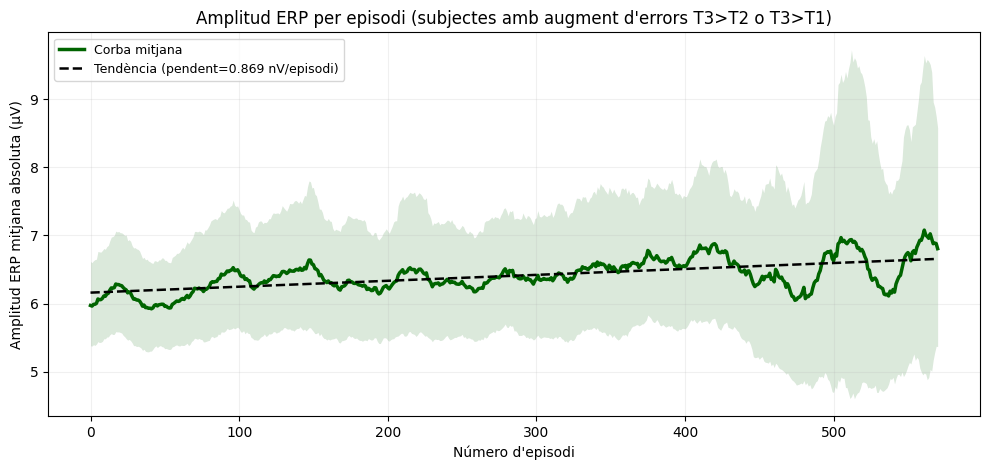

Pendent línia de tendència (subconjunt): 0.869 nV/episodi


In [123]:
# Mateix plot de la cel·la anterior, però només per subjectes amb augment d'errors
# criteri relaxat: T3 > T2 o T3 > T1
selected_subjects = []

for _, r in df_fatigue.iterrows():
    e1 = float(r["error_t1"])
    e2 = float(r["error_t2"])
    e3 = float(r["error_t3"])

    if (e3 > e2) or (e3 > e1):
        selected_subjects.append(r["subjecte"])

print(f"Subjectes seleccionats (augment d'errors T3>T2 o T3>T1): {len(selected_subjects)}")
print(selected_subjects)

subject_series_sig = [subject_amp_series[s] for s in selected_subjects if s in subject_amp_series]

curve_sig = build_bootstrap_curve(
    series_list=subject_series_sig,
    n_bootstrap=BOOT_N,
    smooth_win=20,
    min_subjects=3,
    seed=42,
)

if curve_sig is None:
    print("No hi ha subjectes que compleixin el criteri T3>T2 o T3>T1.")
else:
    x = curve_sig["x"]
    valid = curve_sig["valid"]
    mean_s = curve_sig["mean"]
    low_s = curve_sig["low"]
    high_s = curve_sig["high"]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.fill_between(x[valid], low_s[valid], high_s[valid], color="darkgreen", alpha=0.14, linewidth=0)
    ax.plot(x[valid], mean_s[valid], color="darkgreen", linewidth=2.5, label="Corba mitjana")

    x_fit = x[valid].astype(float)
    y_fit_uv = mean_s[valid]
    m_sel_uv, b_sel_uv = np.polyfit(x_fit, y_fit_uv, 1)
    m_sel_nv = m_sel_uv * 1000.0
    y_trend = m_sel_uv * x_fit + b_sel_uv
    ax.plot(
        x_fit,
        y_trend,
        color="black",
        linestyle="--",
        linewidth=1.8,
        label=f"Tendència (pendent={m_sel_nv:.3f} nV/episodi)",
    )

    ax.set_xlabel("Número d'episodi")
    ax.set_ylabel("Amplitud ERP mitjana absoluta (µV)")
    ax.set_title("Amplitud ERP per episodi (subjectes amb augment d'errors T3>T2 o T3>T1)")
    ax.grid(alpha=0.18)
    ax.legend(fontsize=9, loc="best")

    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "amplitud_erp_per_episodi_subjectes_amb_augment_errors_t3_t2_o_t3_t1.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    print(f"Pendent línia de tendència (subconjunt): {m_sel_nv:.3f} nV/episodi")

Podem confirmar que hi ha un petit augment d'errors a partir de la meitat de la sessió, però no és un augment dramàtic, i es manté bastant estable fins al final del test.

Pel que fa a l'amplitud ERP, definitivament no hi ha una disminució clara com esperava, sinó que de fet augmenta al llarg del temps. Això no confirma que no hi hagi cansament, però podria ser que més activitat cerebral de fet fos un senyal que els subjectes pensaven en altres coses per distreure's o per no avorrir-se. Caldria fer més anàlisis de canals específics o fins i tot experiments nous per explorar aquesta qüestió més a fons.

En els subjectes amb més errors al final que al principi i al mig (primer i segon terç), també es veu un augment d'amplitud ERP (augment de 0.5 nV/episodi vs 0.87 nV/episodi, creix més ràpid quan hi ha més errors), el que reforça la idea que aquest augment no és un senyal de major atenció sinó possiblement de distracció o avorriment.